# Formula 1 Podium Prediction: lab-aligned implementation
**Milestone 1 | reproducible Pandas analysis, sklearn models and Keras network**

One prediction means one driver entering one race. The label is `positionOrder <= 3`.
The cutoff is after qualifying and after the final starting grid is known, immediately
before the Grand Prix starts. Current-race results, points, status, lap times, pit stops
and post-race standings cannot be input features. This is an observational project;
associations and explanations do not establish causation.

**Navigation:** 1. Setup, audit and cleaning; 2. Three relational analyses;
3. Feature evidence and chronological dataset; 4. Models, experiments, explanations
and inference; 5. Analytical report and final verification.

The supplied brief lists three evaluation metrics but later refers to five. We report
ROC-AUC, average precision (AP), trapezoidal PR-AUC, precision, recall and F1, explicitly
distinguishing the two precision-recall summaries. Local LIME and local SHAP are both
included. No performance numbers in this notebook are hand-entered.

## 1. Setup and reproducibility
Use **Run All** after installing the documented requirements. The setup cell checks
dependencies and gives a clear installation message if anything is absent.
Locally, search the working directory and its ancestors for the complete `Dataset/`
folder, including when this notebook is opened from `Deliverables/1- Notebook/`.
On Kaggle, discover the complete 14-table archive under `/kaggle/input`.
An explicit `F1_DATA_DIR` environment variable overrides discovery. All output goes to
`output/` or `/kaggle/working/output/`. Raw CSVs are never overwritten.

In [1]:
import importlib.util
_required = {'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib',
             'seaborn': 'seaborn', 'sklearn': 'scikit-learn', 'tensorflow': 'tensorflow',
             'shap': 'shap', 'lime': 'lime', 'joblib': 'joblib', 'reportlab': 'reportlab',
             'PIL': 'pillow', 'pygments': 'pygments', 'fitz': 'pymupdf'}
_missing = [package for module, package in _required.items() if importlib.util.find_spec(module) is None]
if _missing:
    raise ModuleNotFoundError('Missing dependencies: ' + ', '.join(_missing) +
        '. Install requirements.txt in this kernel environment, then Restart and Run All. '
        'On Kaggle, install the missing packages in the environment before this notebook.')
from pathlib import Path
import os, sys, json, hashlib, platform, importlib.metadata, warnings
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 170, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
sns.set_theme(style='whitegrid', palette='colorblind')

def locate_data():
    required = ['circuits', 'constructors', 'constructor_results', 'constructor_standings',
                'drivers', 'driver_standings', 'races', 'results', 'qualifying', 'lap_times',
                'pit_stops', 'sprint_results', 'seasons', 'status']
    configured = os.environ.get('F1_DATA_DIR')
    if configured:
        candidate = Path(configured).expanduser().resolve()
        missing = [name + '.csv' for name in required if not (candidate / (name + '.csv')).is_file()]
        if missing:
            raise FileNotFoundError('F1_DATA_DIR is missing required CSVs: ' + ', '.join(missing))
        return candidate
    working = Path.cwd().resolve()
    candidates = [working]
    for parent in [working, *working.parents]:
        candidates.extend([parent / 'Dataset', parent / 'dataset'])
    if Path('/kaggle/input').is_dir():
        candidates.extend(p.parent for p in sorted(Path('/kaggle/input').rglob('results.csv')))
    seen = set()
    for candidate in candidates:
        candidate = candidate.resolve()
        if candidate in seen:
            continue
        seen.add(candidate)
        if all((candidate / (name + '.csv')).is_file() for name in required):
            return candidate
    raise FileNotFoundError('No complete F1 archive found. Place all 14 CSVs in the project Dataset/ '
                            'folder, attach the archive on Kaggle, or set F1_DATA_DIR.')

DATA = locate_data()
OUT = Path('/kaggle/working/output') if Path('/kaggle/working').exists() else Path('output')
FIG = OUT / 'figures'
for directory in [OUT, FIG, OUT / 'tables', OUT / 'models', OUT / 'pdf']:
    directory.mkdir(parents=True, exist_ok=True)
FIG_CAPTIONS = {}
def savefig(name, caption=None):
    filename = name if name.endswith('.png') else name + '.png'
    plt.gcf().savefig(FIG / filename, bbox_inches='tight', facecolor='white')
    FIG_CAPTIONS[filename] = caption or filename.replace('.png', '').replace('_', ' ')
    plt.show()
    plt.close()

TABLE_NAMES = ['circuits', 'constructors', 'constructor_results', 'constructor_standings',
               'drivers', 'driver_standings', 'races', 'results', 'qualifying', 'lap_times',
               'pit_stops', 'sprint_results', 'seasons', 'status']
assert all((DATA / f'{t}.csv').exists() for t in TABLE_NAMES), 'Dataset is missing required tables.'
raw_hashes = {t: hashlib.sha256((DATA / f'{t}.csv').read_bytes()).hexdigest() for t in TABLE_NAMES}
versions = {m: importlib.metadata.version(m) for m in
            ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'tensorflow', 'keras', 'shap', 'lime', 'reportlab']}
display(pd.Series({'Python': platform.python_version(), **versions}, name='version').to_frame())
(OUT / 'environment.json').write_text(json.dumps(versions, indent=2))
(OUT / 'raw_hashes_before.json').write_text(json.dumps(raw_hashes, indent=2))

,version
Python,3.12.14
pandas,2.3.0
numpy,2.3.0
scikit-learn,1.7.0
matplotlib,3.10.8
tensorflow,2.20.0
keras,3.15.1
shap,0.53.0
lime,0.2.0.1
reportlab,4.4.3


1188

### 1.1 Initial EDA: inspect the data programmatically before cleaning
Load strings with automatic missing-value conversion disabled so the sentinel audit
counts the literal `\N` rather than silently losing it. Report dimensions, duplicate
rows, sentinel counts and empty strings for every table. These are implemented checks,
not conclusions from manually opening a few rows.

,table,rows,columns,sentinel_cells,blank_cells,duplicate_full_rows
0,circuits,77,9,0,0,0
1,constructors,212,5,0,0,0
2,constructor_results,12625,5,12608,0,0
3,constructor_standings,13391,7,0,0,0
4,drivers,861,9,1559,0,0
5,driver_standings,34863,7,0,0,0
6,races,1125,18,11349,0,0
7,results,26759,18,122887,0,0
8,qualifying,10494,9,11600,68,0
9,lap_times,589081,6,0,0,0


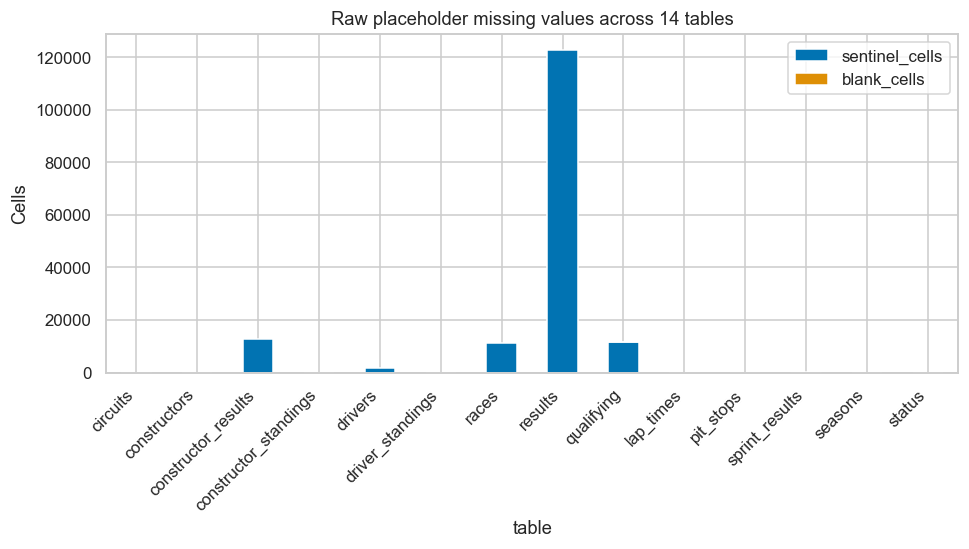

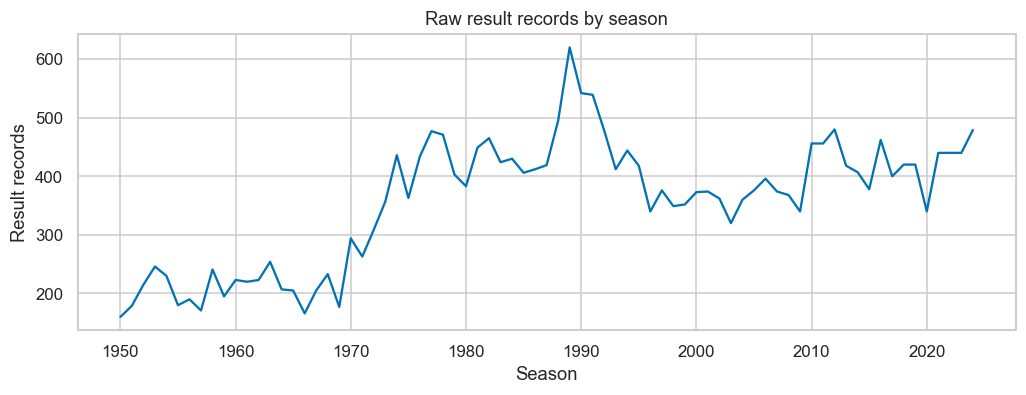

In [2]:
raw_tables = {t: pd.read_csv(DATA / f'{t}.csv', dtype=str, keep_default_na=False) for t in TABLE_NAMES}
raw_audit = pd.DataFrame([{'table': t, 'rows': len(df), 'columns': len(df.columns),
                         'sentinel_cells': int(df.eq('\\N').sum().sum()),
                         'blank_cells': int(df.apply(lambda s: s.str.fullmatch(r'\s*')).sum().sum()),
                         'duplicate_full_rows': int(df.duplicated().sum())}
                        for t, df in raw_tables.items()])
display(raw_audit)
raw_audit.to_csv(OUT / 'tables' / 'raw_audit.csv', index=False)
fig, ax = plt.subplots(figsize=(10, 4))
raw_audit.set_index('table')[['sentinel_cells', 'blank_cells']].plot.bar(ax=ax, stacked=True)
ax.set(ylabel='Cells', title='Raw placeholder missing values across 14 tables')
plt.xticks(rotation=45, ha='right')
savefig('01_raw_placeholders', 'Initial EDA: literal sentinel and blank counts before cleaning.')

raw_results = raw_tables['results']
raw_dates = raw_tables['races'][['raceId', 'year']].copy()
raw_year_counts = raw_results.merge(raw_dates, on='raceId', validate='many_to_one').groupby('year').size()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(raw_year_counts.index.astype(int), raw_year_counts.values)
ax.set(xlabel='Season', ylabel='Result records', title='Raw result records by season')
savefig('02_raw_season_volume', 'Initial EDA: calendar length and entry counts change across seasons.')

### 1.2 Cleaning policy and semantic types
Convert `\N` and blanks into missing values on **copies**. IDs and counts become
nullable integers; measurement columns become numeric; race/session dates and driver
birth dates become datetime objects. Race clock times remain clock strings.
Durations such as `1:23.456` become seconds; race result `+5.432` means a gap, not an
elapsed race duration, so it is intentionally not coerced as a total duration.
Qualifying Q2/Q3 absence frequently means elimination, rather than a corrupt record.
Those values remain missing and are audited; they are not filled with zero lap times.

In [3]:
def duration_seconds(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip()
    if not text or text.startswith('+'):
        return np.nan
    try:
        pieces = [float(p) for p in text.split(':')]
        if len(pieces) > 3 or any(p < 0 for p in pieces):
            return np.nan
        return sum(p * (60 ** i) for i, p in enumerate(reversed(pieces)))
    except ValueError:
        return np.nan

int_cols = {'year', 'round', 'number', 'grid', 'position', 'positionOrder', 'laps',
            'fastestLap', 'rank', 'wins', 'lap', 'stop', 'milliseconds'}
float_cols = {'points', 'fastestLapSpeed', 'lat', 'lng', 'alt'}
tables, coercion_log = {}, []
for t, raw in raw_tables.items():
    df = raw.replace({'\\N': np.nan, '': np.nan}).replace(r'^\s*$', np.nan, regex=True).copy(deep=True)
    for col in df.columns:
        if col.endswith('Id') or col in int_cols or col in float_cols:
            before = df[col].notna()
            numeric = pd.to_numeric(df[col], errors='coerce')
            newly_missing = int((before & numeric.isna()).sum())
            coercion_log.append({'table': t, 'column': col, 'invalid_nonmissing_values': newly_missing})
            df[col] = numeric.astype('Int64') if col.endswith('Id') or col in int_cols else numeric
        elif col == 'dob' or col == 'date' or col.endswith('_date'):
            before = df[col].notna()
            df[col] = pd.to_datetime(df[col], errors='coerce')
            coercion_log.append({'table': t, 'column': col,
                                 'invalid_nonmissing_values': int((before & df[col].isna()).sum())})
    duration_cols = {'qualifying': ['q1', 'q2', 'q3'], 'lap_times': ['time'],
                     'pit_stops': ['duration'], 'results': ['fastestLapTime'],
                     'sprint_results': ['fastestLapTime']}.get(t, [])
    for col in duration_cols:
        converted = df[col].map(duration_seconds)
        coercion_log.append({'table': t, 'column': col,
                             'invalid_nonmissing_values': int((df[col].notna() & converted.isna()).sum())})
        df[col + '_seconds'] = converted
    tables[t] = df
coercions = pd.DataFrame(coercion_log)
display(coercions.loc[coercions.invalid_nonmissing_values.gt(0)])
coercions.to_csv(OUT / 'tables' / 'typing_audit.csv', index=False)
assert coercions.invalid_nonmissing_values.sum() == 0, 'Investigate unexpected parsing loss.'
semantic_types = pd.DataFrame([
    {'table': table, 'column': column, 'dtype': str(frame[column].dtype),
     'observed_values': int(frame[column].notna().sum()),
     'missing_values': int(frame[column].isna().sum())}
    for table, frame in tables.items() for column in frame.columns
])
semantic_types.to_csv(OUT / 'tables' / 'semantic_types.csv', index=False)

,table,column,invalid_nonmissing_values


### 1.3 Relational integrity and duplicate-driver grain
Validate table primary keys and every supplied ID relationship, including race season
references. Merge validation prevents silently multiplying rows during joins.
Some historical result records describe shared drives or alternate entries.
For duplicate `(raceId, driverId)` pairs, retain the row with the smallest **positive
grid position**, then the smallest `resultId`; if all grids are zero/missing, retain
the smallest `resultId`. This deterministic rule uses entry/grid metadata, not the
podium label or finishing position. It is an imperfect proxy for the original entry;
we export every affected row and compare label counts before/after rather than hiding
the historical ambiguity. All analyses use this declared driver-race grain.

,table,keys,null_key_rows,duplicate_key_rows
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,constructor_results,constructorResultsId,0,0
3,constructor_standings,constructorStandingsId,0,0
4,drivers,driverId,0,0
5,driver_standings,driverStandingsId,0,0
6,races,raceId,0,0
7,results,resultId,0,0
8,qualifying,qualifyId,0,0
9,lap_times,"raceId,driverId,lap",0,0


,table,foreign_key,parent,null_references,unmatched_references
0,constructor_results,raceId,races,0,0
1,constructor_results,constructorId,constructors,0,0
2,constructor_standings,raceId,races,0,0
3,constructor_standings,constructorId,constructors,0,0
4,driver_standings,raceId,races,0,0
5,driver_standings,driverId,drivers,0,0
6,races,circuitId,circuits,0,0
7,races,year,seasons,0,0
8,results,raceId,races,0,0
9,results,driverId,drivers,0,0


**Start-evidence audit:** 24 unique driver-race records have withdrawal/nonqualifying labels despite positive recorded laps. They remain starts. Zero-lap W/F or explicit nonstart labels are excluded; N is unclassified, and zero grid/laps alone does not prove a DNS. This retrospective rule is used only for descriptive counts and earlier-race histories, never as a current-race predictor.

,table,rows,columns,missing_cells,duplicate_full_rows
0,circuits,77,9,0,0
1,constructors,212,5,0,0
2,constructor_results,12625,5,12608,0
3,constructor_standings,13391,7,0,0
4,drivers,861,9,1559,0
5,driver_standings,34863,7,0,0
6,races,1125,18,11349,0
7,results,26759,19,141394,0
8,qualifying,10494,12,23336,0
9,lap_times,589081,7,0,0


,stage,rows,podium_rate
0,Raw result records,26759,0.126948
1,Unique driver-race rows,26668,0.126669


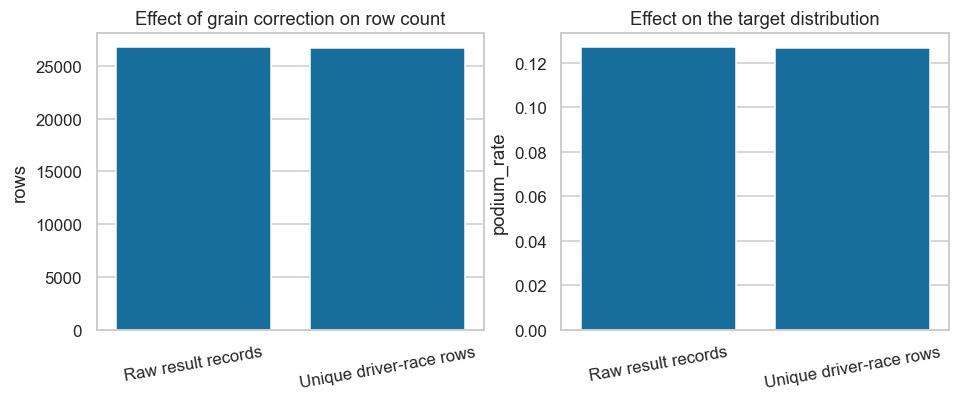

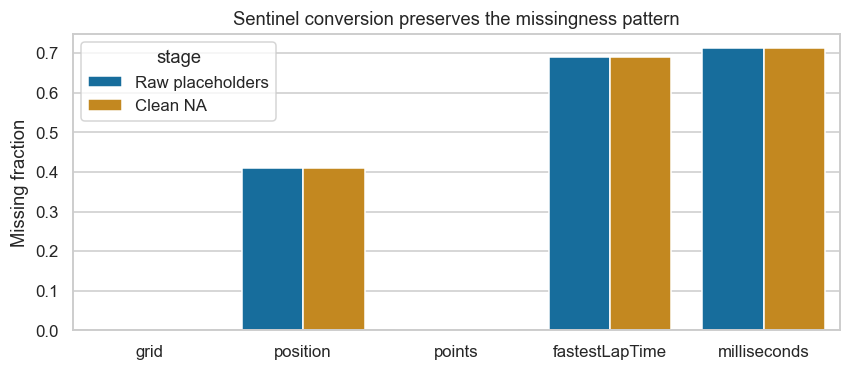

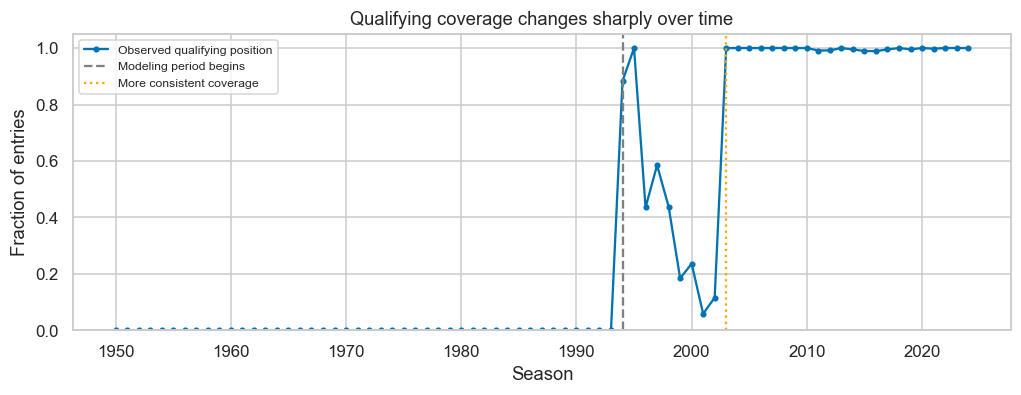

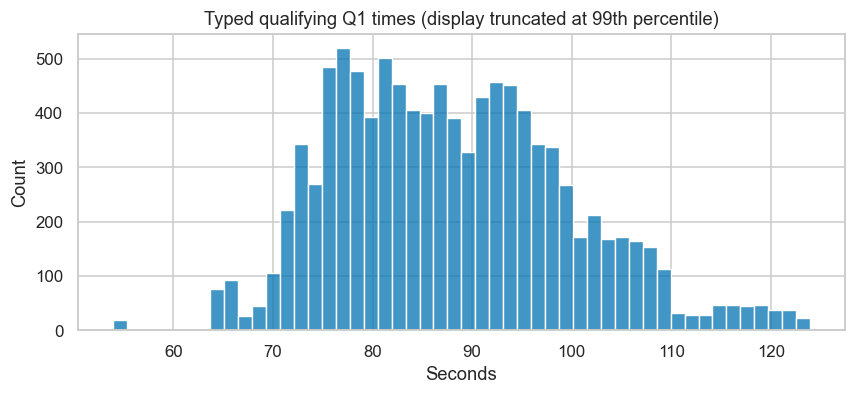

,count,mean,std,min,25%,50%,75%,max
grid,26759.0,11.134796,7.20286,0.0,5.0,11.0,17.0,34.0
positionOrder,26759.0,12.794051,7.665951,1.0,6.0,12.0,18.0,39.0
points,26759.0,1.987632,4.351209,0.0,0.0,0.0,2.0,50.0
laps,26759.0,46.301768,29.496557,0.0,23.0,53.0,66.0,200.0


**Audit conclusion:** 26,759 result records become 26,668 unique driver-race rows after removing 91 extra rows across 85 pairs. Podium prevalence changes from 12.69% to 12.67%. All declared primary and foreign key checks pass. Qualifying starts in 1994, but 1996-2002 coverage is incomplete; missingness is retained and modeled explicitly.

In [4]:
PRIMARY_KEYS = {'circuits': ['circuitId'], 'constructors': ['constructorId'],
                'constructor_results': ['constructorResultsId'],
                'constructor_standings': ['constructorStandingsId'], 'drivers': ['driverId'],
                'driver_standings': ['driverStandingsId'], 'races': ['raceId'],
                'results': ['resultId'], 'qualifying': ['qualifyId'],
                'lap_times': ['raceId', 'driverId', 'lap'],
                'pit_stops': ['raceId', 'driverId', 'stop'], 'sprint_results': ['resultId'],
                'seasons': ['year'], 'status': ['statusId']}
key_audit_rows = []
for t, keys in PRIMARY_KEYS.items():
    df = tables[t]
    key_audit_rows.append({'table': t, 'keys': ','.join(keys),
                          'null_key_rows': int(df[keys].isna().any(axis=1).sum()),
                          'duplicate_key_rows': int(df.duplicated(keys).sum())})
key_audit = pd.DataFrame(key_audit_rows)
assert key_audit[['null_key_rows', 'duplicate_key_rows']].to_numpy().sum() == 0
foreign_rows = []
for t, df in tables.items():
    for col, parent in {'raceId': 'races', 'driverId': 'drivers', 'constructorId': 'constructors',
                        'circuitId': 'circuits', 'statusId': 'status', 'year': 'seasons'}.items():
        if col in df and t != parent:
            unmatched = df[col].notna() & ~df[col].isin(tables[parent][col])
            foreign_rows.append({'table': t, 'foreign_key': col, 'parent': parent,
                                 'null_references': int(df[col].isna().sum()),
                                 'unmatched_references': int(unmatched.sum())})
fk_audit = pd.DataFrame(foreign_rows)
assert fk_audit[['null_references', 'unmatched_references']].to_numpy().sum() == 0
display(key_audit)
display(fk_audit)
key_audit.to_csv(OUT / 'tables' / 'primary_key_audit.csv', index=False)
fk_audit.to_csv(OUT / 'tables' / 'foreign_key_audit.csv', index=False)

rr = tables['results'].copy()
rr['_grid_priority'] = rr.grid.where(rr.grid.gt(0), 10_000).fillna(10_000)
rr = rr.sort_values(['raceId', 'driverId', '_grid_priority', 'resultId'], kind='stable')
rr['_kept'] = ~rr.duplicated(['raceId', 'driverId'])
dedup_audit = rr.loc[rr.duplicated(['raceId', 'driverId'], keep=False)].drop(columns='_grid_priority')
dedup_audit = dedup_audit.merge(tables['races'][['raceId', 'year']], on='raceId', validate='many_to_one')
dedup_audit.to_csv(OUT / 'tables' / 'duplicate_driver_race_audit.csv', index=False)
results_unique = rr.loc[rr._kept].drop(columns=['_grid_priority', '_kept']).copy()
assert not results_unique.duplicated(['raceId', 'driverId']).any()
results_unique['y'] = results_unique.positionOrder.le(3).astype(int)
race_lookup = tables['races']

# A withdrawal/nonqualifying label is not sufficient evidence of a DNS when
# recorded laps show participation. Keep the same rule in analyses and histories.
START_EXCLUSION_STATUSES = {'Withdrew', 'Did not qualify', 'Did not prequalify', '107% Rule'}

def classify_race_starts(frame, status_column):
    positive_laps = pd.to_numeric(frame['laps'], errors='coerce').gt(0)
    exclusion_label = (frame['positionText'].astype('string').str.strip().str.upper().isin(['W', 'F'])
                       | frame[status_column].isin(START_EXCLUSION_STATUSES))
    return positive_laps | ~exclusion_label

start_evidence = results_unique.merge(tables['status'], on='statusId', validate='many_to_one')
start_evidence['started'] = classify_race_starts(start_evidence, 'status')
start_evidence['exclusion_label'] = (
    start_evidence.positionText.astype('string').str.strip().str.upper().isin(['W', 'F'])
    | start_evidence.status.isin(START_EXCLUSION_STATUSES))
start_conflicts = start_evidence.loc[
    start_evidence.exclusion_label & start_evidence.laps.gt(0),
    ['raceId', 'driverId', 'constructorId', 'grid', 'laps', 'positionText', 'status', 'started']
].merge(tables['races'][['raceId', 'year', 'date', 'name']], on='raceId', validate='many_to_one')
assert start_conflicts.started.all()
start_conflicts.to_csv(OUT / 'tables' / 'start_classification_conflicts.csv', index=False)
display(Markdown(f"**Start-evidence audit:** {len(start_conflicts)} unique driver-race records "
                 "have withdrawal/nonqualifying labels despite positive recorded laps. "
                 "They remain starts. Zero-lap W/F or explicit nonstart labels are excluded; "
                 "N is unclassified, and zero grid/laps alone does not prove a DNS. "
                 "This retrospective rule is used only for descriptive counts and earlier-race histories, "
                 "never as a current-race predictor."))
after_audit = pd.DataFrame([{'table': t, 'rows': len(df), 'columns': len(df.columns),
                            'missing_cells': int(df.isna().sum().sum()),
                            'duplicate_full_rows': int(df.duplicated().sum())}
                           for t, df in tables.items()])
display(after_audit)
after_audit.to_csv(OUT / 'tables' / 'clean_audit.csv', index=False)
before_rate = tables['results'].positionOrder.le(3).mean()
after_rate = results_unique.y.mean()
clean_comparison = pd.DataFrame({'stage': ['Raw result records', 'Unique driver-race rows'],
                                'rows': [len(tables['results']), len(results_unique)],
                                'podium_rate': [before_rate, after_rate]})
clean_comparison.to_csv(OUT / 'tables' / 'cleaning_comparison.csv', index=False)
display(clean_comparison)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.barplot(data=clean_comparison, x='stage', y='rows', ax=axes[0])
sns.barplot(data=clean_comparison, x='stage', y='podium_rate', ax=axes[1])
for ax in axes:
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=10)
axes[0].set_title('Effect of grain correction on row count')
axes[1].set_title('Effect on the target distribution')
savefig('03_duplicate_cleaning_effect', 'Before/after EDA: deterministic driver-race deduplication and target prevalence.')

missing_compare = []
for col in ['grid', 'position', 'points', 'fastestLapTime', 'milliseconds']:
    missing_compare.append({'field': col, 'stage': 'Raw placeholders',
                            'fraction': raw_tables['results'][col].isin(['\\N', '']).mean()})
    missing_compare.append({'field': col, 'stage': 'Clean NA',
                            'fraction': tables['results'][col].isna().mean()})
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.barplot(data=pd.DataFrame(missing_compare), x='field', y='fraction', hue='stage', ax=ax)
ax.set(title='Sentinel conversion preserves the missingness pattern', ylabel='Missing fraction', xlabel='')
savefig('04_missingness_cleaning_effect', 'Before/after EDA: parsing changes representation, without fabricating observed values.')

qcoverage = results_unique[['raceId', 'driverId']].merge(
    tables['qualifying'][['raceId', 'driverId', 'position']], on=['raceId', 'driverId'],
    how='left', validate='one_to_one').merge(tables['races'][['raceId', 'year']], on='raceId', validate='many_to_one')
coverage = qcoverage.groupby('year').agg(entries=('driverId', 'size'),
                                        qualifying_observed=('position', 'count'))
coverage['qualifying_coverage'] = coverage.qualifying_observed / coverage.entries
coverage.to_csv(OUT / 'tables' / 'qualifying_coverage.csv')
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(coverage.index, coverage.qualifying_coverage, marker='.', label='Observed qualifying position')
ax.axvline(1994, color='grey', ls='--', label='Modeling period begins')
ax.axvline(2003, color='orange', ls=':', label='More consistent coverage')
ax.set(xlabel='Season', ylabel='Fraction of entries', ylim=(0, 1.05), title='Qualifying coverage changes sharply over time')
ax.legend(loc='upper left', fontsize=8)
savefig('05_qualifying_coverage', 'Coverage evidence: historical qualifying absence motivates period restriction and missing-value indicators.')

fig, ax = plt.subplots(figsize=(9, 3.5))
dur = tables['qualifying']['q1_seconds'].dropna()
sns.histplot(dur.loc[dur.le(dur.quantile(.99))], bins=50, ax=ax)
ax.set(title='Typed qualifying Q1 times (display truncated at 99th percentile)', xlabel='Seconds')
savefig('06_typed_qualifying_duration', 'Semantic typing: lap-time strings converted to seconds; tail truncation is display-only, no raw records removed.')

# Lab 1's describe() provides observed-data range evidence after semantic typing.
# These are audit summaries; no imputation has been performed at this stage.
clean_numeric_summary = tables['results'][['grid', 'positionOrder', 'points', 'laps']].describe().T
clean_numeric_summary.to_csv(OUT / 'tables' / 'clean_numeric_summary.csv')
display(clean_numeric_summary)

data_summary = {'raw_results': len(tables['results']), 'unique_results': len(results_unique),
                'duplicates_removed': len(tables['results']) - len(results_unique),
                'duplicate_pairs': dedup_audit[['raceId', 'driverId']].drop_duplicates().shape[0],
                'podium_rate': float(after_rate), 'min_year': int(tables['races'].year.min()),
                'max_year': int(tables['races'].year.max()), 'foreign_key_errors': 0}
display(Markdown(f"**Audit conclusion:** {data_summary['raw_results']:,} result records become "
                 f"{data_summary['unique_results']:,} unique driver-race rows after removing "
                 f"{data_summary['duplicates_removed']} extra rows across {data_summary['duplicate_pairs']} pairs. "
                 f"Podium prevalence changes from {before_rate:.2%} to {after_rate:.2%}. "
                 "All declared primary and foreign key checks pass. Qualifying starts in 1994, "
                 "but 1996-2002 coverage is incomplete; missingness is retained and modeled explicitly."))

## 2. Relational analyses: three questions, three explicit denominators

These analyses are descriptive. A join can create plausible but wrong answers if
its grain changes, so every enrichment below validates its cardinality. The
cleaned result grain is one driver at one race. Race outcomes are used here to
answer historical questions; the predictive section separately restricts every
feature to information available before the race.

In [5]:
from IPython.display import display, Markdown
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

a_table_dir = OUT / "tables"
a_table_dir.mkdir(parents=True, exist_ok=True)
analyses_summary = {}
analysis_figures = []

def a_wilson(successes, totals, z=1.96):
    """95% Wilson intervals; descriptive binomial uncertainty, not causal CIs."""
    a_s = np.asarray(successes, dtype=float)
    a_n = np.asarray(totals, dtype=float)
    a_p = np.divide(a_s, a_n, out=np.full_like(a_s, np.nan), where=a_n > 0)
    a_d = 1 + z ** 2 / a_n
    a_c = (a_p + z ** 2 / (2 * a_n)) / a_d
    a_h = z * np.sqrt(a_p * (1 - a_p) / a_n + z ** 2 / (4 * a_n ** 2)) / a_d
    return a_c - a_h, a_c + a_h

def a_rates(a_frame, a_groups, a_outcome="podium"):
    a_result = a_frame.groupby(a_groups, observed=True, dropna=False)[a_outcome].agg(
        podiums="sum", starts="size"
    ).reset_index()
    a_result["rate"] = a_result["podiums"] / a_result["starts"]
    a_result["ci_low"], a_result["ci_high"] = a_wilson(
        a_result["podiums"], a_result["starts"]
    )
    return a_result

# Select and rename dimension columns BEFORE joining to prevent accidental use of
# similarly named race/circuit/constructor fields or automatic suffixes.
a_races = race_lookup[["raceId", "year", "round", "circuitId", "date"]].copy()
a_circuits = tables["circuits"][["circuitId", "name", "country"]].rename(
    columns={"name": "circuit_name", "country": "circuit_country"}
)
a_drivers = tables["drivers"][["driverId", "nationality"]].copy()
a_constructors = tables["constructors"][["constructorId", "name"]].rename(
    columns={"name": "constructor_name"}
)
a_statuses = tables["status"][["statusId", "status"]].rename(
    columns={"status": "race_status"}
)
a_results = results_unique[[
    "raceId", "driverId", "constructorId", "grid", "positionOrder",
    "positionText", "statusId", "laps"
]].copy()
a_results["podium"] = pd.to_numeric(a_results["positionOrder"], errors="coerce").le(3).astype(int)
assert not a_results.duplicated(["raceId", "driverId"]).any()
assert a_results["positionOrder"].notna().all(), "Unknown outcome must not be counted as a non-podium."
a_joined = a_results.merge(a_races, on="raceId", how="left", validate="many_to_one")
a_joined = a_joined.merge(a_circuits, on="circuitId", how="left", validate="many_to_one")
a_joined = a_joined.merge(a_drivers, on="driverId", how="left", validate="many_to_one")
a_joined = a_joined.merge(a_constructors, on="constructorId", how="left", validate="many_to_one")
a_joined = a_joined.merge(a_statuses, on="statusId", how="left", validate="many_to_one")
assert len(a_joined) == len(a_results)
assert a_joined[["year", "circuit_name", "constructor_name", "race_status"]].notna().all().all()

### Q1. Which circuits convert front-row positions into podiums, and did ranks change after 2014?

Qualifying position 1–2 and final starting grid position 1–2 are different
exposures: penalties and sprint formats can move drivers between them. We
compare both definitions on the **same races**, retaining races with two observed
qualifying front-row starters, two observed grid front-row starters, and result
records for all of them. W/F and explicit withdrawal/nonqualifying labels exclude
an entry only when it has no positive recorded laps. Positive laps establish a
start even if its archive label says Withdrew; conflicts are exported in section 1.
`positionText=F` means failed to qualify; `N` means unclassified and remains a
start. Classification status alone must not turn an actual starter into a DNS.
This avoids counting a front-row DNS as a race start. The window begins in 1994 because earlier qualifying
rows are unavailable. Before 2014 means 1994–2013; after the hybrid-era change
means 2014–2024. Circuit identity follows `circuitId`, not a changing race name.

Rankings require at least 20 driver starts (10 races) in a circuit/era/definition
cell. Smaller cells remain in the exported table but do not determine ranks.
Wilson bars show sampling uncertainty. Driver starts within a race are
dependent, so these bars are descriptive and do not establish significant
differences. Track calendars, weather, cars and field composition also change.

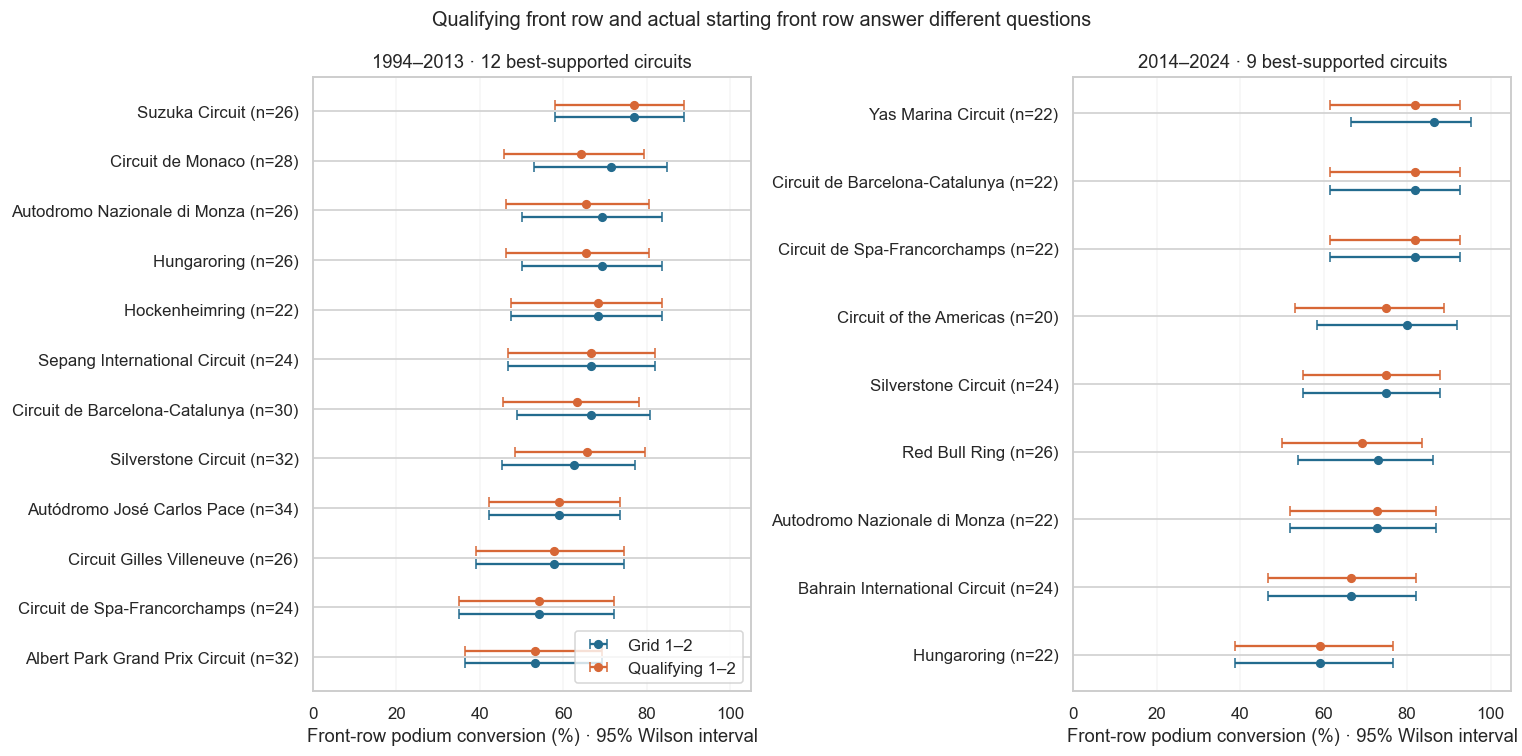

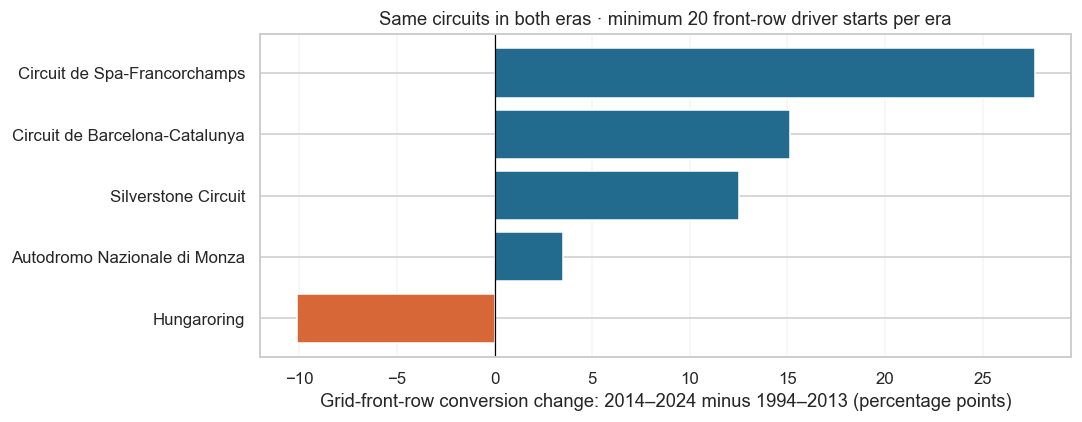

,circuitId,circuit_name,era,definition,podiums,starts,rate,ci_low,ci_high,supported,rank
76,22,Suzuka Circuit,1994–2013,Grid 1–2,20,26,0.769231,0.579481,0.889663,True,1.0
20,6,Circuit de Monaco,1994–2013,Grid 1–2,20,28,0.714286,0.529404,0.847462,True,2.0
38,11,Hungaroring,1994–2013,Grid 1–2,18,26,0.692308,0.500114,0.834989,True,3.0
48,14,Autodromo Nazionale di Monza,1994–2013,Grid 1–2,18,26,0.692308,0.500114,0.834989,True,3.0
34,10,Hockenheimring,1994–2013,Grid 1–2,15,22,0.681818,0.473182,0.836396,True,5.0
77,22,Suzuka Circuit,1994–2013,Qualifying 1–2,20,26,0.769231,0.579481,0.889663,True,1.0
59,17,Shanghai International Circuit,1994–2013,Qualifying 1–2,14,20,0.700000,0.481023,0.854525,True,2.0
35,10,Hockenheimring,1994–2013,Qualifying 1–2,15,22,0.681818,0.473182,0.836396,True,3.0
5,2,Sepang International Circuit,1994–2013,Qualifying 1–2,16,24,0.666667,0.467060,0.820280,True,4.0
31,9,Silverstone Circuit,1994–2013,Qualifying 1–2,21,32,0.656250,0.483108,0.795898,True,5.0


,circuitId,circuit_name,definition,rate_1994–2013,rate_2014–2024,starts_1994–2013,starts_2014–2024,rank_1994–2013,rank_2014–2024,supported_both,rate_change_pp,common_rank_before,common_rank_after,common_rank_change
24,13,Circuit de Spa-Francorchamps,Grid 1–2,0.541667,0.818182,24.0,22.0,14.0,2.0,True,27.651515,5.0,1.0,-4.0
25,13,Circuit de Spa-Francorchamps,Qualifying 1–2,0.541667,0.818182,24.0,22.0,14.0,1.0,True,27.651515,5.0,1.0,-4.0
7,4,Circuit de Barcelona-Catalunya,Qualifying 1–2,0.633333,0.818182,30.0,22.0,10.0,1.0,True,18.484848,4.0,1.0,-3.0
6,4,Circuit de Barcelona-Catalunya,Grid 1–2,0.666667,0.818182,30.0,22.0,6.0,2.0,True,15.151515,3.0,1.0,-2.0
16,9,Silverstone Circuit,Grid 1–2,0.625000,0.750000,32.0,24.0,10.0,5.0,True,12.500000,4.0,3.0,-1.0
17,9,Silverstone Circuit,Qualifying 1–2,0.656250,0.750000,32.0,24.0,5.0,4.0,True,9.375000,1.0,3.0,2.0
27,14,Autodromo Nazionale di Monza,Qualifying 1–2,0.653846,0.727273,26.0,22.0,6.0,6.0,True,7.342657,2.0,4.0,2.0
26,14,Autodromo Nazionale di Monza,Grid 1–2,0.692308,0.727273,26.0,22.0,3.0,7.0,True,3.496503,1.0,4.0,3.0
21,11,Hungaroring,Qualifying 1–2,0.653846,0.590909,26.0,22.0,6.0,9.0,True,-6.293706,2.0,5.0,3.0
20,11,Hungaroring,Grid 1–2,0.692308,0.590909,26.0,22.0,3.0,9.0,True,-10.139860,1.0,5.0,4.0


**Answer.** Compared 490 races from 1994–2024 with both front-row definitions observed; excluded 87 races with incomplete front-row support. Recorded nonstarters are removed before eligibility is checked (138 driver entries in this window). 1994–2013 Grid 1–2: Suzuka Circuit, 76.9% (20/26); 1994–2013 Qualifying 1–2: Suzuka Circuit, 76.9% (20/26); 2014–2024 Grid 1–2: Yas Marina Circuit, 86.4% (19/22); 2014–2024 Qualifying 1–2: Circuit de Barcelona-Catalunya, 81.8% (18/22). The largest supported absolute grid-conversion change is Circuit de Spa-Francorchamps: +27.7 percentage points; its common-circuit rank changed from 5 to 1. Front-row membership differs for 72 driver-race records, so qualifying and grid must not be conflated. Ranks are descriptive, with ties and wide intervals possible; changes cannot be attributed causally to hybrid regulations.

In [6]:
a_quali = tables["qualifying"][["raceId", "driverId", "position", "qualifyId"]].copy()
a_quali["qual_position"] = pd.to_numeric(a_quali["position"], errors="coerce")
# The supplied qualifying table is unique at this grain. A future duplicate must
# be investigated rather than resolved using its qualifying outcome.
a_q_duplicates = int(a_quali.duplicated(["raceId", "driverId"]).sum())
assert a_q_duplicates == 0, "Investigate duplicate qualifying driver-race rows before joining."
a_q_join = a_joined.merge(
    a_quali[["raceId", "driverId", "qual_position"]],
    on=["raceId", "driverId"], how="left", validate="one_to_one"
)
a_q_join = a_q_join.loc[a_q_join["year"].between(1994, 2024)].copy()
a_q_nonstart = ~classify_race_starts(a_q_join, "race_status")
a_q_starters = a_q_join[~a_q_nonstart].copy()
a_q_counts = a_q_starters.groupby("raceId", observed=True).agg(
    q_front=("qual_position", lambda a_v: int(a_v.isin([1, 2]).sum())),
    grid_front=("grid", lambda a_v: int(a_v.isin([1, 2]).sum()))
)
a_q_eligible = a_q_counts.index[(a_q_counts.q_front == 2) & (a_q_counts.grid_front == 2)]
a_q_common = a_q_starters[a_q_starters.raceId.isin(a_q_eligible)].copy()
a_q_common["era"] = np.where(a_q_common.year < 2014, "1994–2013", "2014–2024")
a_q_exposures = pd.concat([
    a_q_common[a_q_common.qual_position.isin([1, 2])].assign(definition="Qualifying 1–2"),
    a_q_common[a_q_common.grid.isin([1, 2])].assign(definition="Grid 1–2")
], ignore_index=True)
a_q1_rates = a_rates(a_q_exposures, ["circuitId", "circuit_name", "era", "definition"])
a_q1_rates["supported"] = a_q1_rates.starts.ge(20)
a_q1_rates["rank"] = np.nan
a_q1_rates.loc[a_q1_rates.supported, "rank"] = a_q1_rates[a_q1_rates.supported].groupby(
    ["era", "definition"], observed=True
)["rate"].rank(method="min", ascending=False)
a_q1_rates.to_csv(a_table_dir / "q1_frontrow_rates.csv", index=False)

# Drivers can move into/out of the front row even when the total is still two.
a_q_disagree = a_q_common.assign(
    qualifying_front=a_q_common.qual_position.isin([1, 2]),
    grid_front=a_q_common.grid.isin([1, 2])
)
a_q_disagree["front_row_membership_differs"] = a_q_disagree.qualifying_front.ne(a_q_disagree.grid_front)
a_q_disagreement = a_q_disagree.groupby("era", observed=True).agg(
    races=("raceId", "nunique"),
    driver_rows=("driverId", "size"),
    differing_memberships=("front_row_membership_differs", "sum")
).reset_index()
a_q_disagreement.to_csv(a_table_dir / "q1_qualifying_grid_disagreement.csv", index=False)

a_q1_changes = a_q1_rates.pivot(
    index=["circuitId", "circuit_name", "definition"], columns="era",
    values=["rate", "starts", "rank"]
)
a_q1_changes.columns = [f"{a_measure}_{a_era}" for a_measure, a_era in a_q1_changes.columns]
a_q1_changes = a_q1_changes.reset_index()
a_q1_changes["supported_both"] = (
    a_q1_changes["starts_1994–2013"].ge(20) & a_q1_changes["starts_2014–2024"].ge(20)
)
a_q1_changes["rate_change_pp"] = 100 * (
    a_q1_changes["rate_2014–2024"] - a_q1_changes["rate_1994–2013"]
)
# Ranks here compare the SAME set of circuits in both eras, avoiding calendar entry/exit effects.
a_q1_changes["common_rank_before"] = np.nan
a_q1_changes["common_rank_after"] = np.nan
a_q1_changes.loc[a_q1_changes.supported_both, "common_rank_before"] = a_q1_changes[
    a_q1_changes.supported_both
].groupby("definition")["rate_1994–2013"].rank(method="min", ascending=False)
a_q1_changes.loc[a_q1_changes.supported_both, "common_rank_after"] = a_q1_changes[
    a_q1_changes.supported_both
].groupby("definition")["rate_2014–2024"].rank(method="min", ascending=False)
a_q1_changes["common_rank_change"] = a_q1_changes.common_rank_after - a_q1_changes.common_rank_before
a_q1_changes.to_csv(a_table_dir / "q1_era_changes.csv", index=False)

a_q1_fig, a_q1_axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True)
for a_ax, a_era in zip(a_q1_axes, ["1994–2013", "2014–2024"]):
    a_grid_cells = a_q1_rates[(a_q1_rates.era == a_era) & (a_q1_rates.definition == "Grid 1–2") & a_q1_rates.supported]
    a_display_cells = a_grid_cells.nlargest(12, "starts").sort_values("rate")
    a_names = a_display_cells.circuit_name.tolist()
    for a_shift, a_def, a_color in [(-0.13, "Grid 1–2", "#236b8e"), (0.13, "Qualifying 1–2", "#d76736")]:
        a_plot = a_q1_rates[(a_q1_rates.era == a_era) & (a_q1_rates.definition == a_def)].set_index("circuit_name").reindex(a_names)
        a_y = np.arange(len(a_names)) + a_shift
        a_ax.errorbar(100 * a_plot.rate, a_y,
                      xerr=100 * np.vstack([a_plot.rate - a_plot.ci_low, a_plot.ci_high - a_plot.rate]),
                      fmt="o", color=a_color, capsize=3, label=a_def, markersize=5)
    a_ax.set_yticks(np.arange(len(a_names)), [f"{a_n} (n={int(a_v)})" for a_n, a_v in zip(a_names, a_display_cells.starts)])
    a_ax.set_title(a_era + f" · {len(a_names)} best-supported circuits")
    a_ax.set_xlabel("Front-row podium conversion (%) · 95% Wilson interval")
    a_ax.set_xlim(0, 105)
    a_ax.grid(axis="x", alpha=0.2)
a_q1_axes[0].legend(loc="lower right")
a_q1_fig.suptitle("Qualifying front row and actual starting front row answer different questions", fontsize=13)
plt.tight_layout()
savefig("q1_frontrow_circuits.png", "Front-row podium conversion by circuit and era on the same eligible races, excluding recorded nonstarters; qualifying and grid definitions use two starters per race. Bars are descriptive 95% Wilson intervals and plotted circuits have at least 20 starts per cell.")
analysis_figures.append("q1_frontrow_circuits.png")

a_q1_delta = a_q1_changes[a_q1_changes.supported_both & a_q1_changes.definition.eq("Grid 1–2")].sort_values("rate_change_pp")
plt.figure(figsize=(10, max(4, 0.35 * len(a_q1_delta))))
plt.barh(a_q1_delta.circuit_name, a_q1_delta.rate_change_pp,
         color=np.where(a_q1_delta.rate_change_pp >= 0, "#236b8e", "#d76736"))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Grid-front-row conversion change: 2014–2024 minus 1994–2013 (percentage points)")
plt.title("Same circuits in both eras · minimum 20 front-row driver starts per era")
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
savefig("q1_era_changes.png", "Change in actual-grid front-row podium conversion from 1994–2013 to 2014–2024 for the same circuit identities, with at least 20 observed starts in each era. Calendar changes, cars and field composition prevent causal attribution to hybrid rules.")
analysis_figures.append("q1_era_changes.png")
display(a_q1_rates[a_q1_rates.supported].sort_values(["era", "definition", "rank", "starts"], ascending=[True, True, True, False]).groupby(["era", "definition"], observed=True).head(5))
display(a_q1_changes[a_q1_changes.supported_both].sort_values("rate_change_pp", ascending=False))

a_q1_leaders = []
for (a_era, a_def), a_block in a_q1_rates[a_q1_rates.supported].groupby(["era", "definition"], observed=True):
    a_best = a_block.sort_values(["rate", "starts"], ascending=False).iloc[0]
    a_q1_leaders.append(f"{a_era} {a_def}: {a_best.circuit_name}, {a_best.rate:.1%} ({int(a_best.podiums)}/{int(a_best.starts)})")
a_q1_largest = a_q1_delta.loc[a_q1_delta.rate_change_pp.abs().idxmax()] if len(a_q1_delta) else None
a_q1_change_text = (
    f"The largest supported absolute grid-conversion change is {a_q1_largest.circuit_name}: "
    f"{a_q1_largest.rate_change_pp:+.1f} percentage points; its common-circuit rank changed "
    f"from {a_q1_largest.common_rank_before:.0f} to {a_q1_largest.common_rank_after:.0f}. "
    if a_q1_largest is not None else "No circuit has enough support in both eras to rank its change. "
)
analyses_summary["q1"] = (
    f"Compared {len(a_q_eligible):,} races from 1994–2024 with both front-row definitions observed; "
    f"excluded {a_q_join.raceId.nunique() - len(a_q_eligible):,} races with incomplete front-row support. "
    f"Recorded nonstarters are removed before eligibility is checked ({int(a_q_nonstart.sum())} driver entries in this window). "
    + "; ".join(a_q1_leaders) + ". " + a_q1_change_text +
    f"Front-row membership differs for {int(a_q_disagreement.differing_memberships.sum()):,} driver-race "
    "records, so qualifying and grid must not be conflated. Ranks are descriptive, with ties and wide "
    "intervals possible; changes cannot be attributed causally to hybrid regulations."
)
display(Markdown("**Answer.** " + analyses_summary["q1"]))

### Q2. Is home-country podium probability higher after controlling for starting position?

A driver's recorded nationality is mapped explicitly to one or more countries;
this is a nationality proxy, not residence, birthplace or self-reported home.
`British → UK`, `American → USA`, and both `USA` and `United States` circuit
labels are normalized. Dual nationalities match either country. East German is
mapped geographically to Germany; Rhodesian to Zimbabwe, where this dataset has
no circuit. Missing/unmapped values are excluded and counted rather than being
treated as away. The complete mapping is exported for review.

Primary scope is 1994–2024, matching Q1's modern coverage. We directly
standardize home and away rates to the **same observed distribution of exact
starting grid position × era**. Grid zero is a separate pit-lane/unrecorded
category; it is not treated as first place. Each retained stratum needs at least
five home and five away rows. This common-support restriction and its retained
fraction are reported. This question's unit is a pre-race driver entry, including
recorded nonstarters as non-podiums; it is not a mechanical-start denominator.
1,000 bootstrap resamples draw entire races, preserving
dependence between competitors; weights and the selected common-support target
remain fixed. This controls observed grid and broad era only. Driver quality,
constructor, circuit and detailed season differences remain confounders, so the
result is an association, not a causal home advantage.

home,Away rate,Home rate
stratum,,
0 | 1994–2013,0.000000,0.000000
1 | 1994–2013,0.710366,0.666667
1 | 2014–2024,0.816901,0.666667
10 | 1994–2013,0.057927,0.000000
10 | 2014–2024,0.041284,0.000000
11 | 1994–2013,0.031348,0.033333
11 | 2014–2024,0.018265,0.000000
12 | 1994–2013,0.027108,0.000000
12 | 2014–2024,0.013514,0.000000


,estimate,group,rate,ci_low,ci_high,rows,adjusted_home_minus_away_pp,adjusted_difference_ci_low_pp,adjusted_difference_ci_high_pp
0,Crude: all mapped rows,Away,0.140828,0.139258,0.142285,11759,-2.529386,-4.422353,-0.486799
1,Crude: all mapped rows,Home,0.125209,0.102387,0.150099,599,-2.529386,-4.422353,-0.486799
2,Standardized: shared grid/era support,Away,0.138843,0.136839,0.140718,10467,-2.529386,-4.422353,-0.486799
3,Standardized: shared grid/era support,Home,0.113549,0.094979,0.133467,576,-2.529386,-4.422353,-0.486799


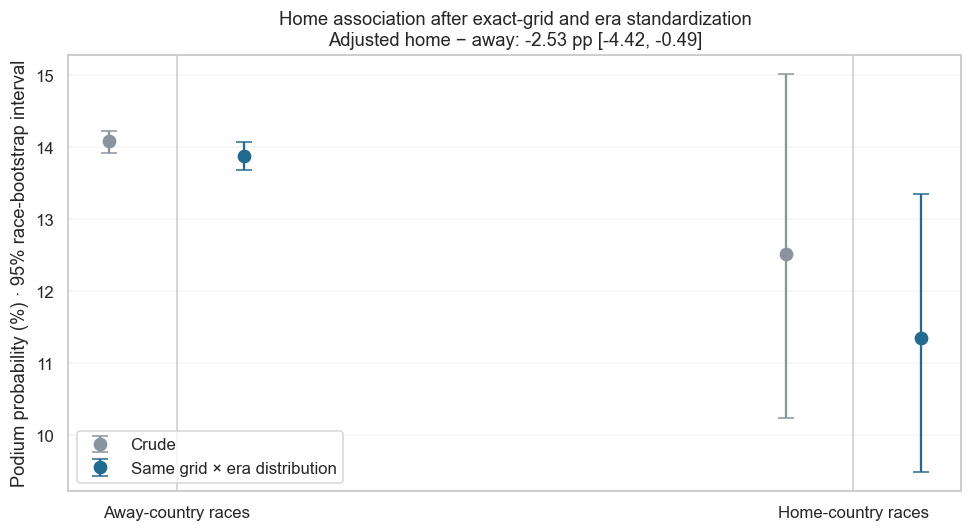

**Answer.** In 1994–2024, crude home podium rate is 12.5% versus 14.1% away. After standardizing exact grid × era, home is 11.4% versus 13.9% away: difference -2.53 percentage points (95% race-bootstrap interval -4.42 to -0.49). Shared support retains 11,043/12,358 rows (89.4%) across 40 strata; 0 rows are excluded for unavailable mapping/country/grid. The unit is a driver entry; recorded nonstarters remain non-podiums for this pre-race association. 964/1,000 adjusted bootstrap draws retained all strata. The adjusted interval excludes zero, supporting an observed association in this target population. Nationality is a proxy for home, and unmeasured driver/team/circuit differences prevent causal interpretation.

In [7]:
a_nationality_map = {
    "American": ("USA",), "American-Italian": ("USA", "Italy"),
    "Argentine": ("Argentina",), "Argentinian": ("Argentina",),
    "Argentine-Italian": ("Argentina", "Italy"), "Australian": ("Australia",),
    "Austrian": ("Austria",), "Belgian": ("Belgium",), "Brazilian": ("Brazil",),
    "British": ("UK",), "Canadian": ("Canada",), "Chilean": ("Chile",),
    "Chinese": ("China",), "Colombian": ("Colombia",), "Czech": ("Czech Republic",),
    "Danish": ("Denmark",), "Dutch": ("Netherlands",), "East German": ("Germany",),
    "Finnish": ("Finland",), "French": ("France",), "German": ("Germany",),
    "Hungarian": ("Hungary",), "Indian": ("India",), "Indonesian": ("Indonesia",),
    "Irish": ("Ireland",), "Italian": ("Italy",), "Japanese": ("Japan",),
    "Liechtensteiner": ("Liechtenstein",), "Malaysian": ("Malaysia",),
    "Mexican": ("Mexico",), "Monegasque": ("Monaco",), "New Zealander": ("New Zealand",),
    "Polish": ("Poland",), "Portuguese": ("Portugal",), "Rhodesian": ("Zimbabwe",),
    "Russian": ("Russia",), "South African": ("South Africa",), "Spanish": ("Spain",),
    "Swedish": ("Sweden",), "Swiss": ("Switzerland",), "Thai": ("Thailand",),
    "Uruguayan": ("Uruguay",), "Venezuelan": ("Venezuela",)
}
pd.DataFrame([
    {"nationality": a_nat, "mapped_countries": " | ".join(a_countries)}
    for a_nat, a_countries in sorted(a_nationality_map.items())
]).to_csv(a_table_dir / "q2_nationality_country_mapping.csv", index=False)
a_home = a_joined[a_joined.year.between(1994, 2024)].copy()
a_home["country_normalized"] = a_home.circuit_country.astype("string").str.strip().replace({"United States": "USA"})
a_home["nationality_normalized"] = a_home.nationality.astype("string").str.strip()
a_home["home_countries"] = a_home.nationality_normalized.map(a_nationality_map)
a_home_missing = int((a_home.home_countries.isna() | a_home.country_normalized.isna() | a_home.grid.isna()).sum())
a_home = a_home[a_home.home_countries.notna() & a_home.country_normalized.notna() & a_home.grid.notna()].copy()
a_home["home"] = [a_country in a_nations for a_country, a_nations in zip(a_home.country_normalized, a_home.home_countries)]
a_home["era"] = np.where(a_home.year < 2014, "1994–2013", "2014–2024")
a_home["stratum"] = a_home.grid.astype(int).astype(str) + " | " + a_home.era
a_home_strata = a_rates(a_home, ["stratum", "grid", "era", "home"])
a_home_support = a_home_strata.pivot(index="stratum", columns="home", values="starts").reindex(columns=[False, True]).fillna(0)
a_home_shared = a_home_support.index[a_home_support.min(axis=1).ge(5)].tolist()
assert a_home_shared, "Home analysis has no common grid/era support."
a_home_kept = a_home[a_home.stratum.isin(a_home_shared)].copy()
a_home_weights = a_home_kept.stratum.value_counts().reindex(a_home_shared) / len(a_home_kept)
a_home_strata["shared_support"] = a_home_strata.stratum.isin(a_home_shared)
a_home_strata["target_weight"] = a_home_strata.stratum.map(a_home_weights)
a_home_strata.rename(columns={"starts": "driver_entries"}).to_csv(a_table_dir / "q2_grid_strata.csv", index=False)

# Lab 1-style pivot table: one row per grid/era stratum and a column for each
# home flag. Multiply each stratum's observed rate by the SAME target weight.
# Direct standardization goes beyond the lab: it balances these observed grid/era
# distributions without asserting that home country causes a different outcome.
a_home_rate_pivot = a_home_kept.pivot_table(
    index="stratum", columns="home", values="podium", aggfunc="mean", observed=True
).reindex(index=a_home_shared, columns=[False, True])
a_home_weighted_rates = a_home_rate_pivot.mul(a_home_weights, axis="index")
a_home_std = a_home_weighted_rates.sum(axis=0).to_numpy()
display(a_home_rate_pivot.rename(columns={False: "Away rate", True: "Home rate"}))
a_home_rate_pivot.rename(columns={False: "away_rate", True: "home_rate"}).assign(
    target_weight=a_home_weights
).to_csv(a_table_dir / "q2_standardization_pivot.csv")

def a_whole_race_bootstrap(frame, target_weights, rng, draws=1000):
    """Resample complete races; recompute stratum rates with fixed target weights.

    Each sampled race can appear multiple times. Mapping its multiplicity onto
    race-level counts has the same result as copying every driver row that many
    times, while keeping the intermediate Pandas table small and readable.
    """
    race_counts = frame.groupby(["raceId", "stratum", "home"], observed=True).agg(
        podiums=("podium", "sum"), entries=("podium", "size")
    ).reset_index()
    race_ids = frame.raceId.unique()
    estimates, valid_draws = [], []
    for draw in range(draws):
        sampled_races = rng.choice(race_ids, size=len(race_ids), replace=True)
        multiplicities = pd.Series(sampled_races).value_counts()
        draw_counts = race_counts.copy()
        draw_counts["multiplicity"] = draw_counts.raceId.map(multiplicities).fillna(0)
        draw_counts["podiums"] = draw_counts.podiums * draw_counts.multiplicity
        draw_counts["entries"] = draw_counts.entries * draw_counts.multiplicity
        stratum_counts = draw_counts.groupby(["stratum", "home"], observed=True)[
            ["podiums", "entries"]
        ].sum()
        stratum_counts["rate"] = stratum_counts.podiums / stratum_counts.entries
        draw_pivot = stratum_counts.reset_index().pivot(
            index="stratum", columns="home", values="rate"
        ).reindex(index=target_weights.index, columns=[False, True])
        valid = bool(draw_pivot.notna().all().all())
        valid_draws.append(valid)
        if valid:
            estimates.append(draw_pivot.mul(target_weights, axis="index").sum(axis=0).to_numpy())
    return np.asarray(estimates), np.asarray(valid_draws)

a_home_rng = np.random.default_rng(SEED)
a_home_boot_std, a_home_boot_valid = a_whole_race_bootstrap(
    a_home_kept, a_home_weights, a_home_rng
)
assert len(a_home_boot_std) >= 500, "Insufficient stable bootstrap draws; increase stratum support."
a_home_std_ci = np.quantile(a_home_boot_std, [0.025, 0.975], axis=0)
a_home_difference = a_home_std[1] - a_home_std[0]
a_home_diff_ci = np.quantile(a_home_boot_std[:, 1] - a_home_boot_std[:, 0], [0.025, 0.975])

# Crude rates use the full mapped window. Race clustering is also used for their CIs.
a_home_raw_rates = a_home.groupby("home").podium.agg(["sum", "size"]).reindex([False, True])
a_home_raw = (a_home_raw_rates["sum"] / a_home_raw_rates["size"]).to_numpy()
a_home_raw_boot, a_home_raw_valid = a_whole_race_bootstrap(
    a_home.assign(stratum="All mapped entries"),
    pd.Series({"All mapped entries": 1.0}), a_home_rng
)
assert a_home_raw_valid.all(), "A crude resample unexpectedly lost a home/away group."
a_home_raw_ci = np.quantile(a_home_raw_boot, [0.025, 0.975], axis=0)
pd.DataFrame({
    "away_rate": a_home_boot_std[:, 0], "home_rate": a_home_boot_std[:, 1],
    "home_minus_away_pp": 100 * (a_home_boot_std[:, 1] - a_home_boot_std[:, 0])
}).to_csv(a_table_dir / "q2_race_bootstrap_draws.csv", index=False)
a_home_report = pd.DataFrame([
    {"estimate": a_label, "group": a_group, "rate": a_values[a_i],
     "ci_low": a_ci[0, a_i], "ci_high": a_ci[1, a_i],
     "rows": int(a_rows[a_i])}
    for a_label, a_values, a_ci, a_rows in [
        ("Crude: all mapped rows", a_home_raw, a_home_raw_ci, a_home_raw_rates["size"].to_numpy()),
        ("Standardized: shared grid/era support", a_home_std, a_home_std_ci, a_home_kept.groupby("home").size().reindex([False, True]).to_numpy())
    ] for a_i, a_group in enumerate(["Away", "Home"])
])
a_home_report["adjusted_home_minus_away_pp"] = 100 * a_home_difference
a_home_report["adjusted_difference_ci_low_pp"] = 100 * a_home_diff_ci[0]
a_home_report["adjusted_difference_ci_high_pp"] = 100 * a_home_diff_ci[1]
a_home_report.to_csv(a_table_dir / "q2_home_advantage.csv", index=False)
display(a_home_report)

plt.figure(figsize=(9, 5))
for a_i, (a_label, a_values, a_ci, a_color) in enumerate([
    ("Crude", a_home_raw, a_home_raw_ci, "#8a949e"),
    ("Same grid × era distribution", a_home_std, a_home_std_ci, "#236b8e")
]):
    a_positions = np.arange(2) + (-0.10 if a_i == 0 else 0.10)
    plt.errorbar(a_positions, 100 * a_values,
                 yerr=100 * np.vstack([a_values - a_ci[0], a_ci[1] - a_values]),
                 fmt="o", color=a_color, label=a_label, capsize=5, markersize=8)
plt.xticks([0, 1], ["Away-country races", "Home-country races"])
plt.ylabel("Podium probability (%) · 95% race-bootstrap interval")
plt.title(f"Home association after exact-grid and era standardization\nAdjusted home − away: {100*a_home_difference:+.2f} pp [{100*a_home_diff_ci[0]:+.2f}, {100*a_home_diff_ci[1]:+.2f}]")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
savefig("q2_home_advantage.png", "Home-country and away-country driver-entry podium probabilities in 1994–2024, before and after standardization to the same exact grid-position × era distribution. Intervals use 1,000 whole-race bootstrap resamples; adjusted estimates apply only to shared-support strata, and are associational.")
analysis_figures.append("q2_home_advantage.png")
a_home_interpretation = (
    "The adjusted interval excludes zero, supporting an observed association in this target population."
    if a_home_diff_ci[0] > 0 or a_home_diff_ci[1] < 0
    else "The adjusted interval includes zero; these data do not establish a clear home-country association after this adjustment."
)
analyses_summary["q2"] = (
    f"In 1994–2024, crude home podium rate is {a_home_raw[1]:.1%} versus {a_home_raw[0]:.1%} away. "
    f"After standardizing exact grid × era, home is {a_home_std[1]:.1%} versus {a_home_std[0]:.1%} away: "
    f"difference {100*a_home_difference:+.2f} percentage points (95% race-bootstrap interval "
    f"{100*a_home_diff_ci[0]:+.2f} to {100*a_home_diff_ci[1]:+.2f}). "
    f"Shared support retains {len(a_home_kept):,}/{len(a_home):,} rows ({len(a_home_kept)/len(a_home):.1%}) "
    f"across {len(a_home_shared)} strata; {a_home_missing} rows are excluded for unavailable mapping/country/grid. "
    "The unit is a driver entry; recorded nonstarters remain non-podiums for this pre-race association. "
    f"{int(a_home_boot_valid.sum())}/1,000 adjusted bootstrap draws retained all strata. "
    + a_home_interpretation + " Nationality is a proxy for home, and unmeasured driver/team/circuit differences prevent causal interpretation."
)
display(Markdown("**Answer.** " + analyses_summary["q2"]))

### Q3. Which constructors have the highest mechanical retirement rates in 2014–2021 versus 2022–2024?

The numerator is a recorded mechanical retirement cause; the denominator is
driver-race **starts**, including finishers and other retirement causes. Excluding
collisions only from the numerator is necessary: dropping them from the
denominator would inflate a constructor's mechanical rate.
A cause label alone is insufficient: both strict and broad definitions also
require recorded laps to be fewer than the race winner's laps, as an explicit
early-end proxy. A driver classified in the results can still have retired early
and satisfy that rule. A mechanically labelled full-distance result is flagged
and kept in the start denominator, but excluded from either retirement numerator.
Winner distance is a retrospective analysis field, never a predictive feature;
it cannot perfectly distinguish every lapped finish from a retirement, so the
component-cause label and distance condition must both be present.

The strict map includes explicit powertrain, hydraulic/electrical, cooling,
brake, suspension, drivetrain and generic mechanical/technical failures. A broad
sensitivity adds ambiguous tyre/wheel/bodywork/fuel/seat and unspecified
`Retired` labels, whose causes may overlap impact damage or operational errors.
Explicit accidents, collision/damage/debris, driver health, and regulatory
disqualification causes are never counted as mechanical. Exact maps and observed
frequencies are exported; no status is selected by a vague substring search.

`positionText=W` (withdrawal), `F` (failed to qualify), and explicit
withdrawal/nonqualifying labels exclude an entry only without positive recorded
laps. Positive laps override those labels: a mid-race withdrawal is still a start.
The shared rule and contradictory records are audited in section 1.
Grid zero alone is not DNS, and zero laps alone can be a lap-one
collision. A second sensitivity drops remaining zero-lap mechanical/ambiguous
rows, because the data do not always distinguish a formation-lap DNS from an
immediate retirement. Constructor IDs are kept separate across renames rather
than guessing lineage. Ranking requires at least 40 starts (about one full
two-car season), and ranks remain descriptive rather than statistically proven.
`positionText=N` is an unclassified result; these drivers did start and remain
in the denominator. Whether a result was classified is separate from its cause.

,statusId,race_status,cause_category,rows_2014_2024,nonstarters_2014_2024,full_distance_component_status_rows
30,31,Retired,Ambiguous: broad sensitivity only,50,1,0
35,36,Wheel,Ambiguous: broad sensitivity only,11,0,0
28,29,Puncture,Ambiguous: broad sensitivity only,7,0,0
26,27,Tyre,Ambiguous: broad sensitivity only,4,0,0
137,140,Undertray,Ambiguous: broad sensitivity only,4,0,0
...,...,...,...,...,...,...
104,105,Spark plugs,Mechanical: strict,1,0,0
138,141,Cooling system,Mechanical: strict,1,0,0
1,2,Disqualified,Regulatory: never mechanical,11,0,0
95,96,Excluded,Regulatory: never mechanical,1,0,0


,constructorId,constructor_name,era,starts,mechanical,mechanical_broad,uncertain_zero_lap_starts,full_distance_component_status_rows,rate,broad_rate,ci_low,ci_high,supported,rank,broad_rank,zero_lap_excluded_rate
20,207,Caterham,2014–2021,33,7,10,0,0,0.212121,0.30303,0.106759,0.377520,False,NaN,NaN,0.212121
21,208,Lotus F1,2014–2021,75,13,18,1,0,0.173333,0.24,0.104190,0.274310,True,1.0,1.0,0.162162
5,5,Toro Rosso,2014–2021,242,39,44,2,0,0.161157,0.181818,0.120186,0.212717,True,2.0,2.0,0.158333
4,4,Renault,2014–2021,199,26,31,1,0,0.130653,0.155779,0.090743,0.184553,True,3.0,3.0,0.126263
0,1,McLaren,2014–2021,316,40,48,1,0,0.126582,0.151899,0.094352,0.167783,True,4.0,4.0,0.123810
8,9,Red Bull,2014–2021,318,34,37,0,0,0.106918,0.116352,0.077525,0.145695,True,5.0,7.0,0.106918
11,15,Sauber,2014–2021,199,21,26,1,0,0.105528,0.130653,0.070063,0.155934,True,6.0,5.0,0.101010
19,206,Marussia,2014–2021,31,3,3,0,0,0.096774,0.096774,0.033464,0.249003,False,NaN,NaN,0.096774
26,213,AlphaTauri,2014–2021,77,7,8,0,0,0.090909,0.103896,0.044735,0.175963,True,7.0,8.0,0.090909
25,211,Racing Point,2014–2021,75,6,7,0,0,0.08,0.093333,0.037180,0.163750,True,8.0,9.0,0.080000


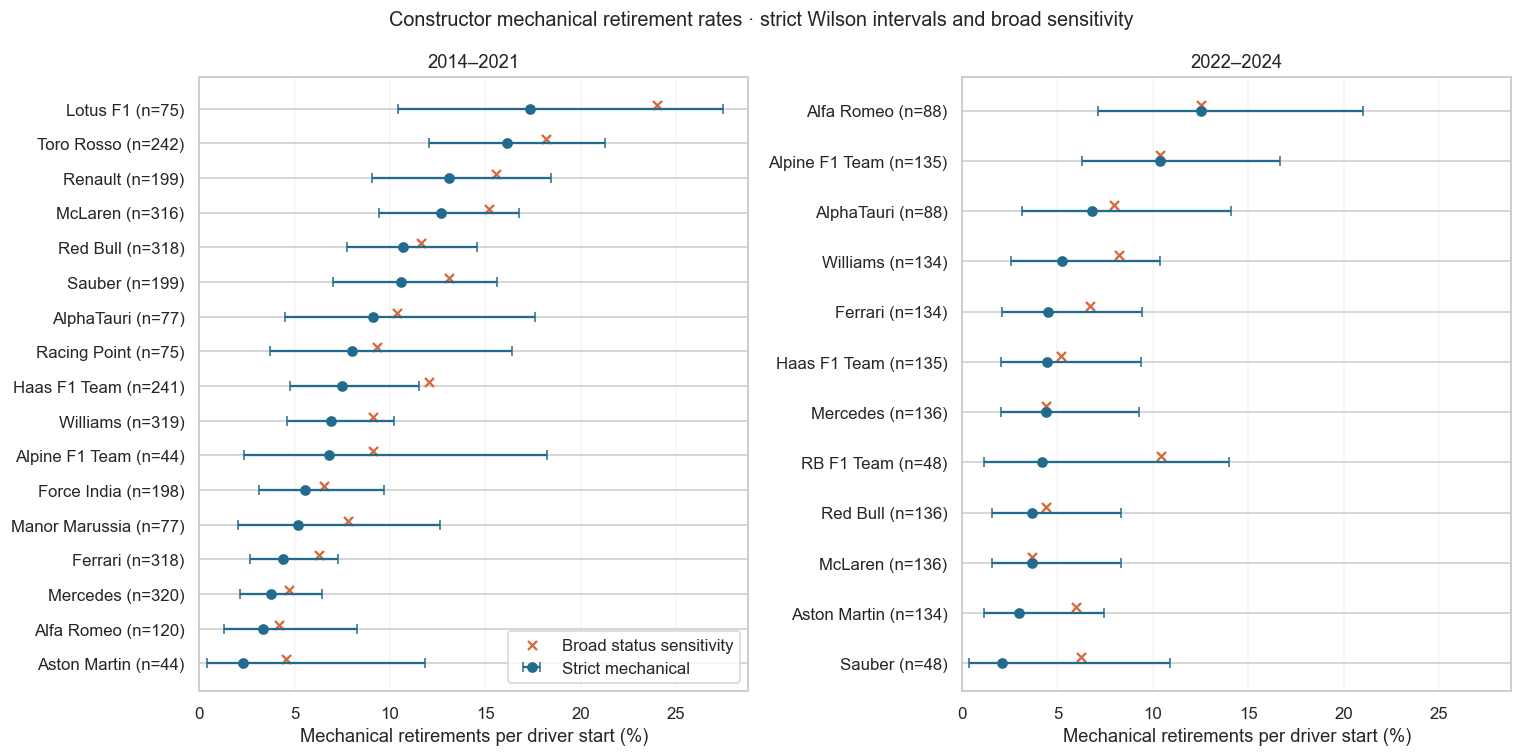

**Answer.** 2014–2021: Lotus F1 has the highest supported strict rate, 17.3% (13/75), 95% Wilson interval 10.4%–27.4%; the broad-map leader is Lotus F1 (24.0%); 2022–2024: Alfa Romeo has the highest supported strict rate, 12.5% (11/88), 95% Wilson interval 7.1%–21.0%; the broad-map leader is Alfa Romeo (12.5%). Excluded 28 recorded nonstarters from both numerator and denominator. Withdrawal/nonqualifying labels exclude only entries without positive laps; positive-lap withdrawals remain starts. Both cause maps require laps below winner distance as an early-end proxy; 1 full-distance component-status row(s) are flagged and excluded from both retirement numerators, while remaining in the start denominator. 10 remaining zero-lap mechanical/ambiguous rows have uncertain start status; the exported table reports a sensitivity excluding these. The numerator excludes explicit crash/damage, driver-health and regulatory outcomes while these started entries remain in the denominator. Rankings use at least 40 starts and recorded constructor IDs, so a rename does not automatically inherit its predecessor's rate. Wilson intervals and unequal exposure mean that the largest observed rate is not necessarily evidence of the least reliable constructor.

2907

In [8]:
a_mechanical_strict = {
    "Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical",
    "Radiator", "Suspension", "Brakes", "Differential", "Overheating", "Mechanical",
    "Driveshaft", "Fuel pressure", "Water pressure", "Throttle", "Steering",
    "Technical", "Electronics", "Heat shield fire", "Exhaust", "Oil leak",
    "Water leak", "Fuel pump", "Track rod", "Oil pressure", "Engine fire",
    "Engine misfire", "Pneumatics", "Wheel bearing", "Fuel system", "Oil line",
    "Launch control", "Power loss", "Drivetrain", "Ignition", "Battery",
    "Halfshaft", "Crankshaft", "Alternator", "Oil pump", "Fuel leak", "Injection",
    "Distributor", "Turbo", "CV joint", "Water pump", "Spark plugs", "Fuel pipe",
    "Oil pipe", "Axle", "Water pipe", "Magneto", "Supercharger", "Power Unit",
    "ERS", "Cooling system"
}
a_mechanical_ambiguous = {
    "Tyre", "Puncture", "Tyre puncture", "Wheel", "Wheel rim", "Wheel nut",
    "Front wing", "Broken wing", "Rear wing", "Undertray", "Chassis", "Brake duct",
    "Refuelling", "Fuel rig", "Fuel", "Out of fuel", "Fire", "Vibrations", "Handling",
    "Driver Seat", "Seat", "Safety belt", "Retired"
}
a_nonstart_statuses = START_EXCLUSION_STATUSES
a_crash_statuses = {"Accident", "Collision", "Spun off", "Fatal accident", "Collision damage", "Damage", "Debris"}
a_driver_statuses = {"Physical", "Injured", "Injury", "Driver unwell", "Eye injury", "Illness"}
a_regulatory_statuses = {"Disqualified", "Underweight", "Excluded"}

def a_status_category(a_status):
    if a_status in a_mechanical_strict:
        return "Mechanical: strict"
    if a_status in a_mechanical_ambiguous:
        return "Ambiguous: broad sensitivity only"
    if a_status == "Withdrew":
        return "Withdrawal: inspect laps for start evidence"
    if a_status in a_nonstart_statuses:
        return "Nonstart / nonqualifying"
    if a_status in a_crash_statuses:
        return "Crash / damage: never mechanical"
    if a_status in a_driver_statuses:
        return "Driver health: never mechanical"
    if a_status in a_regulatory_statuses:
        return "Regulatory: never mechanical"
    if a_status == "Finished" or str(a_status).startswith("+"):
        return "Finished / lapped"
    return "Other / unresolved: excluded from numerator"

a_reliability_all = a_joined[a_joined.year.between(2014, 2024)].copy()
a_reliability_all["era"] = np.where(a_reliability_all.year <= 2021, "2014–2021", "2022–2024")
a_reliability_all["cause_category"] = a_reliability_all.race_status.map(a_status_category)
a_reliability_winners = a_reliability_all[a_reliability_all.positionOrder.eq(1)][["raceId", "laps"]].rename(
    columns={"laps": "winner_laps"}
)
assert not a_reliability_winners.raceId.duplicated().any(), "Each analyzed race needs one winner distance."
a_reliability_all = a_reliability_all.merge(a_reliability_winners, on="raceId", how="left", validate="many_to_one")
assert a_reliability_all.winner_laps.notna().all() and a_reliability_all.winner_laps.gt(0).all()
assert a_reliability_all.laps.notna().all(), "Retirement distance must be known."
a_reliability_all["ended_early_proxy"] = a_reliability_all.laps.lt(a_reliability_all.winner_laps)
a_reliability_all["full_distance_component_status"] = (
    a_reliability_all.race_status.isin(a_mechanical_strict | a_mechanical_ambiguous)
    & ~a_reliability_all.ended_early_proxy
)
a_reliability_all["nonstarter"] = ~classify_race_starts(a_reliability_all, "race_status")
assert not a_reliability_all.loc[a_reliability_all.nonstarter, "laps"].gt(0).any()
a_status_mapping = a_statuses.copy()
a_status_mapping["cause_category"] = a_status_mapping.race_status.map(a_status_category)
a_status_mapping["rows_2014_2024"] = a_status_mapping.race_status.map(a_reliability_all.race_status.value_counts()).fillna(0).astype(int)
a_status_mapping["nonstarters_2014_2024"] = a_status_mapping.race_status.map(
    a_reliability_all[a_reliability_all.nonstarter].race_status.value_counts()
).fillna(0).astype(int)
a_status_mapping["full_distance_component_status_rows"] = a_status_mapping.race_status.map(
    a_reliability_all[a_reliability_all.full_distance_component_status].race_status.value_counts()
).fillna(0).astype(int)
a_status_mapping.to_csv(a_table_dir / "q3_status_mapping.csv", index=False)
a_reliability_all[a_reliability_all.full_distance_component_status][[
    "raceId", "year", "driverId", "constructorId", "constructor_name", "laps",
    "winner_laps", "positionOrder", "positionText", "race_status", "cause_category"
]].to_csv(a_table_dir / "q3_full_distance_component_status.csv", index=False)
a_reliability_all[a_reliability_all.nonstarter][[
    "raceId", "year", "driverId", "constructorId", "constructor_name", "grid",
    "laps", "positionText", "race_status"
]].to_csv(a_table_dir / "q3_excluded_nonstarters.csv", index=False)
a_reliability = a_reliability_all[~a_reliability_all.nonstarter].copy()
a_reliability["mechanical"] = (
    a_reliability.race_status.isin(a_mechanical_strict) & a_reliability.ended_early_proxy
).astype(int)
a_reliability["mechanical_broad"] = (
    a_reliability.race_status.isin(a_mechanical_strict | a_mechanical_ambiguous) & a_reliability.ended_early_proxy
).astype(int)
assert a_reliability.loc[a_reliability.mechanical.eq(1), "laps"].lt(
    a_reliability.loc[a_reliability.mechanical.eq(1), "winner_laps"]
).all()
a_reliability["uncertain_zero_lap_start"] = (
    a_reliability.laps.eq(0) & a_reliability.mechanical_broad.eq(1)
)
a_q3_rates = a_reliability.groupby(["constructorId", "constructor_name", "era"], observed=True).agg(
    starts=("driverId", "size"), mechanical=("mechanical", "sum"),
    mechanical_broad=("mechanical_broad", "sum"),
    uncertain_zero_lap_starts=("uncertain_zero_lap_start", "sum"),
    full_distance_component_status_rows=("full_distance_component_status", "sum")
).reset_index()
a_q3_rates["rate"] = a_q3_rates.mechanical / a_q3_rates.starts
a_q3_rates["broad_rate"] = a_q3_rates.mechanical_broad / a_q3_rates.starts
a_q3_rates["ci_low"], a_q3_rates["ci_high"] = a_wilson(a_q3_rates.mechanical, a_q3_rates.starts)
a_q3_rates["supported"] = a_q3_rates.starts.ge(40)
a_q3_rates["rank"] = np.nan
a_q3_rates["broad_rank"] = np.nan
a_q3_rates.loc[a_q3_rates.supported, "rank"] = a_q3_rates[a_q3_rates.supported].groupby("era")["rate"].rank(method="min", ascending=False)
a_q3_rates.loc[a_q3_rates.supported, "broad_rank"] = a_q3_rates[a_q3_rates.supported].groupby("era")["broad_rate"].rank(method="min", ascending=False)
a_q3_zero = a_reliability[~a_reliability.uncertain_zero_lap_start].groupby(["constructorId", "era"], observed=True).mechanical.agg(["sum", "size"])
a_q3_zero["zero_lap_excluded_rate"] = a_q3_zero["sum"] / a_q3_zero["size"]
a_q3_rates = a_q3_rates.merge(a_q3_zero[["zero_lap_excluded_rate"]], on=["constructorId", "era"], how="left", validate="one_to_one")
a_q3_rates.to_csv(a_table_dir / "q3_constructor_reliability.csv", index=False)
display(a_status_mapping[a_status_mapping.rows_2014_2024.gt(0)].sort_values(["cause_category", "rows_2014_2024"], ascending=[True, False]))
display(a_q3_rates.sort_values(["era", "rate"], ascending=[True, False]))

a_q3_fig, a_q3_axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True)
for a_ax, a_era in zip(a_q3_axes, ["2014–2021", "2022–2024"]):
    a_plot = a_q3_rates[(a_q3_rates.era == a_era) & a_q3_rates.supported].sort_values("rate")
    a_y = np.arange(len(a_plot))
    a_ax.errorbar(100*a_plot.rate, a_y,
                  xerr=100*np.vstack([a_plot.rate-a_plot.ci_low, a_plot.ci_high-a_plot.rate]),
                  fmt="o", color="#236b8e", capsize=3, label="Strict mechanical", markersize=6)
    a_ax.scatter(100*a_plot.broad_rate, a_y + 0.12, marker="x", color="#d76736", label="Broad status sensitivity", s=35)
    a_ax.set_yticks(a_y, [f"{a_name} (n={a_n})" for a_name, a_n in zip(a_plot.constructor_name, a_plot.starts)])
    a_ax.set_title(a_era)
    a_ax.set_xlabel("Mechanical retirements per driver start (%)")
    a_ax.grid(axis="x", alpha=0.2)
    a_ax.set_xlim(left=0)
a_q3_axes[0].legend(loc="lower right")
a_q3_fig.suptitle("Constructor mechanical retirement rates · strict Wilson intervals and broad sensitivity", fontsize=13)
plt.tight_layout()
savefig("q3_constructor_reliability.png", "Recorded mechanical causes with laps below winner distance, divided by driver starts by constructor ID and era. Positive-lap withdrawals remain starts; explicit withdrawal/nonqualifying labels exclude entries only without positive laps. Bars show descriptive 95% Wilson intervals; orange crosses add ambiguous causes under the same early-end gate. Ranking requires at least 40 starts and does not merge renamed teams.")
analysis_figures.append("q3_constructor_reliability.png")
a_q3_leaders = []
for a_era, a_block in a_q3_rates[a_q3_rates.supported].groupby("era", observed=True):
    a_strict_leader = a_block.sort_values(["rate", "starts"], ascending=False).iloc[0]
    a_broad_leader = a_block.sort_values(["broad_rate", "starts"], ascending=False).iloc[0]
    a_q3_leaders.append(
        f"{a_era}: {a_strict_leader.constructor_name} has the highest supported strict rate, "
        f"{a_strict_leader.rate:.1%} ({int(a_strict_leader.mechanical)}/{int(a_strict_leader.starts)}), "
        f"95% Wilson interval {a_strict_leader.ci_low:.1%}–{a_strict_leader.ci_high:.1%}; "
        f"the broad-map leader is {a_broad_leader.constructor_name} ({a_broad_leader.broad_rate:.1%})"
    )
analyses_summary["q3"] = (
    "; ".join(a_q3_leaders) + ". "
    f"Excluded {int(a_reliability_all.nonstarter.sum())} recorded nonstarters from both numerator and denominator. "
    "Withdrawal/nonqualifying labels exclude only entries without positive laps; positive-lap withdrawals remain starts. "
    f"Both cause maps require laps below winner distance as an early-end proxy; "
    f"{int(a_reliability.full_distance_component_status.sum())} full-distance component-status row(s) are "
    "flagged and excluded from both retirement numerators, while remaining in the start denominator. "
    f"{int(a_reliability.uncertain_zero_lap_start.sum())} remaining zero-lap mechanical/ambiguous rows have "
    "uncertain start status; the exported table reports a sensitivity excluding these. "
    "The numerator excludes explicit crash/damage, driver-health and regulatory outcomes while these started "
    "entries remain in the denominator. Rankings use at least 40 starts and recorded constructor IDs, "
    "so a rename does not automatically inherit its predecessor's rate. Wilson intervals and unequal exposure "
    "mean that the largest observed rate is not necessarily evidence of the least reliable constructor."
)
display(Markdown("**Answer.** " + analyses_summary["q3"]))
(OUT / 'analyses_summary.json').write_text(json.dumps(analyses_summary, indent=2), encoding='utf-8')

**What these joins establish.** Each output is computed at a declared grain and
uses a denominator tied to the question. Matching qualifying coverage prevents
Q1 from comparing different historical samples; standardization stops Q2 from
simply reflecting home drivers' grid distribution; explicit status and withdrawal
handling prevents Q3 from treating crashes or mechanically caused DNS as race
retirements. Exported tables retain small cells and ambiguous cases so the
conclusions can be audited instead of hiding them in a chart.

## 3. Leakage-safe feature engineering and evidence

**Prediction scenario:** sequential forecasting at each race's final pre-start cutoff.
A later validation/test race may use results of earlier validation/test races once
those races have completed. It may never use its own or a later race's outcomes.
This simulates deployment with updating history, not a single forecast of a whole
unseen season made on January 1. Model weights and preprocessing remain frozen.

Build history on all cleaned years, then restrict model rows to **1994-2024**.
This keeps qualifying-era observations while using older races as historical warm-up.
A 2003+ sensitivity experiment later checks the effect of the sparse early qualifying
years. Feature exploration below uses **training rows only**; the holdout is not used
to choose features. Driver/constructor identifiers remain metadata, avoiding arbitrary
numeric ID effects and improving behavior for new competitors.

In [9]:
history = results_unique.merge(tables['races'][['raceId', 'year', 'round', 'date', 'circuitId']],
                               on='raceId', how='left', validate='many_to_one')
history = history.merge(tables['status'].rename(columns={'status': 'status_text'}),
                         on='statusId', validate='many_to_one')
history = history.sort_values(['date', 'raceId', 'driverId']).reset_index(drop=True)
assert not history.date.isna().any()
NO_START = START_EXCLUSION_STATUSES
# Positive laps establish participation even when the archive says W/F/Withdrew.
# Without positive laps, exclude explicit W/F/nonstart labels. N remains a start;
# grid=0 or laps=0 alone does not prove DNS. Only earlier races feed experience.
history['_started'] = classify_race_starts(history, 'status_text')

def past_roll(frame, group, value, window=5):
    return frame.groupby(group, sort=False)[value].transform(
        lambda series: series.shift(1).rolling(window, min_periods=1).mean())

# Driver histories are averages over the last five listed entries, not last five calendar races.
history['driver_form_podium_rate'] = past_roll(history, 'driverId', 'y')
history['driver_form_points'] = past_roll(history, 'driverId', 'points')
history['driver_form_finish'] = past_roll(history, 'driverId', 'positionOrder')
history['driver_prior_starts'] = history.groupby('driverId')['_started'].transform(
    lambda x: x.astype(int).cumsum().shift(1).fillna(0))
history['driver_history_date'] = history.groupby('driverId')['date'].shift(1)

# Aggregate constructor outcomes to ONE constructor-race row before shifting.
# Shifting individual driver rows would leak a teammate's result from the current race.
team_history = history.groupby(['constructorId', 'raceId', 'date'], as_index=False).agg(
    podium_rate=('y', 'mean'), points_per_entry=('points', 'mean'))
team_history = team_history.sort_values(['date', 'raceId', 'constructorId'])
team_history['constructor_form_podium_rate'] = past_roll(team_history, 'constructorId', 'podium_rate')
team_history['constructor_form_points'] = past_roll(team_history, 'constructorId', 'points_per_entry')
team_history['constructor_history_date'] = team_history.groupby('constructorId')['date'].shift(1)
history = history.merge(team_history[['constructorId', 'raceId', 'constructor_form_podium_rate',
                                     'constructor_form_points', 'constructor_history_date']],
                         on=['constructorId', 'raceId'], how='left', validate='many_to_one')

# Circuit history is a past-entry podium fraction averaged over its last five races.
# It mostly represents historical field size, so its value is tested by context ablation.
circuit_history = history.groupby(['circuitId', 'raceId', 'date'], as_index=False).agg(rate=('y', 'mean'))
circuit_history = circuit_history.sort_values(['date', 'raceId', 'circuitId'])
circuit_history['circuit_prior_podium_rate'] = past_roll(circuit_history, 'circuitId', 'rate')
circuit_history['circuit_history_date'] = circuit_history.groupby('circuitId')['date'].shift(1)
history = history.merge(circuit_history[['circuitId', 'raceId', 'circuit_prior_podium_rate', 'circuit_history_date']],
                         on=['circuitId', 'raceId'], validate='many_to_one')

# Standings after previous Grand Prix in the SAME season: never join current raceId snapshots.
schedule = tables['races'][['raceId', 'year', 'round', 'date']].sort_values(['year', 'round'])
schedule['previous_raceId'] = schedule.groupby('year')['raceId'].shift(1)
schedule['standings_history_date'] = schedule.groupby('year')['date'].shift(1)
history = history.merge(schedule[['raceId', 'previous_raceId', 'standings_history_date']],
                         on='raceId', validate='many_to_one')
for source, entity, prefix in [('driver_standings', 'driverId', 'driver'),
                                ('constructor_standings', 'constructorId', 'constructor')]:
    snapshot = tables[source][['raceId', entity, 'points', 'position']].rename(
        columns={'raceId': 'previous_raceId', 'points': prefix + '_standing_points',
                 'position': prefix + '_standing_position'})
    assert not snapshot.duplicated(['previous_raceId', entity]).any()
    history = history.merge(snapshot, on=['previous_raceId', entity], how='left', validate='many_to_one')
    # New season or no standings entry: zero observed season points and undefined rank.
    history[prefix + '_standing_points'] = history[prefix + '_standing_points'].fillna(0)

quali = tables['qualifying'][['raceId', 'driverId', 'position', 'q1_seconds', 'q2_seconds', 'q3_seconds']].copy()
assert not quali.duplicated(['raceId', 'driverId']).any()
quali['best_seconds'] = quali[['q1_seconds', 'q2_seconds', 'q3_seconds']].min(axis=1)
quali['quali_session_best'] = quali.groupby('raceId')['best_seconds'].transform('min')
quali['qualifying_gap_pct'] = 100 * (quali.best_seconds / quali.quali_session_best - 1)
quali = quali.rename(columns={'position': 'qualifying_position'})
history = history.merge(quali[['raceId', 'driverId', 'qualifying_position', 'qualifying_gap_pct']],
                         on=['raceId', 'driverId'], how='left', validate='one_to_one')

history = history.merge(tables['drivers'][['driverId', 'forename', 'surname', 'dob', 'nationality']],
                         on='driverId', validate='many_to_one')
history = history.merge(tables['circuits'][['circuitId', 'country', 'name']].rename(columns={'name': 'circuit_name'}),
                         on='circuitId', validate='many_to_one')
history['driver_age'] = (history.date - history.dob).dt.days / 365.2425
# Nationality is a proxy for sporting home country, not residence or birth country.
NATIONALITY_COUNTRIES = {
    'British': {'UK'}, 'German': {'Germany'}, 'French': {'France'}, 'Italian': {'Italy'},
    'Spanish': {'Spain'}, 'Finnish': {'Finland'}, 'Brazilian': {'Brazil'}, 'Argentine': {'Argentina'},
    'Australian': {'Australia'}, 'Austrian': {'Austria'}, 'Belgian': {'Belgium'},
    'Canadian': {'Canada'}, 'Dutch': {'Netherlands'}, 'American': {'USA'}, 'Swiss': {'Switzerland'},
    'Swedish': {'Sweden'}, 'Danish': {'Denmark'}, 'Japanese': {'Japan'}, 'Mexican': {'Mexico'},
    'New Zealander': {'New Zealand'}, 'Polish': {'Poland'}, 'Russian': {'Russia'},
    'Portuguese': {'Portugal'}, 'South African': {'South Africa'}, 'Indian': {'India'},
    'Hungarian': {'Hungary'}, 'Malaysian': {'Malaysia'}, 'Indonesian': {'Indonesia'},
    'Chinese': {'China'}, 'Thai': {'Thailand'}, 'Monegasque': {'Monaco'}, 'Chilean': {'Chile'},
    'Czech': {'Czech Republic'}, 'Liechtensteiner': {'Liechtenstein'}, 'Rhodesian': {'Zimbabwe'},
    'Uruguayan': {'Uruguay'}, 'Venezuelan': {'Venezuela'}, 'Colombian': {'Colombia'},
    'Argentine-Italian': {'Argentina', 'Italy'}, 'East German': {'Germany'},
    'Irish': {'Ireland'}, 'American-Italian': {'USA', 'Italy'}, 'Argentinian': {'Argentina'}
}
history['country'] = history.country.replace({'United States': 'USA'})
history['country'] = history.country.astype('string').str.strip()
history['nationality'] = history.nationality.astype('string').str.strip()
history['is_home'] = [float(country in NATIONALITY_COUNTRIES[nat]) if nat in NATIONALITY_COUNTRIES else np.nan
                      for nat, country in zip(history.nationality, history.country)]
mapped_home = history.nationality.isin(NATIONALITY_COUNTRIES) & history.country.notna()
assert history.loc[mapped_home, 'is_home'].notna().all()
history['grid'] = history.grid.where(history.grid.gt(0), np.nan)
# Zero grid can mean a pit-lane/no-grid entry; do not pretend it is better than pole position.
history['grid_unassigned'] = history['grid'].isna().astype(float)

FEATURE_GROUPS = {
    'grid': ['grid', 'grid_unassigned'],
    'qualifying': ['qualifying_position', 'qualifying_gap_pct'],
    'form': ['driver_form_podium_rate', 'driver_form_points', 'driver_form_finish', 'driver_prior_starts',
             'constructor_form_podium_rate', 'constructor_form_points'],
    'standings': ['driver_standing_points', 'driver_standing_position',
                  'constructor_standing_points', 'constructor_standing_position'],
    'context': ['driver_age', 'is_home', 'circuit_prior_podium_rate', 'year', 'round']
}
FEATURES = [feature for group in FEATURE_GROUPS.values() for feature in group]
model_table = history.loc[history.year.between(1994, 2024)].sort_values(['date', 'raceId', 'driverId']).reset_index(drop=True)
for col in FEATURES:
    model_table[col] = pd.to_numeric(model_table[col], errors='coerce').astype(float)
model_table['y'] = model_table.y.astype(int)
assert not model_table.duplicated(['raceId', 'driverId']).any()
assert not np.isinf(model_table[FEATURES].to_numpy()).any()
assert model_table[FEATURES].notna().any().all(), 'A feature is entirely missing.'
for col in ['driver_history_date', 'constructor_history_date', 'circuit_history_date', 'standings_history_date']:
    observed = model_table[col].notna()
    assert (model_table.loc[observed, col] < model_table.loc[observed, 'date']).all(), col
assert not set(FEATURES) & {'positionOrder', 'points', 'statusId', 'laps', 'milliseconds', 'y', 'rank', 'fastestLap'}

# Additional lineage checks: first observed driver row has no form, and previous-race joins never self-join.
first_driver = history.sort_values(['date', 'raceId']).groupby('driverId').head(1)
assert first_driver.driver_form_podium_rate.isna().all()
assert not model_table.previous_raceId.eq(model_table.raceId).any()
# Independently recompute sample references using filters on earlier raw outcomes
# and the calendar. This avoids validating shift/merge code with the same shift.
reference_checks = []
def check_reference(row, feature, reference):
    actual = row[feature]
    actual = np.nan if pd.isna(actual) else float(actual)
    reference = np.nan if pd.isna(reference) else float(reference)
    passed = bool(np.isclose(actual, reference, equal_nan=True))
    reference_checks.append({'raceId': int(row.raceId), 'driverId': int(row.driverId),
        'feature': feature, 'actual': actual, 'independent_reference': reference, 'passed': passed})
    assert passed, f'Independent reference failed: {feature}, race {row.raceId}.'

for _, row in model_table.sample(40, random_state=SEED).iterrows():
    driver_all_past = history.loc[
        history.driverId.eq(row.driverId) & history.date.lt(row.date)
    ].sort_values(['date', 'raceId'])
    driver_past = driver_all_past.tail(5)
    for feature, original_field in [('driver_form_podium_rate', 'y'),
                                     ('driver_form_points', 'points'),
                                     ('driver_form_finish', 'positionOrder')]:
        check_reference(row, feature, driver_past[original_field].mean())
    independent_started = (driver_all_past.laps.gt(0)
        | (~driver_all_past.status_text.isin(NO_START)
           & ~driver_all_past.positionText.astype('string').str.strip().str.upper().isin(['W', 'F'])))
    check_reference(row, 'driver_prior_starts', independent_started.sum())

    # Rebuild the constructor-race aggregation from earlier driver rows instead
    # of trusting the previously engineered team_history table.
    team_past = history.loc[
        history.constructorId.eq(row.constructorId) & history.date.lt(row.date)
    ].groupby(['date', 'raceId'], as_index=False).agg(
        podium_rate=('y', 'mean'), points_per_entry=('points', 'mean')
    ).sort_values(['date', 'raceId']).tail(5)
    check_reference(row, 'constructor_form_podium_rate', team_past.podium_rate.mean())
    check_reference(row, 'constructor_form_points', team_past.points_per_entry.mean())
    circuit_past = history.loc[
        history.circuitId.eq(row.circuitId) & history.date.lt(row.date)
    ].groupby(['date', 'raceId']).y.mean().sort_index().tail(5)
    check_reference(row, 'circuit_prior_podium_rate', circuit_past.mean())

    # Identify the immediately previous ROUND in this season independently of
    # the engineered previous_raceId column, then look up that exact snapshot.
    earlier_rounds = tables['races'].loc[
        tables['races'].year.eq(row.year) & tables['races']['round'].lt(row['round'])
    ].sort_values('round')
    previous_round_id = earlier_rounds.raceId.iloc[-1] if len(earlier_rounds) else np.nan
    check_reference(row, 'previous_raceId', previous_round_id)
    for source, entity, prefix in [('driver_standings', 'driverId', 'driver'),
                                    ('constructor_standings', 'constructorId', 'constructor')]:
        reference_snapshot = tables[source].loc[
            tables[source].raceId.eq(previous_round_id) & tables[source][entity].eq(row[entity])
        ]
        assert len(reference_snapshot) <= 1
        reference_points = reference_snapshot.points.iloc[0] if len(reference_snapshot) else 0.0
        reference_rank = reference_snapshot.position.iloc[0] if len(reference_snapshot) else np.nan
        check_reference(row, prefix + '_standing_points', reference_points)
        check_reference(row, prefix + '_standing_position', reference_rank)
feature_reference_checks = pd.DataFrame(reference_checks)
feature_reference_checks.to_csv(OUT / 'tables' / 'feature_reference_checks.csv', index=False)
display(feature_reference_checks.groupby('feature', sort=False).agg(
    references=('passed', 'size'), all_passed=('passed', 'all')))
availability_audit = model_table[['raceId', 'driverId', 'date', 'driver_history_date',
                                  'constructor_history_date', 'circuit_history_date', 'standings_history_date']]
availability_audit.to_csv(OUT / 'tables' / 'feature_lineage.csv', index=False)
export_columns = ['raceId', 'driverId', 'constructorId', 'circuitId', 'date', 'y'] + FEATURES
model_table[export_columns].to_csv(OUT / 'modeling_table.csv', index=False)

,references,all_passed
feature,,
driver_form_podium_rate,40,True
driver_form_points,40,True
driver_form_finish,40,True
driver_prior_starts,40,True
constructor_form_podium_rate,40,True
constructor_form_points,40,True
circuit_prior_podium_rate,40,True
previous_raceId,40,True
driver_standing_points,40,True


### 3.1 A chronological split that respects race groups
Train: 1994-2018; validation: 2019-2021; test: 2022-2024. Keep every driver from the
same race in the same partition. A random driver-row split would mix race conditions
and later seasons into training. Validation covers three seasons for tuning, and the
test spans the 2022 regulation change, deliberately measuring temporal transfer.
We retain the full historical qualifying era, and explicitly test a 2003+ training
restriction rather than silently discarding missing qualifying rows.

,split,rows,races,first_year,last_year,podium_rate
0,train,9799,449,1994.0,2018.0,0.137463
1,validation,1200,60,2019.0,2021.0,0.150000
2,test,1359,68,2022.0,2024.0,0.150110


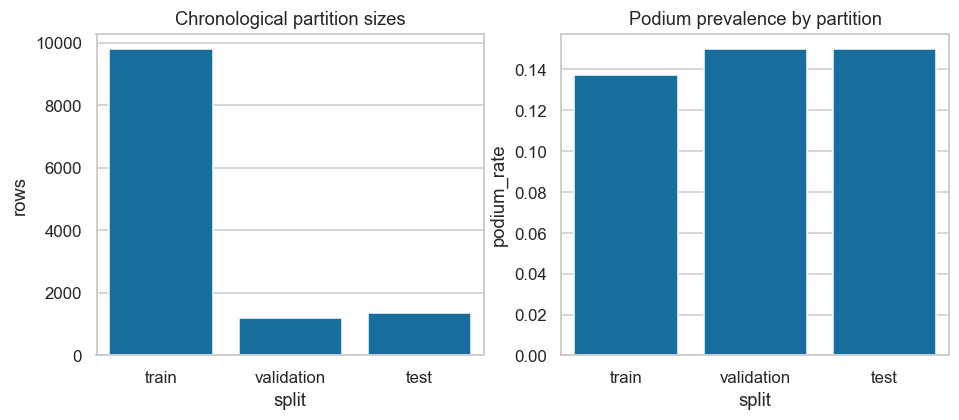

In [10]:
model_table['split'] = np.select([model_table.year.le(2018), model_table.year.le(2021)],
                                 ['train', 'validation'], default='test')
split_summary = model_table.groupby('split', sort=False).agg(
    rows=('y', 'size'), races=('raceId', 'nunique'), first_year=('year', 'min'),
    last_year=('year', 'max'), podium_rate=('y', 'mean')).reset_index()
assert model_table.groupby('raceId').split.nunique().max() == 1
assert model_table.loc[model_table.split.eq('train'), 'date'].max() < model_table.loc[model_table.split.eq('validation'), 'date'].min()
assert model_table.loc[model_table.split.eq('validation'), 'date'].max() < model_table.loc[model_table.split.eq('test'), 'date'].min()
display(split_summary)
split_summary.to_csv(OUT / 'tables' / 'split_summary.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
sns.barplot(data=split_summary, x='split', y='rows', ax=axes[0])
sns.barplot(data=split_summary, x='split', y='podium_rate', ax=axes[1])
axes[0].set_title('Chronological partition sizes')
axes[1].set_title('Podium prevalence by partition')
savefig('10_chronological_split', 'Race-grouped chronological split: same-race entries stay together; prevalence measures class imbalance.')

### 3.2 Evidence behind feature choices (training rows only)
Grid and qualifying describe starting opportunity. Shifted driver/team form measures
recent competitiveness, while previous-round standings measure current-season form.
Age, home-country flag, calendar and circuit history are exploratory context features.
They are hypotheses, not guaranteed improvements: group ablation measures their actual
validation contribution. A session-wide qualifying time gap normalizes circuit length
but mixes Q1/Q2/Q3 conditions and formats; its interpretation has this limitation.
Past points reflect changes in the points system; year/round partly represent this
context but cannot fully remove era differences.

,feature,missing_fraction,spearman_with_podium
0,grid,0.006,-0.484
1,grid_unassigned,0.000,-0.032
2,qualifying_position,0.190,-0.484
3,qualifying_gap_pct,0.203,-0.461
4,driver_form_podium_rate,0.012,0.505
5,driver_form_points,0.012,0.421
6,driver_form_finish,0.012,-0.408
7,driver_prior_starts,0.000,0.230
8,constructor_form_podium_rate,0.005,0.501
9,constructor_form_points,0.005,0.424


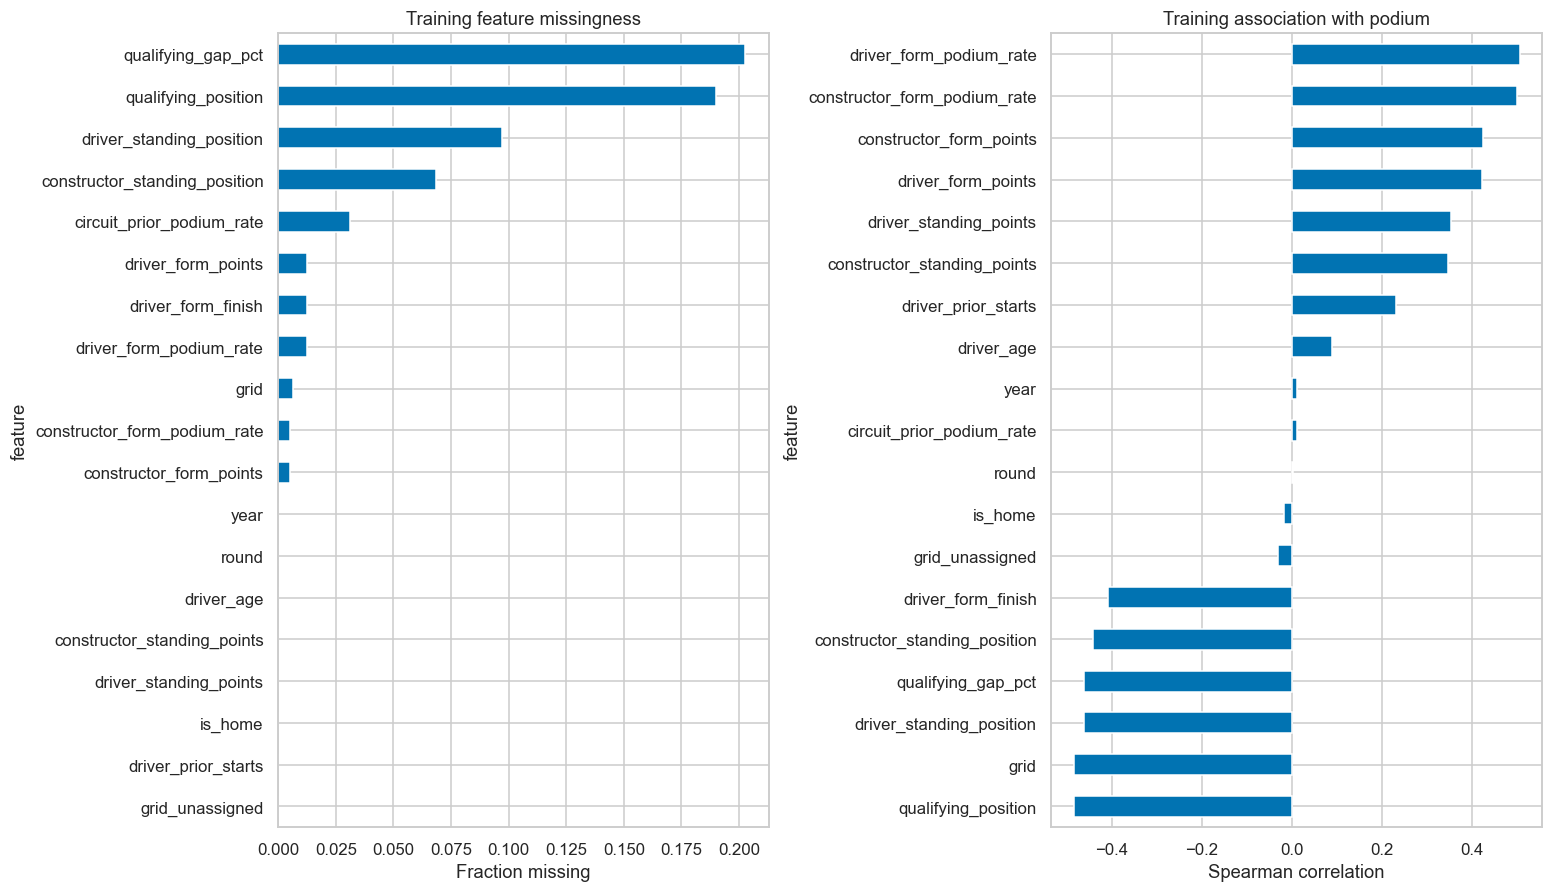

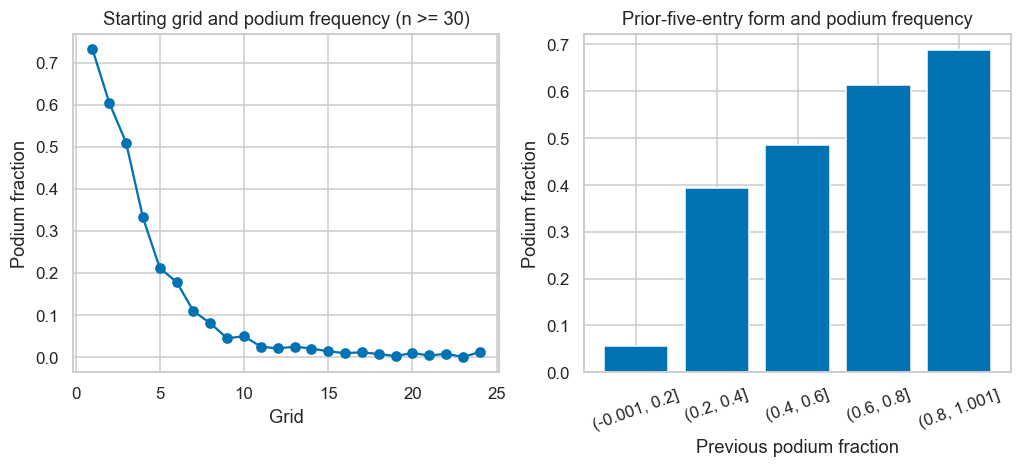

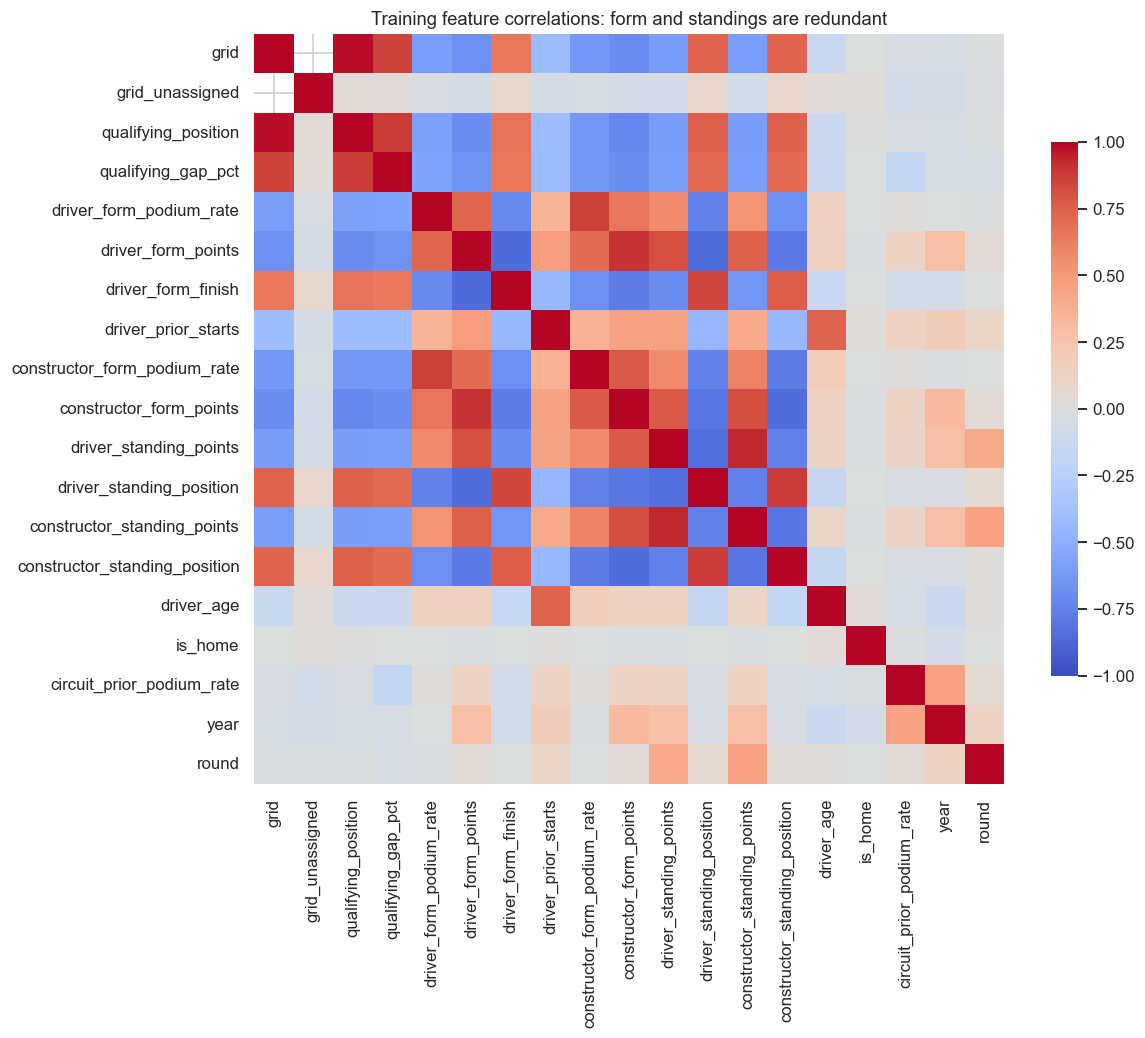

,feature,missing_fraction,spearman_with_podium,group,definition,motivation,missingness_policy,availability,evidence
0,grid,0.006225,-0.483514,grid,Final grid position; nonpositive values become...,Starting opportunity is expected to constrain ...,Median learned on training rows; grid_unassign...,Final published starting grid before race star...,Training missingness/correlation: 11_feature_e...
1,grid_unassigned,0.000000,-0.031596,grid,1 when the final grid is missing or nonpositiv...,Distinguishes pit-lane/unrecorded grid from an...,Derived from grid before imputation; never sup...,Final published starting grid before race star...,Training missingness/correlation: 11_feature_e...
2,qualifying_position,0.189917,-0.484408,qualifying,Recorded classification position in completed ...,Reflects weekend pace while allowing penalties...,"No observed session row stays missing, with a ...",Current qualifying positions and completed qua...,Training missingness/correlation: 11_feature_e...
3,qualifying_gap_pct,0.202776,-0.460778,qualifying,100 * (driver best Q1/Q2/Q3 seconds / race ses...,"Normalizes lap duration across circuits, while...",Missing timing stays missing until train-fitte...,Current qualifying positions and completed qua...,Training missingness/correlation: 11_feature_e...
4,driver_form_podium_rate,0.012450,0.505134,form,Mean podium label across this driver's previou...,Recent results summarize competitiveness using...,Fewer than five prior entries use available hi...,Only earlier completed Grand Prix results; dri...,Training missingness/correlation: 11_feature_e...
5,driver_form_points,0.012450,0.420895,form,Mean points across this driver's previous five...,Provides a graded recent-performance measure b...,No prior entries remains missing; changing sco...,Only earlier completed Grand Prix results; dri...,Training missingness/correlation: 11_feature_e...
6,driver_form_finish,0.012450,-0.408423,form,Mean positionOrder across this driver's previo...,"Adds recent finishing consistency, including n...",No prior entries remains missing; no current o...,Only earlier completed Grand Prix results; dri...,Training missingness/correlation: 11_feature_e...
7,driver_prior_starts,0.000000,0.230143,form,"Cumulative earlier recorded starts, excluding ...",Represents experience and distinguishes debut ...,A debut has zero starts; positive recorded lap...,Only earlier completed Grand Prix results; dri...,Training missingness/correlation: 11_feature_e...
8,constructor_form_podium_rate,0.005103,0.500504,form,Previous-five-constructor-race mean of within-...,Captures recent team strength without leaking ...,First constructor race remains missing; availa...,Only earlier completed Grand Prix results; dri...,Training missingness/correlation: 11_feature_e...
9,constructor_form_points,0.005103,0.423673,form,Previous-five-constructor-race mean of within-...,Summarizes recent team competitiveness without...,First constructor race remains missing; team I...,Only earlier completed Grand Prix results; dri...,Training missingness/correlation: 11_feature_e...


**Feature conclusion:** 19 pre-race predictors for 12,358 rows. The largest training univariate associations are driver_form_podium_rate, constructor_form_podium_rate, qualifying_position. Every history timestamp is strictly before the target race. Missing inputs are retained for train-fitted imputation, rather than removing hard cases.

In [11]:
train_evidence = model_table.loc[model_table.split.eq('train')].copy()
feature_stats = pd.DataFrame({'feature': FEATURES,
                              'missing_fraction': train_evidence[FEATURES].isna().mean().values,
                              'spearman_with_podium': [train_evidence[f].corr(train_evidence.y, method='spearman')
                                                       for f in FEATURES]})
feature_stats.to_csv(OUT / 'tables' / 'feature_evidence.csv', index=False)
display(feature_stats.round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 8), layout='constrained')
feature_stats.sort_values('missing_fraction').plot.barh(x='feature', y='missing_fraction', ax=axes[0], legend=False)
feature_stats.sort_values('spearman_with_podium').plot.barh(x='feature', y='spearman_with_podium', ax=axes[1], legend=False)
axes[0].set(title='Training feature missingness', xlabel='Fraction missing')
axes[1].set(title='Training association with podium', xlabel='Spearman correlation')
savefig('11_feature_evidence', 'Training-only feature evidence: missingness and univariate association are descriptive, not causal or independent effects.')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
grid_rates = train_evidence.groupby('grid').y.agg(['mean', 'size']).loc[lambda d: d['size'].ge(30)]
axes[0].plot(grid_rates.index, grid_rates['mean'], marker='o')
axes[0].set(title='Starting grid and podium frequency (n >= 30)', xlabel='Grid', ylabel='Podium fraction')
form_binned = train_evidence.assign(form_bin=pd.cut(train_evidence.driver_form_podium_rate,
                                [-.001, .2, .4, .6, .8, 1.001]))
form_rates = form_binned.groupby('form_bin', observed=True).y.agg(['mean', 'size'])
axes[1].bar(range(len(form_rates)), form_rates['mean'])
axes[1].set_xticks(range(len(form_rates)), [str(i) for i in form_rates.index], rotation=20)
axes[1].set(title='Prior-five-entry form and podium frequency', xlabel='Previous podium fraction', ylabel='Podium fraction')
savefig('12_feature_effects', 'Feature motivation: training podium rates by grid and strictly shifted driver form.')

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(train_evidence[FEATURES].corr(method='spearman'), cmap='coolwarm', vmin=-1, vmax=1,
            center=0, ax=ax, square=True, cbar_kws={'shrink': .7})
ax.set_title('Training feature correlations: form and standings are redundant')
savefig('13_feature_correlation', 'Correlated predictors motivate regularized logistic regression and grouped ablation; importance can be shared among correlated features.')

availability = {
    'grid': 'Final published starting grid before race start; zero is treated as missing.',
    'qualifying': 'Current qualifying positions and completed qualifying lap times before start.',
    'form': 'Only earlier completed Grand Prix results; driver entry rolling mean and team race aggregation shifted once.',
    'standings': 'Snapshot after previous Grand Prix in same season; round one has zero points and missing rank.',
    'context': 'Scheduled year/round, birth date, sporting nationality/circuit country, and earlier circuit races.'}
feature_definitions = {
    'grid': ('Final grid position; nonpositive values become missing.',
             'Starting opportunity is expected to constrain podium chances.',
             'Median learned on training rows; grid_unassigned retains absence.'),
    'grid_unassigned': ('1 when the final grid is missing or nonpositive; otherwise 0.',
             'Distinguishes pit-lane/unrecorded grid from an ordinary midfield start.',
             'Derived from grid before imputation; never supplied inconsistently.'),
    'qualifying_position': ('Recorded classification position in completed qualifying.',
             'Reflects weekend pace while allowing penalties to change the actual grid.',
             'No observed session row stays missing, with a training-derived indicator.'),
    'qualifying_gap_pct': ('100 * (driver best Q1/Q2/Q3 seconds / race session best - 1).',
             'Normalizes lap duration across circuits, while acknowledging session-condition differences.',
             'Missing timing stays missing until train-fitted imputation.'),
    'driver_form_podium_rate': ('Mean podium label across this driver\'s previous five listed entries.',
             'Recent results summarize competitiveness using only completed races.',
             'Fewer than five prior entries use available history; debut remains missing.'),
    'driver_form_points': ('Mean points across this driver\'s previous five listed entries.',
             'Provides a graded recent-performance measure beyond a binary podium.',
             'No prior entries remains missing; changing scoring rules are a limitation.'),
    'driver_form_finish': ('Mean positionOrder across this driver\'s previous five listed entries.',
             'Adds recent finishing consistency, including non-podium outcomes.',
             'No prior entries remains missing; no current outcome is included.'),
    'driver_prior_starts': ('Cumulative earlier recorded starts, excluding explicit nonstarters.',
             'Represents experience and distinguishes debut from a missing form value.',
              'A debut has zero starts; positive recorded laps override W/F/withdrawal labels. Without positive laps, explicit nonstart labels are excluded. N remains a start; zero grid/laps alone does not prove DNS.'),
    'constructor_form_podium_rate': ('Previous-five-constructor-race mean of within-race entry podium fractions.',
             'Captures recent team strength without leaking a current-race teammate outcome.',
             'First constructor race remains missing; available earlier races otherwise used.'),
    'constructor_form_points': ('Previous-five-constructor-race mean of within-race points per entry.',
             'Summarizes recent team competitiveness without favoring larger historical lineups.',
             'First constructor race remains missing; team IDs do not inherit renamed teams.'),
    'driver_standing_points': ('Driver points in the snapshot after the preceding round of the same season.',
             'Summarizes current-season performance available before the current race.',
             'Round one or no prior snapshot entry has zero observed season points.'),
    'driver_standing_position': ('Driver championship position after the preceding same-season round.',
             'Adds relative current-season competitiveness alongside absolute points.',
             'Round one or absent prior snapshot leaves the rank missing.'),
    'constructor_standing_points': ('Constructor points after the preceding round of the same season.',
             'Represents accumulated team strength before the current race.',
             'Round one or absent prior snapshot entry has zero observed season points.'),
    'constructor_standing_position': ('Constructor championship position after the preceding same-season round.',
             'Adds the team\'s relative position under the current scoring system.',
             'Round one or absent prior snapshot leaves rank missing.'),
    'driver_age': ('Days from driver birth date to race date divided by 365.2425.',
             'Exploratory experience/context hypothesis, tested by context ablation.',
             'Missing date of birth would remain missing until training imputation.'),
    'is_home': ('1 if mapped sporting nationality includes the circuit country; otherwise 0.',
             'Tests the observed home-country association without treating it as causal.',
             'Unmapped nationality remains missing rather than being classified away.'),
    'circuit_prior_podium_rate': ('Mean entry podium fraction across the circuit\'s previous five races.',
             'Historical field-size/circuit context is an exploratory hypothesis.',
             'First observed circuit race remains missing.'),
    'year': ('Scheduled calendar season.',
             'Represents broad eras and scoring/format changes, with extrapolation limits.',
             'Required calendar metadata; present in every modeling row.'),
    'round': ('Scheduled round number within the season.',
             'Allows season progression to modify other competitiveness signals.',
             'Required calendar metadata; present in every modeling row.')
}
assert set(feature_definitions) == set(FEATURES)
feature_catalog = feature_stats.merge(pd.DataFrame([
    {'feature': f, 'group': g, 'definition': feature_definitions[f][0],
     'motivation': feature_definitions[f][1], 'missingness_policy': feature_definitions[f][2],
     'availability': availability[g],
     'evidence': 'Training missingness/correlation: 11_feature_evidence; grid/form rates: '
                 '12_feature_effects; redundancy: 13_feature_correlation; group ablation: feature_group_ablation.'}
    for g, fs in FEATURE_GROUPS.items() for f in fs]),
    on='feature', validate='one_to_one')
feature_catalog.to_csv(OUT / 'tables' / 'feature_catalog.csv', index=False)
display(feature_catalog)
strongest = feature_stats.set_index('feature').spearman_with_podium.abs().nlargest(3).index.tolist()
data_summary.update({'model_rows': len(model_table), 'model_features': len(FEATURES),
                     'feature_evidence': f'The largest training univariate associations are {", ".join(strongest)}.',
                     'cutoff': 'After qualifying and final grid, immediately before the Grand Prix starts.'})
(OUT / 'data_summary.json').write_text(json.dumps(data_summary, indent=2), encoding='utf-8')
display(Markdown(f"**Feature conclusion:** {len(FEATURES)} pre-race predictors for {len(model_table):,} rows. "
                 f"{data_summary['feature_evidence']} Every history timestamp is strictly before the target race. "
                 "Missing inputs are retained for train-fitted imputation, rather than removing hard cases."))

## 4. Lab-aligned models, experiments, explanation, and inference

We predict podium versus no podium. All three attempts use the same original
19 features and driver-race rows. Entire races stay together: 1994-2018 trains,
2019-2021 validates, and 2022-2024 is the future-season holdout, isolated from
fitting and selection. This corrective rerun follows an audit of earlier test
results; it is a corrected evaluation on the same holdout, not a new blind test.
Split boundaries, candidate grids and selection rules are unchanged. Random
row splitting from the classroom examples would let teammates and nearby
events cross partitions, and would not represent predicting future seasons.

Lab 1 supplies median filling; Lab 3 supplies explicit StandardScaler,
Sequential/Dense, compile(), fit(), EarlyStopping, and History plots. Lab 2
supplies sklearn classification and its metrics; Lab 4 supplies forest, SHAP,
and LIME. The temporal split, historical shifts, exact AP callback, and
preprocessing experiments adapt those methods to this milestone.

**Declared selection rule:** maximize validation average precision (AP), a
useful minority-class ranking measure. AP is the recall-weighted sum of
precision, while trapezoidal PR-AUC linearly interpolates the PR curve. We
report both, alongside ROC-AUC (overall ranking), precision, recall and F1
(decisions at a threshold). Brier score additionally describes probability
error. Thresholds maximize validation F1, with larger thresholds breaking ties.
Accuracy alone could hide poor podium detection. No holdout value is used for
hyperparameters, checkpoint selection, thresholds, features, or experiments.

In [12]:
import json
import time
import joblib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_recall_curve,
    roc_curve, auc, f1_score, precision_score, recall_score,
    ConfusionMatrixDisplay, brier_score_loss,
)

TABLES = OUT / "tables"
MODELS_DIR = OUT / "models"
TABLES.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
model_figures = []
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.config.threading.set_intra_op_parallelism_threads(2)
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

train_rows = model_table.loc[model_table["year"].between(1994, 2018)].copy()
val_rows = model_table.loc[model_table["year"].between(2019, 2021)].copy()
test_rows = model_table.loc[model_table["year"].between(2022, 2024)].copy()
X_train = train_rows[FEATURES].astype(float)
X_val = val_rows[FEATURES].astype(float)
X_test = test_rows[FEATURES].astype(float)
y_train = train_rows["y"].to_numpy(dtype=int)
y_val = val_rows["y"].to_numpy(dtype=int)
y_test = test_rows["y"].to_numpy(dtype=int)
assert len(X_train) and len(X_val) and len(X_test)
assert set(train_rows.raceId).isdisjoint(val_rows.raceId)
assert set(train_rows.raceId).isdisjoint(test_rows.raceId)
assert set(val_rows.raceId).isdisjoint(test_rows.raceId)
assert not X_train.isna().all().any()
assert not np.isinf(model_table[FEATURES].to_numpy(dtype=float)).any()
assert not set(FEATURES) & {"y", "positionOrder", "points", "statusId", "laps", "milliseconds"}
assert all(frame.columns.tolist() == FEATURES for frame in [X_train, X_val, X_test])
for frame in [X_train, X_val, X_test]:
    assert np.array_equal(frame.grid_unassigned.to_numpy(), frame.grid.isna().astype(int).to_numpy())

split_summary = pd.DataFrame([
    {"split": name, "years": years, "rows": len(rows), "races": rows.raceId.nunique(),
     "podiums": int(rows.y.sum()), "podium_rate": rows.y.mean()}
    for name, years, rows in [("train", "1994-2018", train_rows),
                              ("validation", "2019-2021", val_rows),
                              ("test", "2022-2024", test_rows)]
])
split_summary.to_csv(TABLES / "split_summary.csv", index=False)
display(split_summary)

,split,years,rows,races,podiums,podium_rate
0,train,1994-2018,9799,449,1347,0.137463
1,validation,2019-2021,1200,60,180,0.150000
2,test,2022-2024,1359,68,204,0.150110


### 4.1 Training-only preprocessing shared by all attempts

We retain raw missingness in X. Fit medians on training only, fill with Pandas
fillna(), append a missingness indicator for each column missing in training,
and fit StandardScaler to that completed training frame. Validation, holdout,
and inference call transform() with these same stored statistics and column
order. The dictionary below stores ordinary objects instead of a nested
preprocessing pipeline or custom transformer. Binary flags are standardized
consistently with the other inputs; scaling does not erase their two values.
The already derived grid_unassigned flag is never median-filled in inference.

In [13]:
def append_missing_flags(filled_frame, original_frame, indicator_features):
    """Keep the missingness observed before filling, in an explicit column order."""
    completed = filled_frame.copy()
    for feature in indicator_features:
        completed["missing_" + feature] = original_frame[feature].isna().astype(float)
    return completed


def fit_preprocessing(training_frame):
    """Fit only on the supplied training rows; return portable library objects."""
    features = list(training_frame.columns)
    medians = training_frame.median()
    assert medians.notna().all(), "A training feature has no observed value."
    indicator_features = [f for f in features if training_frame[f].isna().any()]
    completed = append_missing_flags(training_frame.fillna(medians), training_frame, indicator_features)
    scaler = StandardScaler()
    scaler.fit(completed)
    return {"features": features, "medians": medians,
            "indicator_features": indicator_features,
            "transformed_features": list(completed.columns), "scaler": scaler}


def transform_frame(frame, bundle):
    """Apply frozen training medians, indicator schema, and scaler; never refit."""
    original = frame[bundle["features"]].astype(float)
    completed = append_missing_flags(original.fillna(bundle["medians"]), original,
                                     bundle["indicator_features"])
    assert list(completed.columns) == bundle["transformed_features"]
    transformed = bundle["scaler"].transform(completed)
    assert np.isfinite(transformed).all()
    return transformed


preprocessing = fit_preprocessing(X_train)
Z_train = transform_frame(X_train, preprocessing)
Z_val = transform_frame(X_val, preprocessing)
transformed_names = preprocessing["transformed_features"]
assert len(transformed_names) == len(FEATURES) + len(preprocessing["indicator_features"])
preprocessing_audit = pd.DataFrame({
    "feature": FEATURES,
    "training_median": preprocessing["medians"].reindex(FEATURES).values,
    "training_missing_rows": X_train.isna().sum().values,
    "has_missing_indicator": [f in preprocessing["indicator_features"] for f in FEATURES],
})
preprocessing_audit.to_csv(TABLES / "fitted_preprocessing.csv", index=False)
display(preprocessing_audit)


def choose_threshold(y, probabilities):
    precision, recall, thresholds = precision_recall_curve(y, probabilities)
    scores = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    best = np.flatnonzero(np.isclose(scores, scores.max(), rtol=0, atol=1e-12))[-1]
    return float(thresholds[best])


def metric_row(y, probabilities, threshold):
    precision, recall, _ = precision_recall_curve(y, probabilities)
    predictions = (np.asarray(probabilities) >= threshold).astype(int)
    return {"ROC_AUC": float(roc_auc_score(y, probabilities)),
            "AP": float(average_precision_score(y, probabilities)),
            "PR_AUC": float(auc(recall, precision)),
            "F1": float(f1_score(y, predictions, zero_division=0)),
            "precision": float(precision_score(y, predictions, zero_division=0)),
            "recall": float(recall_score(y, predictions, zero_division=0)),
            "Brier": float(brier_score_loss(y, probabilities)), "threshold": float(threshold)}


models, best_configs, validation_probabilities = {}, {}, {}
tuning_records = []
model_start = time.perf_counter()


def show_attempt_comparison(model_name):
    baseline_ap = average_precision_score(y_val, validation_probabilities["Logistic regression"])
    comparison = pd.DataFrame([
        {"model": name, **metric_row(y_val, p, choose_threshold(y_val, p)),
         "delta_AP_vs_baseline": float(average_precision_score(y_val, p) - baseline_ap)}
        for name, p in validation_probabilities.items()
    ])
    display(comparison.round(4))
    current = comparison.set_index("model").loc[model_name]
    display(Markdown(f"**{model_name}:** validation AP **{current.AP:.4f}**, change versus "
                     f"logistic baseline **{current.delta_AP_vs_baseline:+.4f}**; "
                     f"F1 **{current.F1:.4f}** at validation-selected threshold "
                     f"**{current.threshold:.4f}**. Same rows and feature inputs in every attempt."))
    return comparison

,feature,training_median,training_missing_rows,has_missing_indicator
0,grid,11.000000,61,True
1,grid_unassigned,0.000000,0,False
2,qualifying_position,11.000000,1861,True
3,qualifying_gap_pct,1.972081,1987,True
4,driver_form_podium_rate,0.000000,122,True
5,driver_form_points,0.800000,122,True
6,driver_form_finish,11.800000,122,True
7,driver_prior_starts,60.000000,0,False
8,constructor_form_podium_rate,0.000000,50,True
9,constructor_form_points,1.000000,50,True


#### 4.1.1 Attempt 1 - Logistic regression baseline (Labs 2-3)

LogisticRegression.fit() learns an additive score and sigmoid probability.
Regularization controls large coefficients among correlated form, qualifying,
and standings features. Its limitation is the lack of automatically learned
nonlinear interactions. Six small candidate combinations compare C (inverse
regularization) and class weighting on validation AP. Balanced weights alter
the learning objective and may hurt calibration; Brier is reported as well.

In [14]:
logistic_candidates = []
logistic_configs = [{"C": c, "class_weight": weight}
                    for c in [0.1, 1.0, 10.0] for weight in [None, "balanced"]]
for config in logistic_configs:
    estimator = LogisticRegression(**config, max_iter=2000, random_state=SEED)
    estimator.fit(Z_train, y_train)
    probabilities = estimator.predict_proba(Z_val)[:, 1]
    score = float(average_precision_score(y_val, probabilities))
    tuning_records.append({"model": "Logistic regression", "config": json.dumps(config),
                           "validation_AP": score, "epochs": np.nan, "trained_epochs": np.nan})
    logistic_candidates.append((score, estimator, config, probabilities))
chosen_logistic = max(logistic_candidates, key=lambda result: result[0])
models["Logistic regression"] = chosen_logistic[1]
best_configs["Logistic regression"] = chosen_logistic[2]
validation_probabilities["Logistic regression"] = chosen_logistic[3]
display(pd.DataFrame([r for r in tuning_records if r["model"] == "Logistic regression"]))
attempt_comparison = show_attempt_comparison("Logistic regression")

,model,config,validation_AP,epochs,trained_epochs
0,Logistic regression,"{""C"": 0.1, ""class_weight"": null}",0.714582,NaN,NaN
1,Logistic regression,"{""C"": 0.1, ""class_weight"": ""balanced""}",0.706418,NaN,NaN
2,Logistic regression,"{""C"": 1.0, ""class_weight"": null}",0.714423,NaN,NaN
3,Logistic regression,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.707619,NaN,NaN
4,Logistic regression,"{""C"": 10.0, ""class_weight"": null}",0.714095,NaN,NaN
5,Logistic regression,"{""C"": 10.0, ""class_weight"": ""balanced""}",0.707626,NaN,NaN


,model,ROC_AUC,AP,PR_AUC,F1,precision,recall,Brier,threshold,delta_AP_vs_baseline
0,Logistic regression,0.9327,0.7146,0.7128,0.7225,0.6345,0.8389,0.0655,0.2064,0.0


**Logistic regression:** validation AP **0.7146**, change versus logistic baseline **+0.0000**; F1 **0.7225** at validation-selected threshold **0.2064**. Same rows and feature inputs in every attempt.

#### 4.1.2 Attempt 2 - Random forest versus the baseline (Lab 4)

RandomForestClassifier.fit() averages trees trained on bootstrap samples with
random feature subsets. It can learn nonlinear starting-grid/form interactions.
Depth and minimum leaf size restrain overfitting, though historical rule changes
remain a limitation. Four configurations receive exactly the same Z_train and
Z_val as logistic regression. Trees do not need scaling, but receive it so the
comparison and the saved preprocessing remain consistent.

In [15]:
forest_candidates = []
forest_configs = [{"max_depth": depth, "min_samples_leaf": leaf}
                  for depth in [8, None] for leaf in [4, 12]]
for config in forest_configs:
    estimator = RandomForestClassifier(**config, n_estimators=200,
                                       max_features="sqrt", n_jobs=2, random_state=SEED)
    estimator.fit(Z_train, y_train)
    probabilities = estimator.predict_proba(Z_val)[:, 1]
    score = float(average_precision_score(y_val, probabilities))
    tuning_records.append({"model": "Random forest", "config": json.dumps(config),
                           "validation_AP": score, "epochs": np.nan, "trained_epochs": np.nan})
    forest_candidates.append((score, estimator, config, probabilities))
chosen_forest = max(forest_candidates, key=lambda result: result[0])
models["Random forest"] = chosen_forest[1]
best_configs["Random forest"] = chosen_forest[2]
validation_probabilities["Random forest"] = chosen_forest[3]
display(pd.DataFrame([r for r in tuning_records if r["model"] == "Random forest"]))
attempt_comparison = show_attempt_comparison("Random forest")

,model,config,validation_AP,epochs,trained_epochs
0,Random forest,"{""max_depth"": 8, ""min_samples_leaf"": 4}",0.736803,NaN,NaN
1,Random forest,"{""max_depth"": 8, ""min_samples_leaf"": 12}",0.740941,NaN,NaN
2,Random forest,"{""max_depth"": null, ""min_samples_leaf"": 4}",0.735370,NaN,NaN
3,Random forest,"{""max_depth"": null, ""min_samples_leaf"": 12}",0.743172,NaN,NaN


,model,ROC_AUC,AP,PR_AUC,F1,precision,recall,Brier,threshold,delta_AP_vs_baseline
0,Logistic regression,0.9327,0.7146,0.7128,0.7225,0.6345,0.8389,0.0655,0.2064,0.0000
1,Random forest,0.9417,0.7432,0.7408,0.7352,0.6842,0.7944,0.0627,0.3682,0.0286


**Random forest:** validation AP **0.7432**, change versus logistic baseline **+0.0286**; F1 **0.7352** at validation-selected threshold **0.3682**. Same rows and feature inputs in every attempt.

### 4.2 Attempt 3 - Shallow Keras network versus the baseline (Lab 3)

Sequential contains one hidden Dense ReLU layer and one sigmoid output for
binary classification. compile() selects binary cross-entropy and Adam;
fit() manages batches, gradients, validation, and History. Small L2 kernel
penalties discourage large weights. Three candidates test hidden width and L2
strength. This network learns a continuous nonlinear representation, but can
overfit the limited historical sample and temporal drift. Its flexibility must
earn a measured improvement over the baseline.

The lab monitors validation accuracy. Here a short callback computes **exact
sklearn AP** after every epoch. It writes val_ap into logs BEFORE EarlyStopping
reads it. EarlyStopping(mode='max', restore_best_weights=True) restores the
highest-AP epoch; no manual checkpoint management or batch-training loop is used.
Explicit validation_data uses 2019-2021; no random validation_split is introduced.
The callback is the only extra Keras class needed for this task's selection rule.

Neural candidate {'hidden_dim': 16, 'l2': 0.001}: validation AP=0.7336, restored epoch=86, trained epochs=106


Neural candidate {'hidden_dim': 32, 'l2': 0.001}: validation AP=0.7330, restored epoch=46, trained epochs=66


Neural candidate {'hidden_dim': 32, 'l2': 0.01}: validation AP=0.7487, restored epoch=140, trained epochs=160


,model,config,validation_AP,epochs,trained_epochs
0,Shallow neural network,"{""hidden_dim"": 16, ""l2"": 0.001, ""learning_rate...",0.733622,86,106
1,Shallow neural network,"{""hidden_dim"": 32, ""l2"": 0.001, ""learning_rate...",0.732997,46,66
2,Shallow neural network,"{""hidden_dim"": 32, ""l2"": 0.01, ""learning_rate""...",0.748718,140,160


,model,ROC_AUC,AP,PR_AUC,F1,precision,recall,Brier,threshold,delta_AP_vs_baseline
0,Logistic regression,0.9327,0.7146,0.7128,0.7225,0.6345,0.8389,0.0655,0.2064,0.0000
1,Random forest,0.9417,0.7432,0.7408,0.7352,0.6842,0.7944,0.0627,0.3682,0.0286
2,Shallow neural network,0.9375,0.7487,0.7476,0.7352,0.6842,0.7944,0.0646,0.3471,0.0341


**Shallow neural network:** validation AP **0.7487**, change versus logistic baseline **+0.0341**; F1 **0.7352** at validation-selected threshold **0.3471**. Same rows and feature inputs in every attempt.

,model,config,validation_AP,epochs,trained_epochs
0,Logistic regression,"{""C"": 0.1, ""class_weight"": null}",0.714582,NaN,NaN
1,Logistic regression,"{""C"": 0.1, ""class_weight"": ""balanced""}",0.706418,NaN,NaN
2,Logistic regression,"{""C"": 1.0, ""class_weight"": null}",0.714423,NaN,NaN
3,Logistic regression,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.707619,NaN,NaN
4,Logistic regression,"{""C"": 10.0, ""class_weight"": null}",0.714095,NaN,NaN
5,Logistic regression,"{""C"": 10.0, ""class_weight"": ""balanced""}",0.707626,NaN,NaN
6,Random forest,"{""max_depth"": 8, ""min_samples_leaf"": 4}",0.736803,NaN,NaN
7,Random forest,"{""max_depth"": 8, ""min_samples_leaf"": 12}",0.740941,NaN,NaN
8,Random forest,"{""max_depth"": null, ""min_samples_leaf"": 4}",0.735370,NaN,NaN
9,Random forest,"{""max_depth"": null, ""min_samples_leaf"": 12}",0.743172,NaN,NaN


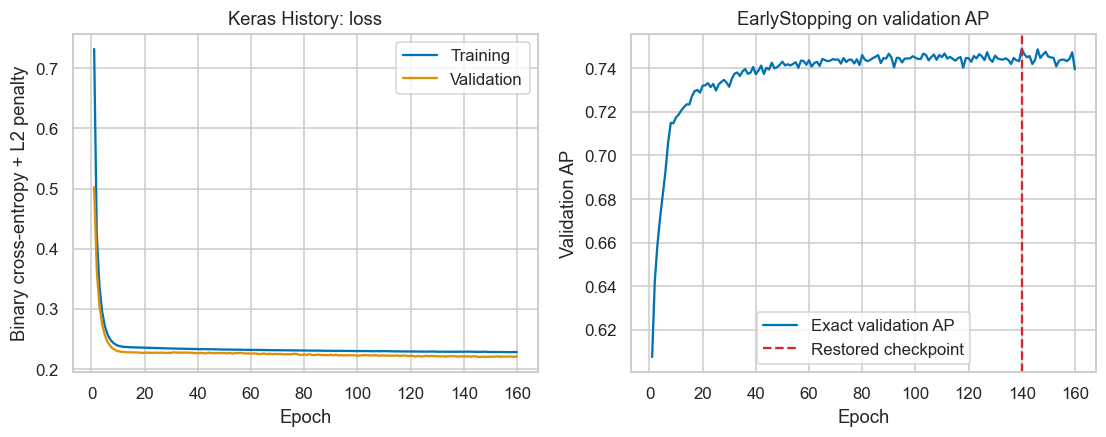

In [16]:
class ExactValidationAP(keras.callbacks.Callback):
    """Publish the task's exact validation metric before the stopping callback."""
    def __init__(self, inputs, labels):
        super().__init__()
        self.inputs = np.asarray(inputs, dtype=np.float32)
        self.labels = labels

    def on_epoch_end(self, epoch, logs=None):
        probabilities = self.model(self.inputs, training=False).numpy().ravel()
        logs["val_ap"] = float(average_precision_score(self.labels, probabilities))


neural_candidates, neural_history_records = [], []
neural_configs = [{"hidden_dim": 16, "l2": 0.001},
                  {"hidden_dim": 32, "l2": 0.001},
                  {"hidden_dim": 32, "l2": 0.01}]
for config in neural_configs:
    keras.utils.set_random_seed(SEED)
    network = keras.Sequential([
        layers.Input(shape=(Z_train.shape[1],)),
        layers.Dense(config["hidden_dim"], activation="relu",
                     kernel_regularizer=keras.regularizers.l2(config["l2"])),
        layers.Dense(1, activation="sigmoid"),
    ])
    network.compile(optimizer=keras.optimizers.Adam(learning_rate=0.003),
                    loss="binary_crossentropy", metrics=["accuracy"])
    exact_ap = ExactValidationAP(Z_val, y_val)
    early_stop = EarlyStopping(monitor="val_ap", mode="max", patience=20,
                               min_delta=0.0, restore_best_weights=True)
    history = network.fit(Z_train.astype(np.float32), y_train.astype(np.float32),
                          validation_data=(Z_val.astype(np.float32), y_val.astype(np.float32)),
                          epochs=180, batch_size=256, shuffle=True, verbose=0,
                          callbacks=[exact_ap, early_stop])
    probabilities = network(Z_val.astype(np.float32), training=False).numpy().ravel()
    score = float(average_precision_score(y_val, probabilities))
    best_epoch = int(np.argmax(history.history["val_ap"]) + 1)
    assert np.isclose(score, max(history.history["val_ap"])), "Best AP weights were not restored."
    candidate_config = {**config, "learning_rate": 0.003, "batch_size": 256,
                        "best_epoch": best_epoch}
    history_table = pd.DataFrame({"epoch": np.arange(1, len(history.history["loss"]) + 1),
                                  "training_loss": history.history["loss"],
                                  "validation_loss": history.history["val_loss"],
                                  "training_accuracy": history.history["accuracy"],
                                  "validation_accuracy": history.history["val_accuracy"],
                                  "validation_AP": history.history["val_ap"]})
    tuning_records.append({"model": "Shallow neural network", "config": json.dumps(candidate_config),
                           "validation_AP": score, "epochs": best_epoch,
                           "trained_epochs": len(history_table)})
    neural_history_records.append(history_table.assign(hidden_dim=config["hidden_dim"],
                                                        l2=config["l2"], selected_epoch=best_epoch))
    neural_candidates.append((score, network, candidate_config, history_table, probabilities))
    print(f"Neural candidate {config}: validation AP={score:.4f}, "
          f"restored epoch={best_epoch}, trained epochs={len(history_table)}")

chosen_nn = max(neural_candidates, key=lambda result: result[0])
nn_model = chosen_nn[1]
nn_preprocessor = preprocessing
models["Shallow neural network"] = nn_model
best_configs["Shallow neural network"] = chosen_nn[2]
nn_history = chosen_nn[3]
validation_probabilities["Shallow neural network"] = chosen_nn[4]
pd.concat(neural_history_records, ignore_index=True).to_csv(TABLES / "neural_training_histories.csv", index=False)
display(pd.DataFrame([r for r in tuning_records if r["model"] == "Shallow neural network"]))
attempt_comparison = show_attempt_comparison("Shallow neural network")
attempt_comparison.to_csv(TABLES / "validation_attempt_comparison.csv", index=False)
tuning_table = pd.DataFrame(tuning_records)
tuning_table.to_csv(TABLES / "tuning.csv", index=False)
assert len(tuning_table) == 13
display(tuning_table)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(nn_history.epoch, nn_history.training_loss, label="Training")
axes[0].plot(nn_history.epoch, nn_history.validation_loss, label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Binary cross-entropy + L2 penalty", title="Keras History: loss")
axes[0].legend()
axes[1].plot(nn_history.epoch, nn_history.validation_AP, label="Exact validation AP")
axes[1].axvline(chosen_nn[2]["best_epoch"], color="tab:red", ls="--", label="Restored checkpoint")
axes[1].set(xlabel="Epoch", ylabel="Validation AP", title="EarlyStopping on validation AP")
axes[1].legend()
savefig("neural_learning_curve.png", "Lab-style Keras History plots: training/validation loss and exact validation AP. EarlyStopping restores the maximum validation-AP weights.")
model_figures.append("neural_learning_curve.png")

### 4.3 Controlled experiments before opening the holdout
#### 4.3.1 Every feature group ablated

Remove one declared group at a time and retrain logistic regression with the
selected configuration fixed. Same training/validation rows; preprocessing is
refitted on training only for the retained columns. Full-feature logistic is
the reference. AP is threshold free; the F1 column uses each candidate's
validation-selected threshold. A negative delta means removal hurts. Positive
deltas are retained honestly: correlated inputs may substitute for one another,
and a hypothesis-supported feature need not improve every fitted model.

,group_removed,feature_count,AP,delta_AP,F1,threshold
0,None (all features),19,0.714582,0.000000,0.722488,0.206441
1,grid,17,0.697207,-0.017375,0.711779,0.316250
2,qualifying,17,0.710377,-0.004205,0.723618,0.278950
3,form,13,0.707218,-0.007364,0.724409,0.357927
4,standings,15,0.715147,0.000566,0.726343,0.313815
5,context,14,0.724931,0.010349,0.727273,0.388196


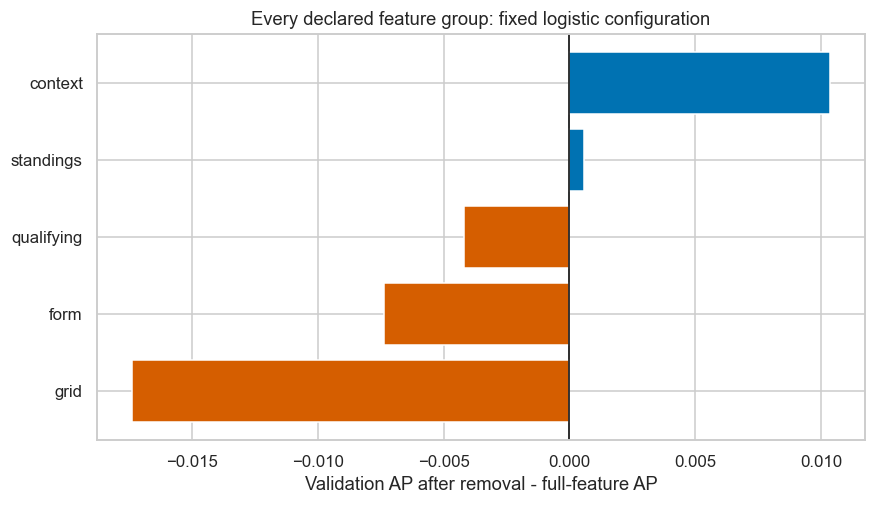

In [17]:
full_lr_ap = float(average_precision_score(y_val, validation_probabilities["Logistic regression"]))
full_lr_threshold = choose_threshold(y_val, validation_probabilities["Logistic regression"])
ablation_records = [{"group_removed": "None (all features)", "feature_count": len(FEATURES),
                     "AP": full_lr_ap, "delta_AP": 0.0,
                     "F1": float(f1_score(y_val, validation_probabilities["Logistic regression"] >= full_lr_threshold)),
                     "threshold": full_lr_threshold}]
for group, group_features in FEATURE_GROUPS.items():
    kept = [f for f in FEATURES if f not in group_features]
    assert 0 < len(kept) < len(FEATURES)
    ablated_preprocessing = fit_preprocessing(X_train[kept])
    ablated = LogisticRegression(**best_configs["Logistic regression"], max_iter=2000, random_state=SEED)
    ablated.fit(transform_frame(X_train[kept], ablated_preprocessing), y_train)
    probabilities = ablated.predict_proba(transform_frame(X_val[kept], ablated_preprocessing))[:, 1]
    threshold = choose_threshold(y_val, probabilities)
    score = float(average_precision_score(y_val, probabilities))
    ablation_records.append({"group_removed": group, "feature_count": len(kept),
                             "AP": score, "delta_AP": score - full_lr_ap,
                             "F1": float(f1_score(y_val, probabilities >= threshold)), "threshold": threshold})
ablation_table = pd.DataFrame(ablation_records)
assert set(ablation_table.group_removed.iloc[1:]) == set(FEATURE_GROUPS)
ablation_table.to_csv(TABLES / "ablation.csv", index=False)
display(ablation_table)
fig, ax = plt.subplots(figsize=(9, 4.8))
plot_ablation = ablation_table.iloc[1:].sort_values("delta_AP")
ax.barh(plot_ablation.group_removed, plot_ablation.delta_AP,
        color=np.where(plot_ablation.delta_AP < 0, "#d55e00", "#0072b2"))
ax.axvline(0, color="black", lw=1)
ax.set(xlabel="Validation AP after removal - full-feature AP",
       title="Every declared feature group: fixed logistic configuration")
savefig("feature_group_ablation.png", "Validation-only ablation of every feature group, with fixed logistic hyperparameters and unchanged rows. Improvements after removal are also shown.")
model_figures.append("feature_group_ablation.png")

#### 4.3.2 Two preprocessing-order comparisons using explicit operations

**A:** median filling then StandardScaler versus StandardScaler fitted to
observed values then median filling in scaled units. StandardScaler ignores
NaNs when fitting. Filling before fitting its variance can therefore change
values and regularized model behavior. Flags follow the same schema and are
standardized in both variants.

**B:** training 1st/99th-percentile clipping then filling/scaling versus filling
and scaling then training 1st/99th-percentile clipping. Percentile clipping
(winsorization) is an additional technique beyond the labs: it bounds extreme
continuous inputs instead of deleting rows. Only continuous columns are
clipped. Binary original columns and appended missing indicators retain both
values, including the rare grid_unassigned flag. All medians, scales and bounds
come exclusively from training; validation rows and logistic settings stay fixed.

These are diagnostic experiments. The primary three attempts retain the
predeclared impute-then-scale preprocessing. A uses a feature actually missing
in training; B uses a continuous feature with a long range. The table measures
changed values, range and dispersion as well as validation performance.

,order,ROC_AUC,AP,PR_AUC,F1,precision,recall,Brier,threshold
0,A0: impute → scale (baseline),0.932745,0.714582,0.712755,0.722488,0.634454,0.838889,0.065490,0.206441
1,A1: scale → impute,0.932625,0.714788,0.712964,0.721228,0.668246,0.783333,0.065521,0.336444
2,B0: clip → impute → scale,0.932702,0.703887,0.701152,0.723404,0.629630,0.850000,0.065567,0.209226
3,B1: impute → scale → clip,0.932549,0.704881,0.702148,0.724936,0.674641,0.783333,0.065562,0.367379


,order,feature,training_missing_rows,minimum,maximum,mean,standard_deviation,changed_vs_A0,maximum_absolute_change_vs_A0,binary_or_indicator_protected
3,A0: impute → scale (baseline),qualifying_gap_pct,1987,-0.262548,95.959018,-1.305212e-17,1.000000,0,0.000000,False
7,A0: impute → scale (baseline),driver_prior_starts,0,-1.134986,3.355927,-6.961129e-17,1.000000,0,0.000000,False
33,A1: scale → impute,qualifying_gap_pct,1987,-0.247453,85.701727,-1.293439e-02,0.893242,9799,10.257291,False
37,A1: scale → impute,driver_prior_starts,0,-1.134986,3.355927,-6.961129e-17,1.000000,0,0.000000,False
63,B0: clip → impute → scale,qualifying_gap_pct,1987,-1.221448,4.956143,-2.653930e-16,1.000000,9799,91.002875,False
67,B0: clip → impute → scale,driver_prior_starts,0,-1.139078,2.910645,-6.961129e-17,1.000000,9799,0.445281,False
93,B1: impute → scale → clip,qualifying_gap_pct,1987,-0.262548,0.827125,-1.695586e-02,0.195650,98,95.131894,False
97,B1: impute → scale → clip,driver_prior_starts,0,-1.134986,2.894244,-1.671878e-03,0.994939,95,0.461683,False


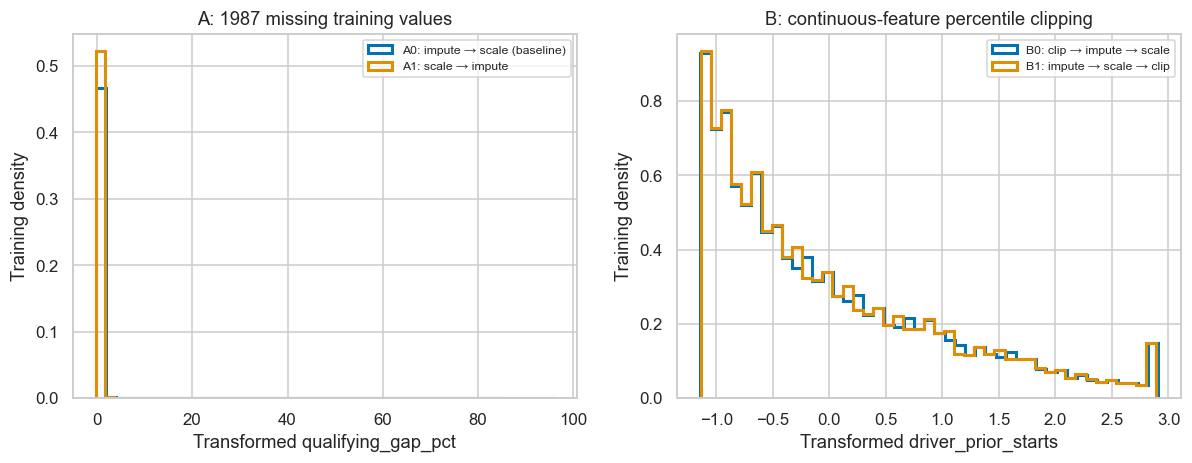

**Observed transformation effect:** qualifying_gap_pct has 1,987 training missing values. Its maximum absolute A1-vs-A0 transformed change is **10.2573**. All 13 binary/indicator columns match the unclipped baseline in both clipping variants. Range/value evidence is exported for every feature and order.

In [18]:
binary_features = [f for f in FEATURES if set(X_train[f].dropna().unique()).issubset({0.0, 1.0})]
continuous_features = [f for f in FEATURES if f not in binary_features]
continuous_indices = [transformed_names.index(f) for f in continuous_features]
protected_indices = [transformed_names.index(f) for f in binary_features]
protected_indices += list(range(len(FEATURES), len(transformed_names)))
assert "grid_unassigned" in binary_features

# A0 is exactly the already fitted primary preprocessing.
transformed_orders = {"A0: impute → scale (baseline)": Z_train}
validation_orders = {"A0: impute → scale (baseline)": Z_val}

# A1: fit the scale to observed values first, then fill with training scaled medians.
flagged_train = append_missing_flags(X_train, X_train, preprocessing["indicator_features"])
flagged_val = append_missing_flags(X_val, X_val, preprocessing["indicator_features"])
scale_first = StandardScaler()
scaled_train = pd.DataFrame(scale_first.fit_transform(flagged_train), columns=transformed_names, index=X_train.index)
scaled_val = pd.DataFrame(scale_first.transform(flagged_val), columns=transformed_names, index=X_val.index)
scaled_medians = scaled_train.median()
transformed_orders["A1: scale → impute"] = scaled_train.fillna(scaled_medians).to_numpy()
validation_orders["A1: scale → impute"] = scaled_val.fillna(scaled_medians).to_numpy()

# B0: bounds on observed raw continuous values; missing flags still come from raw X.
raw_lower = X_train[continuous_features].quantile(0.01)
raw_upper = X_train[continuous_features].quantile(0.99)
clipped_train, clipped_val = X_train.copy(), X_val.copy()
clipped_train[continuous_features] = X_train[continuous_features].clip(raw_lower, raw_upper, axis=1)
clipped_val[continuous_features] = X_val[continuous_features].clip(raw_lower, raw_upper, axis=1)
clip_medians = clipped_train.median()
clip_completed_train = append_missing_flags(clipped_train.fillna(clip_medians), X_train, preprocessing["indicator_features"])
clip_completed_val = append_missing_flags(clipped_val.fillna(clip_medians), X_val, preprocessing["indicator_features"])
clip_first_scaler = StandardScaler()
transformed_orders["B0: clip → impute → scale"] = clip_first_scaler.fit_transform(clip_completed_train)
validation_orders["B0: clip → impute → scale"] = clip_first_scaler.transform(clip_completed_val)

# B1: impute and scale first; bounds on completed/scaled training continuous values.
scaled_lower = np.quantile(Z_train[:, continuous_indices], 0.01, axis=0)
scaled_upper = np.quantile(Z_train[:, continuous_indices], 0.99, axis=0)
clip_last_train, clip_last_val = Z_train.copy(), Z_val.copy()
clip_last_train[:, continuous_indices] = np.clip(clip_last_train[:, continuous_indices], scaled_lower, scaled_upper)
clip_last_val[:, continuous_indices] = np.clip(clip_last_val[:, continuous_indices], scaled_lower, scaled_upper)
transformed_orders["B1: impute → scale → clip"] = clip_last_train
validation_orders["B1: impute → scale → clip"] = clip_last_val

preprocessing_records, preprocessing_effect_records = [], []
for order_name, inputs in transformed_orders.items():
    assert np.isfinite(inputs).all() and np.isfinite(validation_orders[order_name]).all()
    # Clipping must preserve every original binary column and missingness flag.
    if order_name.startswith("B"):
        np.testing.assert_allclose(inputs[:, protected_indices], Z_train[:, protected_indices], atol=1e-12)
        np.testing.assert_allclose(validation_orders[order_name][:, protected_indices], Z_val[:, protected_indices], atol=1e-12)
    estimator = LogisticRegression(**best_configs["Logistic regression"], max_iter=2000, random_state=SEED)
    estimator.fit(inputs, y_train)
    probabilities = estimator.predict_proba(validation_orders[order_name])[:, 1]
    threshold = choose_threshold(y_val, probabilities)
    preprocessing_records.append({"order": order_name, **metric_row(y_val, probabilities, threshold)})
    for j, feature in enumerate(transformed_names):
        values = inputs[:, j]
        preprocessing_effect_records.append({"order": order_name, "feature": feature,
            "training_missing_rows": int(X_train[feature].isna().sum()) if feature in FEATURES else 0,
            "minimum": float(values.min()), "maximum": float(values.max()),
            "mean": float(values.mean()), "standard_deviation": float(values.std()),
            "changed_vs_A0": int((~np.isclose(values, Z_train[:, j], atol=1e-10, rtol=1e-10)).sum()),
            "maximum_absolute_change_vs_A0": float(np.max(np.abs(values - Z_train[:, j]))),
            "binary_or_indicator_protected": j in protected_indices})
preprocessing_table = pd.DataFrame(preprocessing_records)
preprocessing_table.to_csv(TABLES / "preprocessing.csv", index=False)
preprocessing_value_effects = pd.DataFrame(preprocessing_effect_records)
preprocessing_value_effects.to_csv(TABLES / "preprocessing_value_effects.csv", index=False)
display(preprocessing_table)

missing_continuous = [f for f in continuous_features if X_train[f].isna().any()]
assert missing_continuous, "Experiment A needs an actually missing continuous feature."
distribution_feature = "qualifying_gap_pct" if "qualifying_gap_pct" in missing_continuous else missing_continuous[0]
distribution_feature_b = "driver_prior_starts" if "driver_prior_starts" in continuous_features else continuous_features[0]
display(preprocessing_value_effects.loc[preprocessing_value_effects.feature.isin([distribution_feature, distribution_feature_b])])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for order_name in transformed_orders:
    is_a = order_name.startswith("A")
    feature = distribution_feature if is_a else distribution_feature_b
    axes[0 if is_a else 1].hist(transformed_orders[order_name][:, transformed_names.index(feature)],
        bins=45, density=True, histtype="step", lw=2, label=order_name)
axes[0].set(title=f"A: {int(X_train[distribution_feature].isna().sum())} missing training values",
            xlabel=f"Transformed {distribution_feature}", ylabel="Training density")
axes[1].set(title="B: continuous-feature percentile clipping",
            xlabel=f"Transformed {distribution_feature_b}", ylabel="Training density")
for ax in axes:
    ax.legend(fontsize=8)
savefig("preprocessing_order_distributions.png", "Training distributions for A (a feature with actual missing values) and B (a continuous range). All binary/missingness flags are protected from clipping; all statistics are training-only.")
model_figures.append("preprocessing_order_distributions.png")
order_a_value_change = float(np.max(np.abs(transformed_orders["A1: scale → impute"][:, transformed_names.index(distribution_feature)] - Z_train[:, transformed_names.index(distribution_feature)])))
assert order_a_value_change > 1e-6
display(Markdown(f"**Observed transformation effect:** {distribution_feature} has "
                 f"{int(X_train[distribution_feature].isna().sum()):,} training missing values. "
                 f"Its maximum absolute A1-vs-A0 transformed change is **{order_a_value_change:.4f}**. "
                 f"All {len(protected_indices)} binary/indicator columns match the unclipped baseline "
                 "in both clipping variants. Range/value evidence is exported for every feature and order."))

#### 4.3.3 Historical qualifying-coverage sensitivity

Refit the same logistic configuration on 2003-2018, rather than 1994-2018,
while retaining the same 2019-2021 validation rows and feature definitions.
Its preprocessing is fitted only on its shorter training window. Earlier known
events may still supply historical lagged features. Changing training era also
changes sample size, entrants, cars, and rules; this does not isolate a causal
effect of missing qualifying. The primary training window stays predeclared.

,training_window,training_rows,qualifying_missing_rate,ROC_AUC,AP,PR_AUC,F1,precision,recall,Brier,threshold
0,1994-2018,9799,0.189917,0.932745,0.714582,0.712755,0.722488,0.634454,0.838889,0.065490,0.206441
1,2003-2018,6411,0.003276,0.936302,0.716418,0.714720,0.723716,0.646288,0.822222,0.065367,0.232755


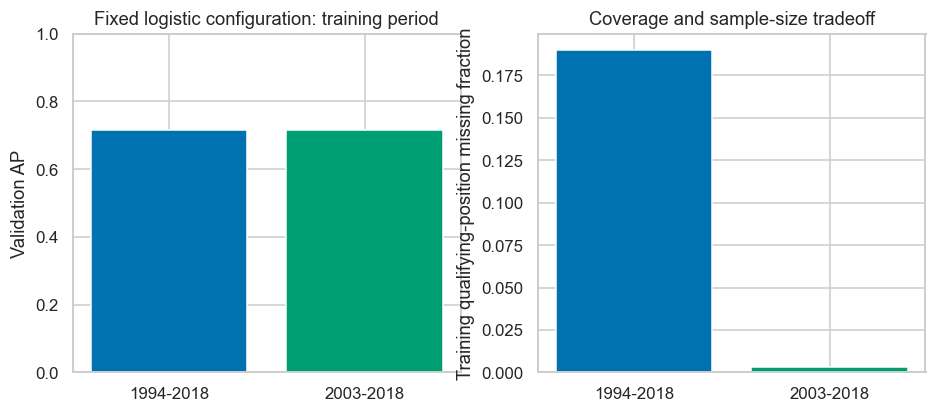

In [19]:
recent_train_mask = train_rows["year"].ge(2003).to_numpy()
recent_preprocessing = fit_preprocessing(X_train.loc[recent_train_mask])
recent_lr = LogisticRegression(**best_configs["Logistic regression"], max_iter=2000, random_state=SEED)
recent_lr.fit(transform_frame(X_train.loc[recent_train_mask], recent_preprocessing), y_train[recent_train_mask])
recent_probabilities = recent_lr.predict_proba(transform_frame(X_val, recent_preprocessing))[:, 1]
recent_threshold = choose_threshold(y_val, recent_probabilities)
coverage_sensitivity = pd.DataFrame([
    {"training_window": "1994-2018", "training_rows": len(X_train),
     "qualifying_missing_rate": float(X_train.qualifying_position.isna().mean()),
     **metric_row(y_val, validation_probabilities["Logistic regression"], full_lr_threshold)},
    {"training_window": "2003-2018", "training_rows": int(recent_train_mask.sum()),
     "qualifying_missing_rate": float(X_train.loc[recent_train_mask].qualifying_position.isna().mean()),
     **metric_row(y_val, recent_probabilities, recent_threshold)},
])
coverage_sensitivity_table = coverage_sensitivity
coverage_sensitivity.to_csv(TABLES / "training_window_sensitivity.csv", index=False)
coverage_ap_delta = float(coverage_sensitivity.iloc[1].AP - coverage_sensitivity.iloc[0].AP)
display(coverage_sensitivity)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(coverage_sensitivity.training_window, coverage_sensitivity.AP, color=["#0072b2", "#009e73"])
axes[0].set(ylabel="Validation AP", title="Fixed logistic configuration: training period", ylim=(0, 1))
axes[1].bar(coverage_sensitivity.training_window, coverage_sensitivity.qualifying_missing_rate, color=["#0072b2", "#009e73"])
axes[1].set(ylabel="Training qualifying-position missing fraction", title="Coverage and sample-size tradeoff")
savefig("training_window_sensitivity.png", "Validation-only 1994 versus 2003 training-window sensitivity, using fixed logistic hyperparameters and validation rows. Era, sample size and qualifying coverage all change together.")
model_figures.append("training_window_sensitivity.png")

### 4.4 Freeze choices, then score the future-season holdout

Choose each threshold using validation F1 and the final model using validation
AP. Save those decisions BEFORE computing holdout predictions. Models retain
their training-only weights so these thresholds refer to the same models.
Refitting on train plus validation would require a new calibration/checkpoint
design. The holdout is scored once below; no later code tunes from it.

,model,split,ROC_AUC,AP,PR_AUC,F1,precision,recall,Brier,threshold
0,Logistic regression,train,0.9219,0.6441,0.6437,0.6288,0.5045,0.8344,0.0709,0.2064
1,Logistic regression,validation,0.9327,0.7146,0.7128,0.7225,0.6345,0.8389,0.0655,0.2064
2,Logistic regression,test,0.9358,0.7094,0.7084,0.6769,0.5549,0.8676,0.0707,0.2064
3,Random forest,train,0.9608,0.7990,0.7989,0.7256,0.6803,0.7773,0.0558,0.3682
4,Random forest,validation,0.9417,0.7432,0.7408,0.7352,0.6842,0.7944,0.0627,0.3682
5,Random forest,test,0.9373,0.6967,0.6953,0.6826,0.6133,0.7696,0.0700,0.3682
6,Shallow neural network,train,0.9283,0.6641,0.6639,0.6502,0.5988,0.7112,0.0695,0.3471
7,Shallow neural network,validation,0.9375,0.7487,0.7476,0.7352,0.6842,0.7944,0.0646,0.3471
8,Shallow neural network,test,0.9383,0.7110,0.7097,0.6682,0.6425,0.6961,0.0700,0.3471


**Validation-selected model:** Shallow neural network. Frozen threshold **0.3471**. Scores below are final holdout evaluation; the selected model is retained even if another model scores higher on test.

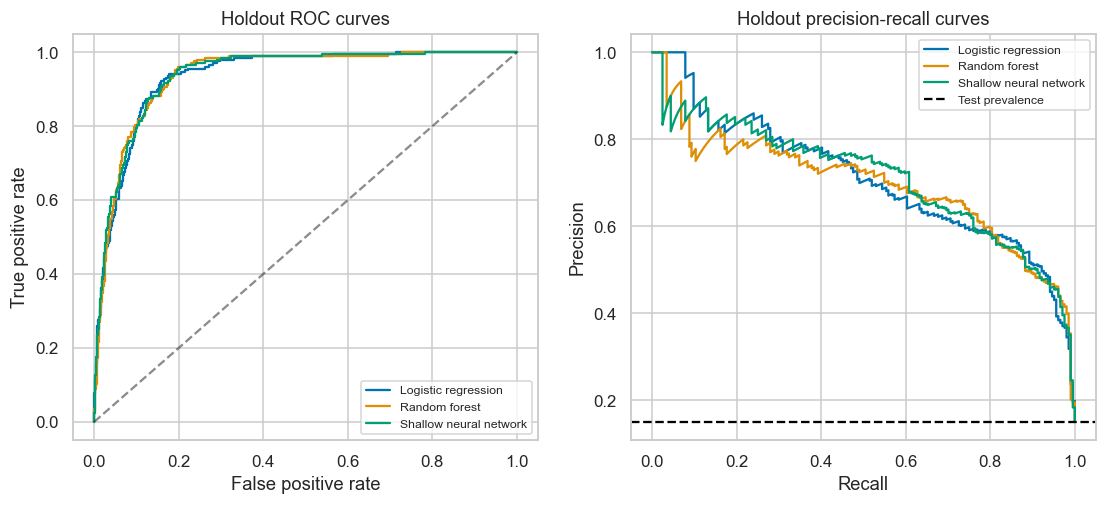

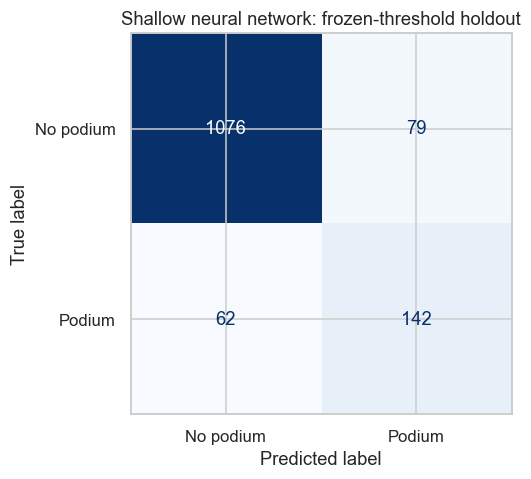

In [20]:
thresholds = {name: choose_threshold(y_val, p) for name, p in validation_probabilities.items()}
final_model_name = max(validation_probabilities,
    key=lambda name: average_precision_score(y_val, validation_probabilities[name]))
final_threshold = thresholds[final_model_name]
selection_frozen = {"selected_model": final_model_name, "thresholds": thresholds,
                    "best_configs": best_configs, "features": FEATURES,
                    "training_rows": len(X_train), "validation_rows": len(X_val),
                    "selection_rule": "Validation AP; thresholds maximize validation F1; primary preprocessing unchanged",
                    "frozen_at_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())}
(OUT / "selection_frozen.json").write_text(json.dumps(selection_frozen, indent=2), encoding="utf-8")


def probability_for_model(name, frame):
    inputs = transform_frame(frame, preprocessing)
    if name == "Shallow neural network":
        return models[name](inputs.astype(np.float32), training=False).numpy().ravel()
    return models[name].predict_proba(inputs)[:, 1]


metrics_records, test_probabilities = [], {}
for name in models:
    for split_name, frame, labels in [("train", X_train, y_train),
                                      ("validation", X_val, y_val), ("test", X_test, y_test)]:
        probabilities = validation_probabilities[name] if split_name == "validation" else probability_for_model(name, frame)
        if split_name == "test":
            test_probabilities[name] = probabilities
        metrics_records.append({"model": name, "split": split_name,
                                **metric_row(labels, probabilities, thresholds[name])})
metrics_table = pd.DataFrame(metrics_records)
assert len(metrics_table) == 9 and metrics_table.notna().all().all()
metrics_table.to_csv(TABLES / "metrics.csv", index=False)
display(metrics_table.round(4))
display(Markdown(f"**Validation-selected model:** {final_model_name}. Frozen threshold "
                 f"**{final_threshold:.4f}**. Scores below are final holdout evaluation; "
                 "the selected model is retained even if another model scores higher on test."))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for name, probabilities in test_probabilities.items():
    false_positive, true_positive, _ = roc_curve(y_test, probabilities)
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    axes[0].plot(false_positive, true_positive, label=name)
    axes[1].plot(recall, precision, label=name)
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1].axhline(y_test.mean(), color="black", ls="--", label="Test prevalence")
axes[0].set(title="Holdout ROC curves", xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(title="Holdout precision-recall curves", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.legend(fontsize=8)
savefig("holdout_curves.png", "2022-2024 ROC and precision-recall curves of all three frozen models; model choice uses validation AP only.")
model_figures.append("holdout_curves.png")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, test_probabilities[final_model_name] >= final_threshold,
    display_labels=["No podium", "Podium"], ax=ax, colorbar=False, cmap="Blues")
ax.set_title(f"{final_model_name}: frozen-threshold holdout")
savefig("holdout_confusion_matrix.png", "Holdout confusion matrix for the validation-selected model and its frozen validation-F1 threshold.")
model_figures.append("holdout_confusion_matrix.png")

### 4.5 Explain the selected model globally and locally (Lab 4)

Permutation importance uses sklearn's library implementation: shuffle one
original validation feature and measure the loss in AP, over eight repeats.
SHAP uses a seeded training background and a validation sample stratified by
season in proportion to each season's row count, without consulting labels.
The local case is appended only for explanation, not to global averages/plots.
Sampling membership and season counts are exported. TreeExplainer
explains forest podium probability; LinearExplainer explains logistic log-odds;
if the network wins, KernelExplainer approximates its podium probability.
Only the branch for the actual selected model is run. The input representation
always matches the fitted estimator: imputed, indicator-augmented and scaled.

The local case is selected without its outcome: validation probability nearest
0.5. SHAP waterfall and LIME explain that SAME row. SHAP units are stated and
its additive reconstruction is checked. LIME's local surrogate R-squared is
reported. SHAP displays standardized inputs. LIME displays imputed values in
original racing units and applies the frozen scaler inside its probability
wrapper. Binary inputs and missing flags are categorical 0/1 values for LIME,
so their individual states remain valid when perturbed.

**Interpretation:** beeswarm sign indicates an increase/decrease in the model's
output relative to its background; red means a larger standardized input, blue
a smaller one. Waterfall adds local contributions to the background. Neither
SHAP, permutation, nor LIME establishes causal effects. Correlated qualifying,
grid, form and standings share information. Independent perturbations can
create unrealistic feature combinations (including a grid/flag mismatch), and
importance may understate redundant feature groups. LIME fidelity measures
local approximation quality, not predictive correctness or causality.

,feature,AP_drop_mean,AP_drop_std
0,grid,0.142484,0.025276
2,qualifying_position,0.086507,0.021982
7,driver_prior_starts,0.028641,0.013414
10,driver_standing_points,0.025656,0.013539
4,driver_form_podium_rate,0.025652,0.026656
18,round,0.020802,0.010443
9,constructor_form_points,0.018149,0.012400
12,constructor_standing_points,0.014936,0.007001
6,driver_form_finish,0.008747,0.009304
14,driver_age,0.007987,0.005985


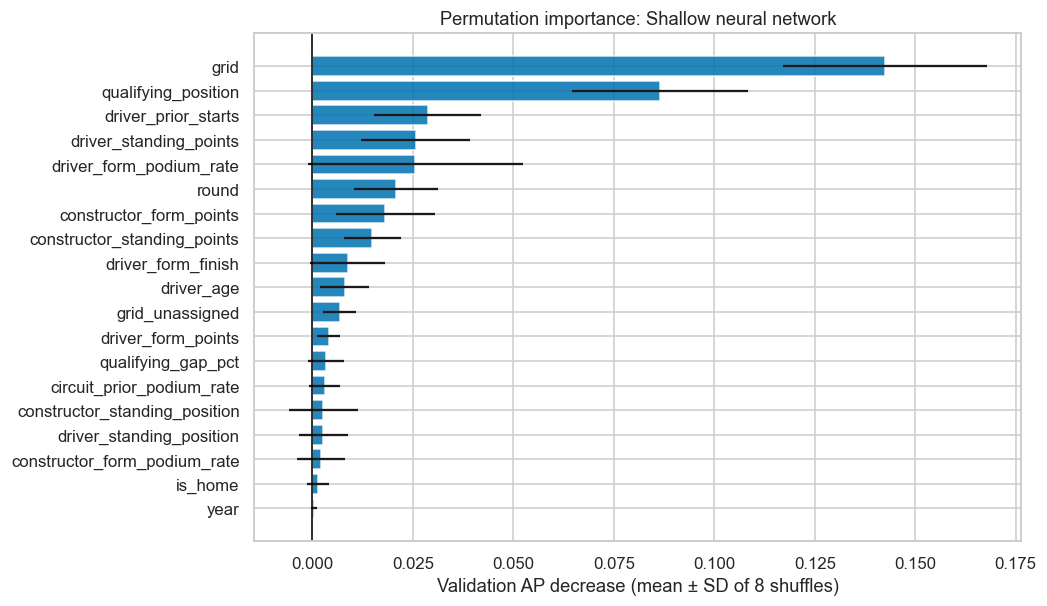

,year,validation_rows,global_sample_rows,validation_fraction,global_sample_fraction
0,2019,420,21,0.350000,0.350000
1,2020,340,17,0.283333,0.283333
2,2021,440,22,0.366667,0.366667


,feature,mean_abs_SHAP
0,grid,0.065401
2,qualifying_position,0.050436
4,driver_form_podium_rate,0.025342
17,year,0.022910
10,driver_standing_points,0.018890
7,driver_prior_starts,0.015396
18,round,0.012338
13,constructor_standing_position,0.011587
8,constructor_form_podium_rate,0.011249
14,driver_age,0.008124


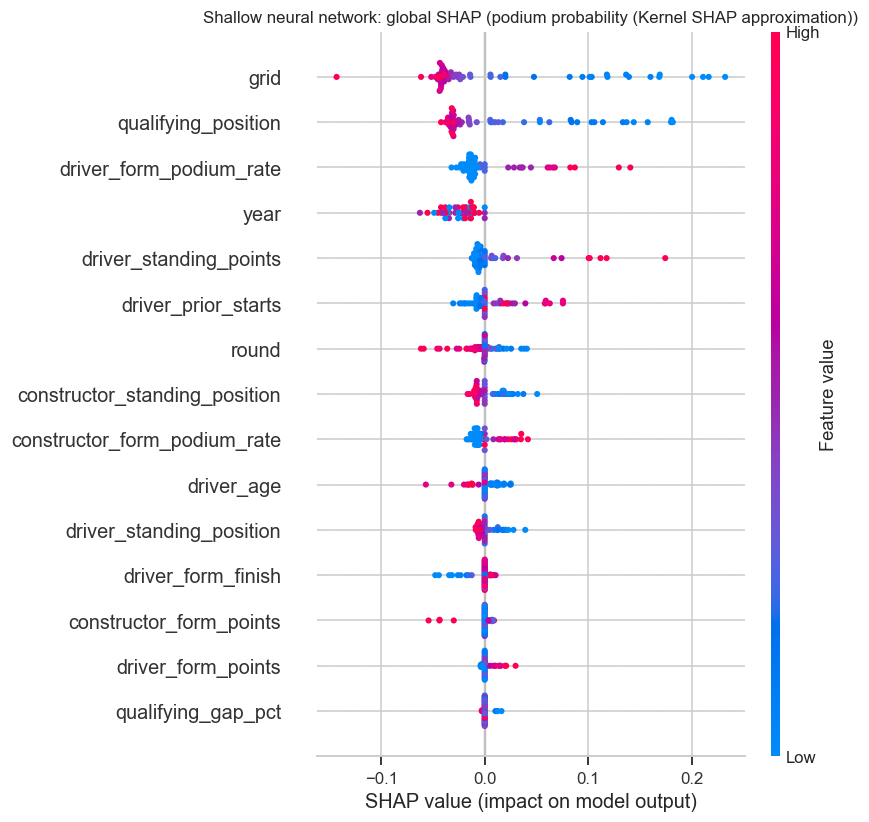

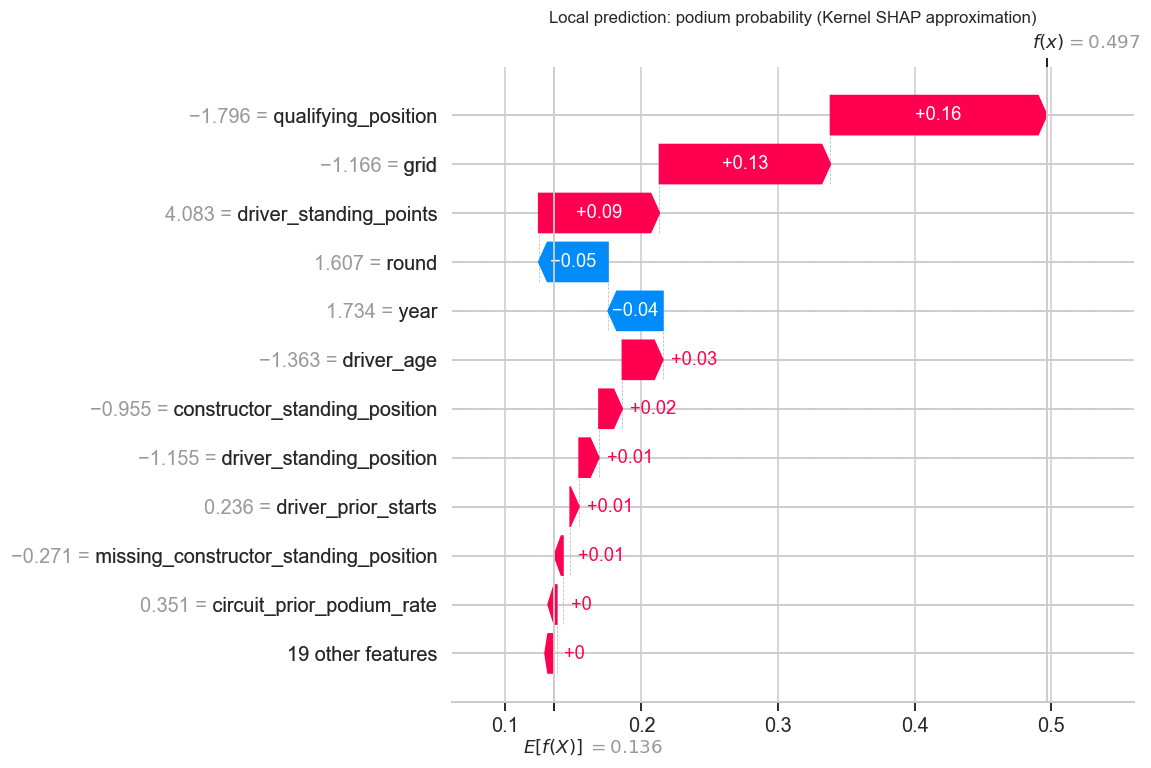

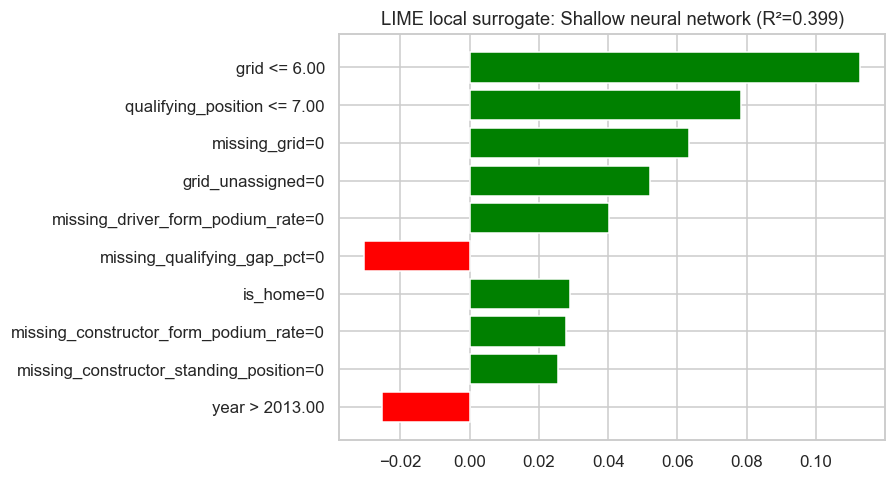

Local case: **{'raceId': 1027, 'driverId': 830, 'year': 2019.0, 'round': 18.0}**; predicted podium probability **0.497**, observed label **0**, frozen threshold **0.347**. SHAP reconstruction **0.497** (absolute error 0.000000); LIME surrogate R² **0.399**. Explanations describe model association, not causality.

654

In [21]:
import shap
from lime.lime_tabular import LimeTabularExplainer

explained_model_name = final_model_name
selected_estimator = models[final_model_name]
selected_preprocessor = preprocessing
selected_probability = lambda frame: probability_for_model(final_model_name, frame)


def selected_ap_scorer(estimator, original_frame, labels):
    inputs = transform_frame(original_frame, preprocessing)
    if final_model_name == "Shallow neural network":
        positive = estimator(inputs.astype(np.float32), training=False).numpy().ravel()
    else:
        positive = estimator.predict_proba(inputs)[:, 1]
    return average_precision_score(labels, positive)


importance = permutation_importance(selected_estimator, X_val, y_val,
    scoring=selected_ap_scorer, n_repeats=8, random_state=SEED, n_jobs=1)
permutation_table = pd.DataFrame({"feature": FEATURES,
    "AP_drop_mean": importance.importances_mean,
    "AP_drop_std": importance.importances.std(axis=1, ddof=1)}).sort_values("AP_drop_mean", ascending=False)
permutation_table.to_csv(TABLES / "permutation_importance.csv", index=False)
display(permutation_table)
fig, ax = plt.subplots(figsize=(9, 6))
ordered = permutation_table.iloc[::-1]
ax.barh(ordered.feature, ordered.AP_drop_mean, xerr=ordered.AP_drop_std, color="#0072b2", alpha=0.85)
ax.axvline(0, color="black", lw=1)
ax.set(xlabel="Validation AP decrease (mean ± SD of 8 shuffles)",
       title=f"Permutation importance: {final_model_name}")
savefig("permutation_importance.png", "Global validation permutation importance of original inputs, scored through the frozen preprocessing/model. Bars are eight seeded AP-loss shuffles; error bars are sample SD.")
model_figures.append("permutation_importance.png")

explanation_train, explanation_val = Z_train, Z_val
xai_rng = np.random.default_rng(SEED)
background_indices = xai_rng.choice(len(X_train), size=min(80, len(X_train)), replace=False)
sample_budget = min(60 if final_model_name == "Shallow neural network" else 120, len(X_val))
validation_years = val_rows["year"].to_numpy(dtype=int)
year_counts = pd.Series(validation_years).value_counts().sort_index()
ideal_year_counts = sample_budget * year_counts / year_counts.sum()
sample_year_counts = np.floor(ideal_year_counts).astype(int)
remainder = sample_budget - int(sample_year_counts.sum())
for sample_year in (ideal_year_counts - sample_year_counts).sort_values(
        ascending=False, kind="stable").index[:remainder]:
    sample_year_counts.loc[sample_year] += 1
global_sample_indices = np.concatenate([
    xai_rng.choice(np.flatnonzero(validation_years == sample_year), size=int(count), replace=False)
    for sample_year, count in sample_year_counts.items()
])
assert len(global_sample_indices) == sample_budget
local_index = int(np.argmin(np.abs(validation_probabilities[final_model_name] - 0.5)))
sample_indices = np.unique(np.r_[global_sample_indices, local_index])
global_sample_mask = np.isin(sample_indices, global_sample_indices)
background = explanation_train[background_indices]
explanation_sample = explanation_val[sample_indices]
shap_sample = val_rows.iloc[sample_indices][["raceId", "driverId", "year", "date"]].copy()
shap_sample.insert(0, "validation_position", sample_indices)
shap_sample["included_global"] = global_sample_mask
shap_sample["included_local"] = sample_indices == local_index
shap_sample.to_csv(TABLES / "shap_sample.csv", index=False)
shap_sampling_table = pd.DataFrame({"year": year_counts.index,
    "validation_rows": year_counts.values, "global_sample_rows": sample_year_counts.values})
shap_sampling_table["validation_fraction"] = shap_sampling_table.validation_rows / len(X_val)
shap_sampling_table["global_sample_fraction"] = shap_sampling_table.global_sample_rows / sample_budget
shap_sampling_table.to_csv(TABLES / "shap_sample_by_year.csv", index=False)
display(shap_sampling_table)
shap_sampling_description = ", ".join(
    f"{int(row.year)}: {int(row.global_sample_rows)}" for row in shap_sampling_table.itertuples())


def transformed_probability(array):
    """LIME/SHAP already supply the fitted estimator's transformed inputs."""
    if final_model_name == "Shallow neural network":
        positive = selected_estimator(np.asarray(array, dtype=np.float32), training=False).numpy().ravel()
        return np.column_stack([1 - positive, positive])
    return selected_estimator.predict_proba(np.asarray(array, dtype=float))


if final_model_name == "Random forest":
    shap_explainer = shap.TreeExplainer(selected_estimator, data=background,
        model_output="probability", feature_perturbation="interventional")
    values = shap_explainer.shap_values(explanation_sample, check_additivity=False)
    # Older SHAP returns one array per class; newer releases append the class axis.
    shap_values = np.asarray(values[1] if isinstance(values, list) else values[:, :, 1])
    shap_base = float(np.asarray(shap_explainer.expected_value)[1])
    shap_units = "podium probability"
elif final_model_name == "Logistic regression":
    shap_explainer = shap.LinearExplainer(selected_estimator, background)
    shap_values = np.asarray(shap_explainer.shap_values(explanation_sample))
    shap_base = float(np.asarray(shap_explainer.expected_value).ravel()[0])
    shap_units = "log-odds"
else:
    shap_explainer = shap.KernelExplainer(lambda inputs: transformed_probability(inputs)[:, 1], background)
    shap_values = np.asarray(shap_explainer.shap_values(explanation_sample,
        nsamples=250, l1_reg="num_features(12)", silent=True))
    shap_base = float(shap_explainer.expected_value)
    shap_units = "podium probability (Kernel SHAP approximation)"

global_shap_values = shap_values[global_sample_mask]
global_explanation_sample = explanation_sample[global_sample_mask]
shap_table = pd.DataFrame({"feature": transformed_names,
    "mean_abs_SHAP": np.mean(np.abs(global_shap_values), axis=0)}).sort_values("mean_abs_SHAP", ascending=False)
shap_table.to_csv(TABLES / "shap_importance.csv", index=False)
display(shap_table.head(12))
plt.figure(figsize=(10, 6))
shap.summary_plot(global_shap_values, global_explanation_sample, feature_names=transformed_names, show=False, max_display=15, rng=np.random.default_rng(SEED))
plt.title(f"{final_model_name}: global SHAP ({shap_units})", fontsize=11)
savefig("shap_global.png", f"Global SHAP for the validation-selected {final_model_name}; season-proportional seeded validation sample ({shap_sampling_description}). The separately selected local case does not enter global summaries. Attribution units: {shap_units}; background is training-only.")
model_figures.append("shap_global.png")

local_sample_index = int(np.flatnonzero(sample_indices == local_index)[0])
local_values = shap_values[local_sample_index]
local_explanation_object = shap.Explanation(values=local_values, base_values=shap_base,
    data=explanation_val[local_index], feature_names=transformed_names)
shap.plots.waterfall(local_explanation_object, max_display=12, show=False)
plt.title(f"Local prediction: {shap_units}", fontsize=11)
savefig("shap_local_waterfall.png", "Local SHAP waterfall for the validation probability nearest 0.5, selected without consulting its true label. The same case is explained with LIME.")
model_figures.append("shap_local_waterfall.png")
local_shap_table = pd.DataFrame({"feature": transformed_names,
    "value_transformed": explanation_val[local_index], "SHAP": local_values})
local_shap_table = local_shap_table.sort_values("SHAP", key=lambda series: series.abs(), ascending=False)
local_shap_table.to_csv(TABLES / "local_shap.csv", index=False)

lime_train = append_missing_flags(X_train.fillna(preprocessing["medians"]), X_train,
                                  preprocessing["indicator_features"]).to_numpy()
lime_local = append_missing_flags(X_val.fillna(preprocessing["medians"]), X_val,
                                  preprocessing["indicator_features"]).iloc[local_index].to_numpy()


def lime_probability(imputed_inputs):
    """Scale LIME's imputed, original-unit features exactly once before prediction."""
    completed = pd.DataFrame(imputed_inputs, columns=transformed_names)
    scaled_inputs = preprocessing["scaler"].transform(completed)
    return transformed_probability(scaled_inputs)


np.testing.assert_allclose(lime_probability(lime_local.reshape(1, -1))[0, 1],
                            validation_probabilities[final_model_name][local_index], atol=1e-6)
lime_explainer = LimeTabularExplainer(lime_train, feature_names=transformed_names,
    class_names=["No podium", "Podium"], mode="classification", discretize_continuous=True,
    categorical_features=protected_indices, random_state=SEED)
lime_explanation = lime_explainer.explain_instance(lime_local, lime_probability,
    labels=(1,), num_features=10, num_samples=3000)
lime_table = pd.DataFrame(lime_explanation.as_list(label=1), columns=["condition", "local_weight"])
lime_table.to_csv(TABLES / "lime_local.csv", index=False)
lime_explanation.save_to_file(str(OUT / "lime_local_explanation.html"))
fig = lime_explanation.as_pyplot_figure(label=1)
plt.title(f"LIME local surrogate: {final_model_name} (R²={lime_explanation.score:.3f})")
savefig("lime_local.png", "LIME on the same validation case as local SHAP. Conditions are imputed original-unit values with binary flags; a wrapper applies frozen scaling. The title reports local surrogate R-squared.")
model_figures.append("lime_local.png")
local_metadata = val_rows.iloc[local_index][["raceId", "driverId", "year", "round"]].to_dict()
local_probability = float(validation_probabilities[final_model_name][local_index])
local_actual = int(y_val[local_index])
shap_reconstruction = float(shap_base + local_values.sum())
if final_model_name == "Logistic regression":
    shap_reconstruction = float(1 / (1 + np.exp(-shap_reconstruction)))
shap_reconstruction_error = abs(shap_reconstruction - local_probability)
assert shap_reconstruction_error < (0.03 if final_model_name == "Shallow neural network" else 0.005)
display(Markdown(f"Local case: **{local_metadata}**; predicted podium probability "
    f"**{local_probability:.3f}**, observed label **{local_actual}**, frozen threshold "
    f"**{final_threshold:.3f}**. SHAP reconstruction **{shap_reconstruction:.3f}** "
    f"(absolute error {shap_reconstruction_error:.6f}); LIME surrogate R² "
    f"**{lime_explanation.score:.3f}**. Explanations describe model association, not causality."))
(OUT / "explanation_checks.json").write_text(json.dumps({"model": final_model_name,
    "raceId": int(local_metadata["raceId"]), "driverId": int(local_metadata["driverId"]),
    "local_probability": local_probability, "shap_reconstruction": shap_reconstruction,
    "shap_absolute_error": shap_reconstruction_error, "shap_units": shap_units,
    "lime_R2": float(lime_explanation.score), "background_split": "train",
    "explanation_split": "validation", "seed": SEED,
    "global_sample_method": "Season-proportional stratified random sample without replacement; labels unused",
    "global_sample_rows": int(sample_budget),
    "global_sample_by_year": {str(year): int(count) for year, count in sample_year_counts.items()},
    "local_only_excluded_from_global": True}, indent=2), encoding="utf-8")

### 4.6 Inference, missing inputs, and native persistence

predict_podium(record) consumes numeric **engineered pre-race features**, in
the feature catalog's units. It is not a raw-name/history lookup: rolling
features and standings must already exclude the requested race. Missing fields
and nulls use frozen training medians and indicators, and are reported back.
Omitted/null/nonpositive grid becomes missing and derives grid_unassigned=1;
positive grid derives 0. Supplied contradictory flags, unknown keys, malformed
numbers and nonfinite values, including NaN, are rejected. Omitted keys and
None represent missing external inputs. Extensive imputation reduces reliability.

Demos use a complete historical validation record, then remove qualifying and
standings fields, then remove grid and its flag. These do not select models.
Export uses ordinary joblib preprocessing/sklearn artifacts and Keras's native
.keras serialization. Predictions from EVERY reloaded model are checked
against the in-memory fitted model; neural inference uses Keras load_model().

In [22]:
def predict_podium(record):
    """Predict one podium probability from documented engineered pre-race inputs."""
    if not isinstance(record, dict):
        raise TypeError("record must be a dictionary of numeric pre-race features.")
    unknown = sorted(set(record) - set(FEATURES))
    if unknown:
        raise ValueError(f"Unknown feature keys: {unknown}. Allowed keys: {FEATURES}")
    normalized = dict(record)
    raw_grid = normalized.get("grid")
    if raw_grid is None:
        normalized_grid = None
    else:
        try:
            normalized_grid = float(raw_grid)
        except (ValueError, TypeError) as error:
            raise ValueError("grid must be a number or null.") from error
        if not np.isfinite(normalized_grid):
            raise ValueError("grid must be finite or null.")
        if normalized_grid <= 0:
            normalized_grid = None
    derived_flag = int(normalized_grid is None)
    supplied_flag = normalized.get("grid_unassigned")
    if supplied_flag is not None:
        try:
            supplied_flag_number = float(supplied_flag)
        except (TypeError, ValueError) as error:
            raise ValueError("grid_unassigned must be 0 or 1, matching grid.") from error
        if not np.isfinite(supplied_flag_number):
            raise ValueError("grid_unassigned must be finite or null.")
        if supplied_flag_number != derived_flag:
            raise ValueError(f"grid_unassigned={supplied_flag} contradicts grid={raw_grid}; expected {derived_flag}.")
    normalized["grid"], normalized["grid_unassigned"] = normalized_grid, derived_flag
    values, missing = {}, []
    for feature in FEATURES:
        value = normalized.get(feature)
        if value is None:
            values[feature] = np.nan
            missing.append(feature)
        else:
            try:
                number = float(value)
            except (TypeError, ValueError) as error:
                raise ValueError(f"{feature} must be a number or null.") from error
            if not np.isfinite(number):
                raise ValueError(f"{feature} must be finite or null.")
            values[feature] = number
    probability = float(selected_probability(pd.DataFrame([values], columns=FEATURES))[0])
    return {"model": final_model_name, "podium_probability": probability,
            "podium_prediction": int(probability >= final_threshold),
            "threshold": float(final_threshold), "imputed_features": missing,
            "note": "Missing inputs use training medians and missingness flags."
                    if missing else "All engineered inputs supplied."}


complete_positions = np.flatnonzero(~X_val.isna().any(axis=1))
assert len(complete_positions), "Complete demo must be an actual fully observed record."
complete_record = {f: float(v) for f, v in X_val.iloc[int(complete_positions[0])].items()}
partial_record = {key: value for key, value in complete_record.items()
                  if "qualifying" not in key and "standing" not in key}
missing_grid_record = {key: value for key, value in complete_record.items()
                       if key not in ["grid", "grid_unassigned"]}
inference_complete = predict_podium(complete_record)
inference_partial = predict_podium(partial_record)
inference_missing_grid = predict_podium(missing_grid_record)
inference_examples = pd.DataFrame([{"example": "complete", **inference_complete},
    {"example": "partially missing", **inference_partial},
    {"example": "missing grid", **inference_missing_grid}])
display(inference_examples)
inference_examples.to_csv(TABLES / "inference_examples.csv", index=False)
(OUT / "inference_demo_inputs.json").write_text(json.dumps({"complete": complete_record,
    "partial": partial_record, "missing_grid": missing_grid_record}, indent=2, allow_nan=False), encoding="utf-8")
zero_grid_result = predict_podium({**complete_record, "grid": 0, "grid_unassigned": 1})
negative_grid_result = predict_podium({**complete_record, "grid": -1, "grid_unassigned": 1})
null_grid_result = predict_podium({**complete_record, "grid": None, "grid_unassigned": None})
for result in [zero_grid_result, negative_grid_result, null_grid_result]:
    np.testing.assert_allclose(result["podium_probability"], inference_missing_grid["podium_probability"])
    assert result["imputed_features"] == ["grid"]
assert inference_missing_grid["imputed_features"] == ["grid"]
assert not predict_podium({f: v for f, v in complete_record.items() if f != "grid_unassigned"})["imputed_features"]
invalid_records = [({**complete_record, "grid": 0, "grid_unassigned": 0}, "contradicts"),
                   ({**complete_record, "unrecognized": 1}, "Unknown"),
                   ({**complete_record, "grid": np.inf}, "finite"),
                   ({**complete_record, "grid": np.nan}, "finite"),
                   ({**complete_record, "grid_unassigned": np.inf}, "finite"),
                   ({**complete_record, "grid_unassigned": np.nan}, "finite"),
                   ({**complete_record, "driver_age": np.inf}, "finite"),
                   ({**complete_record, "driver_age": np.nan}, "finite"),
                   ({**complete_record, "grid": "bad"}, "number")]
for invalid_record, expected_message in invalid_records:
    try:
        predict_podium(invalid_record)
    except (ValueError, TypeError) as error:
        assert expected_message in str(error)
    else:
        raise AssertionError("Invalid inference record was accepted.")
print("Inference checks passed: complete/partial/grid cases and invalid-input rejection.")

# Native library artifacts share one explicit training-fitted preprocessing bundle.
joblib.dump(preprocessing, MODELS_DIR / "preprocessing.joblib")
joblib.dump(models["Logistic regression"], MODELS_DIR / "logistic_regression.joblib")
joblib.dump(models["Random forest"], MODELS_DIR / "random_forest.joblib")
nn_model.save(MODELS_DIR / "shallow_neural_network.keras")
import sklearn
metadata = {"selected_model": final_model_name, "features": FEATURES,
    "threshold": float(final_threshold), "all_thresholds": thresholds,
    "transformed_features": transformed_names,
    "indicator_features": preprocessing["indicator_features"],
    "feature_groups": FEATURE_GROUPS, "training_years": [1994, 2018],
    "validation_years": [2019, 2021], "test_years": [2022, 2024],
    "best_configs": best_configs, "seed": SEED,
    "feature_semantics": "Engineered post-qualifying pre-race inputs; histories exclude current race. Omitted/null/grid<=0 is missing; grid_unassigned derived; contradictory flags fail.",
    "versions": {"numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__,
                 "tensorflow": tf.__version__, "keras": keras.__version__, "shap": shap.__version__},
    "training_medians": {f: float(preprocessing["medians"][f]) for f in FEATURES},
    "model_files": {"Logistic regression": "logistic_regression.joblib",
                    "Random forest": "random_forest.joblib", "Shallow neural network": "shallow_neural_network.keras"}}
(MODELS_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

reloaded_preprocessing = joblib.load(MODELS_DIR / "preprocessing.joblib")
reload_inputs = transform_frame(X_val.iloc[:25], reloaded_preprocessing)
reload_checks = []
for name, filename in [("Logistic regression", "logistic_regression.joblib"),
                       ("Random forest", "random_forest.joblib")]:
    reloaded = joblib.load(MODELS_DIR / filename)
    probabilities = reloaded.predict_proba(reload_inputs)[:, 1]
    reference = validation_probabilities[name][:len(reload_inputs)]
    np.testing.assert_allclose(probabilities, reference, rtol=1e-8, atol=1e-9)
    reload_checks.append({"model": name, "rows": len(reload_inputs),
                          "maximum_absolute_error": float(np.max(np.abs(probabilities - reference))), "passed": True})
reloaded_nn = keras.models.load_model(MODELS_DIR / "shallow_neural_network.keras", compile=False)
reloaded_neural_probability = reloaded_nn(reload_inputs.astype(np.float32), training=False).numpy().ravel()
neural_reference = validation_probabilities["Shallow neural network"][:len(reload_inputs)]
np.testing.assert_allclose(reloaded_neural_probability, neural_reference, rtol=1e-6, atol=1e-7)
reload_checks.append({"model": "Shallow neural network", "rows": len(reload_inputs),
    "maximum_absolute_error": float(np.max(np.abs(reloaded_neural_probability - neural_reference))), "passed": True})
reload_parity_table = pd.DataFrame(reload_checks)
reload_parity_table.to_csv(TABLES / "reload_parity.csv", index=False)
display(reload_parity_table)
print("Native export verification passed for all three models and the shared preprocessing.")

,example,model,podium_probability,podium_prediction,threshold,imputed_features,note
0,complete,Shallow neural network,0.595058,1,0.34711,[],All engineered inputs supplied.
1,partially missing,Shallow neural network,0.459572,1,0.34711,"[qualifying_position, qualifying_gap_pct, driv...",Missing inputs use training medians and missin...
2,missing grid,Shallow neural network,0.026343,0,0.34711,[grid],Missing inputs use training medians and missin...


Inference checks passed: complete/partial/grid cases and invalid-input rejection.


,model,rows,maximum_absolute_error,passed
0,Logistic regression,25,0.000000e+00,True
1,Random forest,25,1.387779e-17,True
2,Shallow neural network,25,1.862645e-09,True


Native export verification passed for all three models and the shared preprocessing.


### 4.7 Measured findings and practical limits

The summary below is generated from this run's actual results. Holdout
performance describes 2022-2024 retrospectively, not a future accuracy promise.
Weather, tyres, race conditions and strategy are absent. Repeated experiments
can overfit one validation era. Binary probabilities do not enforce exactly
three predicted podiums per race, and are not externally calibrated. SHAP and
LIME explain predictive associations, not interventions or causal racing effects.

In [23]:
winner_val_ap = float(average_precision_score(y_val, validation_probabilities[final_model_name]))
test_metric_dict = metric_row(y_test, test_probabilities[final_model_name], final_threshold)
worst_ablation = ablation_table.iloc[1:].sort_values("delta_AP").iloc[0]
improved_groups = ablation_table.loc[(ablation_table.group_removed != "None (all features)") & ablation_table.delta_AP.gt(0), "group_removed"].tolist()
prep_lookup = preprocessing_table.set_index("order")
order_a_delta = float(prep_lookup.loc["A1: scale → impute", "AP"] - prep_lookup.loc["A0: impute → scale (baseline)", "AP"])
order_b_delta = float(prep_lookup.loc["B1: impute → scale → clip", "AP"] - prep_lookup.loc["B0: clip → impute → scale", "AP"])
top_permutation = ", ".join(permutation_table.head(3).feature)
top_shap = ", ".join(shap_table.head(3).feature)
local_positive = local_shap_table.loc[local_shap_table.SHAP > 0].head(2).feature.tolist()
local_negative = local_shap_table.loc[local_shap_table.SHAP < 0].head(2).feature.tolist()
modeling_summary = {
    "winner": final_model_name, "threshold": float(final_threshold),
    "validation_AP": winner_val_ap, "test_metrics": test_metric_dict, "best_configs": best_configs,
    "ablation_conclusion": f"Removing {worst_ablation['group_removed']} yielded the lowest AP difference ({worst_ablation['delta_AP']:+.4f}) relative to full logistic regression. Groups whose removal improved AP: {', '.join(improved_groups) or 'none'}. Correlation, regularization and sampling affect these descriptive comparisons.",
    "preprocessing_conclusion": f"Scaling before imputation changed validation AP by {order_a_delta:+.4f}. Impute → scale → clip changed AP by {order_b_delta:+.4f} versus clip → impute → scale. For {distribution_feature} ({int(X_train[distribution_feature].isna().sum())} training missing values), the maximum absolute A1/A0 transformed-value difference was {order_a_value_change:.4f}. All {len(protected_indices)} binary/indicator columns were preserved in both clipping orders. The primary comparison retained impute → scale.",
    "coverage_sensitivity_conclusion": f"Training logistic regression on 2003-2018 instead of 1994-2018 changed validation AP by {coverage_ap_delta:+.4f}, with the same estimator configuration and validation rows. Qualifying-position missingness changed from {coverage_sensitivity.iloc[0]['qualifying_missing_rate']:.1%} to {coverage_sensitivity.iloc[1]['qualifying_missing_rate']:.1%}. Sample size and era change too; this does not isolate the effect of qualifying coverage. Primary training remains 1994-2018.",
    "xai_conclusion": f"Leading permutation features: {top_permutation}. Leading mean absolute SHAP features: {top_shap}. SHAP units: {shap_units}; global validation sample size {sample_budget}, stratified in proportion to season counts ({shap_sampling_description}). Sampling uses no outcomes. A separately appended local-only case is excluded from global averages and beeswarm plots. Correlated inputs can share or substitute information; independent perturbations may form unrealistic combinations. None of these measures establishes causality.",
    "local_explanation": f"Same local case for both explainers: validation raceId={int(local_metadata['raceId'])}, driverId={int(local_metadata['driverId'])}; probability={local_probability:.3f}, actual podium={local_actual}, threshold={final_threshold:.3f}. Positive SHAP contributors: {', '.join(local_positive) or 'none'}; negative contributors: {', '.join(local_negative) or 'none'}. Reconstruction={shap_reconstruction:.3f} (absolute error {shap_reconstruction_error:.6f}); LIME local surrogate R²={lime_explanation.score:.3f}. SHAP displays scaled values; LIME displays imputed original-unit values and binary flags, with frozen scaling inside its prediction wrapper.",
    "inference_conclusion": f"Complete-record probability={inference_complete['podium_probability']:.3f}; partially missing={inference_partial['podium_probability']:.3f}, with {len(inference_partial['imputed_features'])} fields filled using training medians. Missing-grid probability={inference_missing_grid['podium_probability']:.3f}; only grid is imputed and its flag derives as 1. Null/zero/negative grid agree; contradictory flags, unknown keys and nonfinite numbers are rejected. All three native reloaded models match the original predictions. Inputs are engineered pre-race features, not raw names or lookup queries.",
    "limitations": "One chronological validation period; repeated validation experiments can overfit; historical regulation/scoring/qualifying drift; no external probability calibration; independent binary calls need not produce exactly three podiums; absent weather, tyre and strategy inputs; observational importance and home association are not causal.",
    "explained_model": explained_model_name, "shap_units": shap_units,
    "lime_R2": float(lime_explanation.score), "model_seconds": float(time.perf_counter() - model_start),
    "neural_implementation": "Keras Sequential, one hidden ReLU layer, one sigmoid output; binary cross-entropy, Adam, exact validation-AP callback before EarlyStopping with best-weight restoration; native .keras persistence",
}
modeling_summary['local_explanation'] += (
    f" The local surrogate explains about {100 * lime_explanation.score:.1f}% of the weighted "
    "variation in its sampled neighborhood. "
    + ("Substantial unexplained variation limits this LIME explanation; treat its feature weights as approximate."
       if lime_explanation.score < 0.7 else
       "Its neighborhood fit does not establish predictive correctness or causal effects.")
)
(OUT / "modeling_summary.json").write_text(json.dumps(modeling_summary, indent=2), encoding="utf-8")
display(Markdown(f"**Validation winner:** {final_model_name}, AP {winner_val_ap:.3f}. "
    f"**2022-2024 holdout:** ROC-AUC {test_metric_dict['ROC_AUC']:.3f}, AP {test_metric_dict['AP']:.3f}, "
    f"trapezoidal PR-AUC {test_metric_dict['PR_AUC']:.3f}, F1 {test_metric_dict['F1']:.3f}, "
    f"precision {test_metric_dict['precision']:.3f}, recall {test_metric_dict['recall']:.3f}.\n\n" +
    "\n\n".join(modeling_summary[key] for key in ["ablation_conclusion", "preprocessing_conclusion",
        "coverage_sensitivity_conclusion", "xai_conclusion", "local_explanation", "inference_conclusion"])))

**Validation winner:** Shallow neural network, AP 0.749. **2022-2024 holdout:** ROC-AUC 0.938, AP 0.711, trapezoidal PR-AUC 0.710, F1 0.668, precision 0.643, recall 0.696.

Removing grid yielded the lowest AP difference (-0.0174) relative to full logistic regression. Groups whose removal improved AP: standings, context. Correlation, regularization and sampling affect these descriptive comparisons.

Scaling before imputation changed validation AP by +0.0002. Impute → scale → clip changed AP by +0.0010 versus clip → impute → scale. For qualifying_gap_pct (1987 training missing values), the maximum absolute A1/A0 transformed-value difference was 10.2573. All 13 binary/indicator columns were preserved in both clipping orders. The primary comparison retained impute → scale.

Training logistic regression on 2003-2018 instead of 1994-2018 changed validation AP by +0.0018, with the same estimator configuration and validation rows. Qualifying-position missingness changed from 19.0% to 0.3%. Sample size and era change too; this does not isolate the effect of qualifying coverage. Primary training remains 1994-2018.

Leading permutation features: grid, qualifying_position, driver_prior_starts. Leading mean absolute SHAP features: grid, qualifying_position, driver_form_podium_rate. SHAP units: podium probability (Kernel SHAP approximation); global validation sample size 60, stratified in proportion to season counts (2019: 21, 2020: 17, 2021: 22). Sampling uses no outcomes. A separately appended local-only case is excluded from global averages and beeswarm plots. Correlated inputs can share or substitute information; independent perturbations may form unrealistic combinations. None of these measures establishes causality.

Same local case for both explainers: validation raceId=1027, driverId=830; probability=0.497, actual podium=0, threshold=0.347. Positive SHAP contributors: qualifying_position, grid; negative contributors: round, year. Reconstruction=0.497 (absolute error 0.000000); LIME local surrogate R²=0.399. SHAP displays scaled values; LIME displays imputed original-unit values and binary flags, with frozen scaling inside its prediction wrapper. The local surrogate explains about 39.9% of the weighted variation in its sampled neighborhood. Substantial unexplained variation limits this LIME explanation; treat its feature weights as approximate.

Complete-record probability=0.595; partially missing=0.460, with 6 fields filled using training medians. Missing-grid probability=0.026; only grid is imputed and its flag derives as 1. Null/zero/negative grid agree; contradictory flags, unknown keys and nonfinite numbers are rejected. All three native reloaded models match the original predictions. Inputs are engineered pre-race features, not raw names or lookup queries.

## 5. Focused analytical report

The report contains only the three requested areas: the three data-engineering
answers with supporting figures, selected features and cutoff validity, and
known limitations. Detailed implementation evidence remains in the notebook.

In [24]:
from datetime import datetime, timezone
import html
import json
import re
import unicodedata

from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER, TA_LEFT
from reportlab.lib.pagesizes import A4, landscape
from reportlab.lib.styles import ParagraphStyle, getSampleStyleSheet
from reportlab.lib.units import inch
from reportlab.platypus import (
    BaseDocTemplate, Frame, Image as PDFImage, KeepTogether, NextPageTemplate,
    PageBreak, PageTemplate, Paragraph, Spacer, Table as PDFTable, TableStyle,
)
from reportlab.lib.utils import ImageReader

report_dir = OUT / "pdf"
report_dir.mkdir(parents=True, exist_ok=True)
report_pdf_path = report_dir / "analytical_report.pdf"
report_md_path = OUT / "analytical_report.md"
report_tables_dir = OUT / "tables"
report_styles = getSampleStyleSheet()
report_ink = colors.HexColor("#142536")
report_blue = colors.HexColor("#175578")
report_light = colors.HexColor("#EDF3F7")
report_muted = colors.HexColor("#5A6B79")
report_styles.add(ParagraphStyle(
    name="ReportTitle", fontName="Helvetica-Bold", fontSize=31,
    leading=36, textColor=report_ink, spaceAfter=22,
))
report_styles.add(ParagraphStyle(
    name="ReportSubtitle", fontName="Helvetica", fontSize=13,
    leading=19, textColor=report_muted, spaceAfter=13,
))
report_styles.add(ParagraphStyle(
    name="ReportH1", fontName="Helvetica-Bold", fontSize=17,
    leading=21, textColor=report_blue, spaceBefore=12, spaceAfter=12,
    keepWithNext=True,
))
report_styles.add(ParagraphStyle(
    name="ReportH2", fontName="Helvetica-Bold", fontSize=11,
    leading=15, textColor=report_ink, spaceBefore=11, spaceAfter=6,
    keepWithNext=True,
))
report_styles.add(ParagraphStyle(
    name="ReportBody", fontName="Helvetica", fontSize=9.4,
    leading=13.2, textColor=report_ink, spaceAfter=8,
))
report_styles.add(ParagraphStyle(
    name="ReportSmall", fontName="Helvetica", fontSize=8,
    leading=11, textColor=report_muted, spaceAfter=6,
))
report_styles.add(ParagraphStyle(
    name="ReportCell", fontName="Helvetica", fontSize=7.1,
    leading=9.5, textColor=report_ink,
))
report_styles.add(ParagraphStyle(
    name="ReportCellHead", fontName="Helvetica-Bold", fontSize=7.2,
    leading=9.5, textColor=colors.white,
))
report_styles.add(ParagraphStyle(
    name="ReportCaption", fontName="Helvetica", fontSize=8,
    leading=11, textColor=report_muted, spaceAfter=8,
))
report_story = []
report_markdown = []
report_page_width, report_page_height = A4
report_width = report_page_width - 96


def report_ascii(value):
    """Use portable glyphs in the PDF's built-in fonts."""
    text_value = str(value)
    replacements = {
        "\u2013": "-", "\u2014": "-", "\u2011": "-", "\u2212": "-",
        "\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"',
        "\u2264": "<=", "\u2265": ">=", "\u2192": " -> ",
        "\u0394": "delta ", "\u00d7": " x ", "\u00b1": "+/-",
    }
    for original, replacement in replacements.items():
        text_value = text_value.replace(original, replacement)
    return unicodedata.normalize("NFKD", text_value).encode("ascii", "ignore").decode("ascii")


def report_paragraph(value, style="ReportBody"):
    safe_text = html.escape(report_ascii(value)).replace("\n", "<br/>")
    return Paragraph(safe_text, report_styles[style])


def report_heading(title, level=1, page_break=False):
    if page_break:
        report_story.append(PageBreak())
    report_story.append(report_paragraph(title, "ReportH1" if level == 1 else "ReportH2"))
    report_markdown.append("\n" + "#" * (level + 1) + " " + str(title) + "\n")


def report_text(value):
    if value is None or str(value).strip() == "":
        return
    report_story.append(report_paragraph(value))
    report_markdown.append(str(value) + "\n")


def report_read_table(filename):
    table_path = report_tables_dir / filename
    assert table_path.exists(), f"Required report evidence missing: {table_path}"
    return pd.read_csv(table_path)


def report_value(value):
    if value is None:
        return "-"
    try:
        if pd.isna(value):
            return "-"
    except (TypeError, ValueError):
        pass
    if isinstance(value, (float, np.floating)):
        if abs(value) < 1e5:
            return f"{value:.4f}".rstrip("0").rstrip(".")
        return f"{value:,.0f}"
    if isinstance(value, (int, np.integer)):
        return f"{value:,}"
    return report_ascii(value)


def report_add_table(frame, title=None, columns=None, max_rows=24, widths=None):
    if frame is None or frame.empty:
        return
    frame = frame.copy()
    if columns:
        available = [column for column in columns if column in frame.columns]
        if available:
            frame = frame[available]
    total_rows = len(frame)
    if max_rows is not None:
        frame = frame.head(max_rows)
    if title:
        report_heading(title, level=2)
    # Table cells wrap instead of overflowing; repeated headers survive page breaks.
    pdf_rows = [[report_paragraph(c.replace("_", " "), "ReportCellHead") for c in frame.columns]]
    for values in frame.itertuples(index=False, name=None):
        pdf_rows.append([report_paragraph(report_value(v), "ReportCell") for v in values])
    if widths is None:
        sample_lengths = [
            max(len(str(column)), min(45, frame[column].astype(str).str.len().quantile(.75)))
            for column in frame.columns
        ]
        weights = np.maximum(np.array(sample_lengths, dtype=float), 8)
        widths = list(report_width * weights / weights.sum())
    pdf_table = PDFTable(pdf_rows, colWidths=widths, repeatRows=1, hAlign="LEFT")
    pdf_table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), report_blue),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, report_light]),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("LEFTPADDING", (0, 0), (-1, -1), 5),
        ("RIGHTPADDING", (0, 0), (-1, -1), 5),
        ("TOPPADDING", (0, 0), (-1, -1), 5),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
        ("LINEBELOW", (0, 0), (-1, 0), .6, report_blue),
    ]))
    report_story.extend([pdf_table, Spacer(1, 8)])
    md_frame = frame.map(report_value)
    md_rows = ["| " + " | ".join(map(str, md_frame.columns)) + " |",
               "| " + " | ".join(["---"] * len(md_frame.columns)) + " |"]
    md_rows.extend("| " + " | ".join(str(v).replace("|", "/").replace("\n", " ") for v in row) + " |"
                   for row in md_frame.itertuples(index=False, name=None))
    report_markdown.append("\n".join(md_rows) + "\n")
    if total_rows > len(frame):
        note = f"Showing {len(frame)} of {total_rows} rows. The complete table is in output/tables."
        report_story.append(report_paragraph(note, "ReportSmall"))
        report_markdown.append(note + "\n")


def report_mapping_lines(mapping):
    if not isinstance(mapping, dict):
        return [str(mapping)] if mapping else []
    lines = []
    for key, value in mapping.items():
        if isinstance(value, (dict, list, tuple)):
            value = json.dumps(value, default=str, ensure_ascii=False)
        elif isinstance(value, (float, int, np.number)):
            value = report_value(value)
        lines.append(f"{str(key).replace('_', ' ').capitalize()}: {value}")
    return lines


def report_footer(canvas, doc):
    canvas.saveState()
    page_width, page_height = doc.pageTemplate.pagesize
    canvas.setStrokeColor(colors.HexColor("#CBD6DE"))
    canvas.setLineWidth(.5)
    canvas.line(48, 39, page_width - 48, 39)
    canvas.setFont("Helvetica", 7)
    canvas.setFillColor(report_muted)
    canvas.drawString(48, 27, "F1 Podium Prediction | Analytical report")
    canvas.drawRightString(page_width - 48, 27, f"{doc.page}")
    if doc.page > 1:
        canvas.drawString(48, page_height - 27, "RETROSPECTIVE EVIDENCE - PRE-RACE PREDICTION")
    canvas.restoreState()

In [25]:
# Keep the report focused on the three items required in the milestone brief.
report_analysis_summary = globals().get("analyses_summary", {})
report_catalog = globals().get("feature_catalog", pd.DataFrame())
report_generated = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")

report_story.extend([
    Spacer(1, 42),
    report_paragraph("FORMULA 1", "ReportSubtitle"),
    report_paragraph("Podium Prediction\nAnalytical Report", "ReportTitle"),
    report_paragraph("Data-engineering answers, pre-race features, and limitations", "ReportSubtitle"),
    Spacer(1, 18),
    report_paragraph("Target: podium finish (positionOrder <= 3).\nPrediction cutoff: after qualifying and before race start.\nUnit: one driver entering one race.", "ReportSubtitle"),
    Spacer(1, 18),
    report_paragraph(f"Generated from the executed notebook: {report_generated}", "ReportSmall"),
])
report_markdown.extend([
    "# Formula 1 Podium Prediction: Analytical Report\n",
    f"Generated from the executed notebook: {report_generated}\n",
    "Target: podium finish (positionOrder <= 3). Prediction cutoff: after qualifying and before race start. Unit: one driver entering one race.\n",
])


report_figure_count = 0

def report_add_figure(filename, caption, max_height=300):
    global report_figure_count
    report_figure_count += 1
    numbered_caption = f"Figure {report_figure_count}. {caption}"
    figure_path = FIG / filename
    assert figure_path.is_file(), f"Required report figure missing: {figure_path}"
    image_width, image_height = ImageReader(str(figure_path)).getSize()
    scale = min(report_width / image_width, max_height / image_height)
    figure = PDFImage(str(figure_path), width=image_width * scale, height=image_height * scale)
    figure.hAlign = "CENTER"
    report_story.append(KeepTogether([
        report_paragraph(numbered_caption, "ReportCaption"), figure, Spacer(1, 12),
    ]))
    report_markdown.append(f"**{numbered_caption}**\n\n![{caption}](figures/{filename})\n")


report_heading("1. Answers to the three data-engineering questions", page_break=True)
report_heading("1.1 Front-row starts and circuit podium conversion", level=2)
report_text("Qualifying positions 1-2 and final grid slots 1-2 are compared separately because penalties can change the starting grid. The comparison uses 490 races with both definitions observed, excluding 87 races without complete front-row support. Recorded nonstarters are excluded from the start denominator. Circuit-era rankings require adequate support and are descriptive.")
report_text(report_analysis_summary.get("q1", "See the front-row conversion figures."))
report_add_figure("q1_frontrow_circuits.png", "Circuit podium conversion from qualifying and actual grid front rows, with uncertainty intervals.", 285)
report_add_figure("q1_era_changes.png", "Change in front-row conversion across the 2014 era boundary for circuits with common support.", 260)

report_heading("1.2 Home-country podium association after grid control", level=2)
report_text("Home-country status is based on an explicit mapping from recorded driver nationality to circuit country. Home and away rates are standardized over the same observed exact-grid-position by era strata. Whole races are resampled for uncertainty, preserving dependence among competitors. This controls observed starting position and broad era, not driver or team strength.")
report_text(report_analysis_summary.get("q2", "See the standardized home-country comparison figure."))
report_add_figure("q2_home_advantage.png", "Crude and grid/era-standardized home and away podium rates with race-bootstrap intervals.", 280)

report_heading("1.3 Constructor mechanical retirements by era", level=2)
report_text("The denominator is race starts; the numerator requires an explicit mechanical component cause and fewer recorded laps than the winner as an early-end proxy. Crash, driver-caused, and regulatory outcomes are excluded from the mechanical numerator. Positive-lap withdrawals remain starts. Strict and broader cause maps are compared for 2014-2021 and 2022-2024.")
report_text(report_analysis_summary.get("q3", "See the constructor mechanical-retirement figure."))
report_add_figure("q3_constructor_reliability.png", "Constructor mechanical-retirement rates by era, with strict and broad definitions and uncertainty intervals.", 315)

report_heading("2. Selected features and pre-race validity", page_break=True)
report_text("The prediction cutoff is after qualifying and before the race starts. Every selected predictor is available by that cutoff or is derived solely from completed earlier races. Current-race results, points, status, laps, pit stops, and post-race standings are excluded. Driver and constructor histories are shifted so the current race cannot contribute to its own features.")
report_text("Feature selection combines training-period exploratory evidence with domain reasoning. The table lists every selected input, its motivation, and the information available at the cutoff. The accompanying figures show training-only associations and feature effects; these are exploratory evidence, not causal effects or proof that a feature improves the final model.")
if report_catalog.empty:
    report_catalog = report_read_table("feature_catalog.csv")
report_feature_table = report_catalog.copy()
report_feature_table["group"] = report_feature_table["group"].str.title()
report_add_table(
    report_feature_table,
    "Selected feature rationale and cutoff availability",
    columns=["feature", "group", "motivation", "availability"],
    max_rows=None,
    widths=[94, 62, 160, report_width - 316],
)
report_add_figure("11_feature_evidence.png", "Training-only missingness and univariate association evidence for selected features.", 280)
report_add_figure("12_feature_effects.png", "Observed feature effects and podium rates used to motivate feature groups.", 300)

report_heading("3. Known limitations", page_break=True)
report_text("Historical qualifying coverage is sparse and uneven. Analyses that require qualifying data use supported periods and common coverage, while the modeling sensitivity compares a shorter training window. Historical coverage and timing conventions may still change the observed relationships.")
report_text("Formula 1 rules, cars, calendars, scoring systems, constructor identities, and field composition change across eras. The 2014 boundary is a useful descriptive comparison, not an isolated causal experiment. A model trained on past seasons may transfer poorly after regulatory changes or to new drivers and teams.")
report_text("The archived final grid is treated as information available before the race. The archive does not provide a publication timestamp for every grid update; live use requires a genuine pre-start snapshot. Historical form and standings are only valid when constructed from completed earlier races.")
report_text("Home-country status is a nationality-based proxy, not residence or personal identification. The three data-engineering analyses are observational; unmeasured driver, team, circuit, and selection differences remain. Mechanical retirement labels and recorded lap counts are imperfect proxies, and constructor IDs do not automatically unify renamed teams.")
report_text("These limitations constrain interpretation and transfer. Plots and feature associations describe the supplied archive; they do not establish causes or guarantee future prediction performance.")

report_figure_paths = [FIG / name for name in [
    "q1_frontrow_circuits.png", "q1_era_changes.png", "q2_home_advantage.png",
    "q3_constructor_reliability.png", "11_feature_evidence.png", "12_feature_effects.png",
]]
report_caption_map = globals().get("FIG_CAPTIONS", {})
report_figure_manifest_names = [path.name for path in report_figure_paths]

report_document = BaseDocTemplate(
    str(report_pdf_path), pagesize=A4, rightMargin=48, leftMargin=48,
    topMargin=45, bottomMargin=52, title="Formula 1 Podium Prediction Companion",
    author="ACL Project", subject="Leakage-safe pre-race modeling and analytical evidence",
)
report_landscape_width, report_landscape_height = landscape(A4)
report_document.addPageTemplates([
    PageTemplate(id="Portrait", pagesize=A4,
                 frames=[Frame(48, 52, report_width, report_page_height - 97,
                               leftPadding=0, rightPadding=0, topPadding=0, bottomPadding=0)],
                 onPage=report_footer),
    PageTemplate(id="Landscape", pagesize=landscape(A4),
                 frames=[Frame(48, 52, report_landscape_width - 96, report_landscape_height - 97,
                               leftPadding=0, rightPadding=0, topPadding=0, bottomPadding=0)],
                 onPage=report_footer),
])
report_document.build(report_story)
report_md_path.write_text("\n".join(report_markdown), encoding="utf-8")
(OUT / "report_figure_manifest.json").write_text(json.dumps({
    "figure_count": len(report_figure_paths),
    "figures": [path.name for path in report_figure_paths],
    "report": str(report_pdf_path.relative_to(OUT)),
    "generated_utc": report_generated,
}, indent=2), encoding="utf-8")
assert report_pdf_path.exists() and report_pdf_path.stat().st_size > 0
assert report_md_path.exists()
print(f"Analytical PDF: {report_pdf_path.resolve()}")
print(f"Markdown report: {report_md_path.resolve()}")
print(f"Focused report includes {len(report_figure_paths)} supporting figures.")

Analytical PDF: C:\Users\ROG STRIX\Downloads\ACL Project\Deliverables\1- Notebook\output\pdf\analytical_report.pdf
Markdown report: C:\Users\ROG STRIX\Downloads\ACL Project\Deliverables\1- Notebook\output\analytical_report.md
Focused report includes 6 supporting figures.


### Report verification

A text-structure check below verifies that the PDF contains the expected
analytical sections. The report should also receive visual review before
submission: text extraction cannot detect clipped tables or unreadable figures.

In [26]:
import fitz

with fitz.open(report_pdf_path) as report_check:
    report_extracted = "\n".join(page.get_text() for page in report_check)
    report_required_headings = [
        "Answers to the three data-engineering questions",
        "Front-row starts and circuit podium conversion",
        "Home-country podium association after grid control",
        "Constructor mechanical retirements by era",
        "Selected features and pre-race validity", "Known limitations",
    ]
    for report_required in report_required_headings:
        assert report_required in report_extracted, f"Missing report section: {report_required}"
    report_check_pages = len(report_check)
print(f"Report structure verified: {report_check_pages} pages.")

Report structure verified: 7 pages.


## 6. Final checks and evidence manifest
These assertions check the executed results, not hard-coded expected scores.
They check the source bytes again, the prediction grain and chronological race
groups, every required model/experiment, and the complete report figure set.
The external delivery checker additionally reloads all three native models,
recomputes their scores, matches PDF images, and checks this notebook's sources.

In [27]:
assert raw_hashes == {name: hashlib.sha256((DATA / f'{name}.csv').read_bytes()).hexdigest()
                      for name in TABLE_NAMES}
assert not model_table.duplicated(['raceId', 'driverId']).any()
assert model_table.groupby('raceId').split.nunique().max() == 1
assert len(FEATURES) == 19 and len(metrics_table) == 9
assert set(metrics_table['split']) == {'train', 'validation', 'test'}
assert set(metrics_table['model']) == {'Logistic regression', 'Random forest', 'Shallow neural network'}
assert set(FEATURE_GROUPS).issubset(set(ablation_table.group_removed))
assert len(preprocessing_table) == 4
assert (MODELS_DIR / 'shallow_neural_network.keras').is_file()
assert (OUT / 'pdf' / 'analytical_report.pdf').stat().st_size > 10_000
assert not inference_complete['imputed_features']
assert inference_partial['imputed_features']
assert inference_missing_grid['imputed_features'] == ['grid']
assert all(0 <= demo['podium_probability'] <= 1
           for demo in [inference_complete, inference_partial, inference_missing_grid])
assert all((FIG / name).exists() for name in analysis_figures + model_figures)
assert len(FIG_CAPTIONS) == len(list(FIG.glob('*.png')))
assert start_evidence.loc[start_evidence.laps.gt(0), 'started'].all()
assert not a_reliability_all.loc[a_reliability_all.nonstarter, 'laps'].gt(0).any()
assert model_table.loc[model_table.nationality.isin(NATIONALITY_COUNTRIES), 'is_home'].notna().all()
assert shap_sample.included_global.sum() == sample_budget
assert (abs(sample_year_counts - ideal_year_counts) < 1).all()
verification = {
    'status': 'PASS', 'raw_csvs_unchanged': True, 'unique_driver_race_grain': True,
    'chronological_race_groups': True, 'historical_timestamp_checks': True,
    'model_rows': len(model_table), 'numeric_input_features': len(FEATURES),
    'model_split_metric_rows': len(metrics_table), 'ablation_groups': list(FEATURE_GROUPS),
    'preprocessing_variants': len(preprocessing_table), 'figure_count': len(FIG_CAPTIONS),
    'selected_model': final_model_name, 'selection_metric': 'validation average precision',
    'threshold': float(final_threshold), 'native_keras_model_saved': True,
    'grid_schema_consistent_between_training_and_inference': True,
    'mechanical_retirements_require_early_end_proxy': True,
    'positive_laps_override_withdrawal_labels': True,
    'start_label_conflict_rows': len(start_conflicts),
    'nationality_country_text_normalized': True,
    'global_shap_sample_season_proportional': True,
    'source_sha256': raw_hashes, 'dataset_directory': str(DATA.resolve()),
}
(OUT / 'verification.json').write_text(json.dumps(verification, indent=2), encoding='utf-8')
(OUT / 'figure_captions.json').write_text(json.dumps(FIG_CAPTIONS, indent=2), encoding='utf-8')
display(Markdown('**Notebook integrity checks passed.** All three attempts were fitted in this run. '
                 'Tables, plots, native model files, inference demonstrations, and the PDF are under output/. '
                 'Accessible Kaggle/GitHub publication, course-form submission, team preparation, '
                 'and evaluation-slot arrangements remain separate human steps.'))

**Notebook integrity checks passed.** All three attempts were fitted in this run. Tables, plots, native model files, inference demonstrations, and the PDF are under output/. Accessible Kaggle/GitHub publication, course-form submission, team preparation, and evaluation-slot arrangements remain separate human steps.